# Classification on UCI Mushrooms Dataset using PCA and Logistic Regression

In this notebook, we shall look into training a Logistic Regression model on the UCI Mushrooms dataset, and evaluate the effectiveness of it and Principal Component Analysis (PCA) on the data

# Imports

In [1]:
import math
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
import matplotlib.image as mpimg
from matplotlib.patches import Rectangle
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency, entropy
import json
import os
import sys
from IPython.display import Markdown, display
from sklearn.decomposition import KernelPCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (classification_report, accuracy_score, confusion_matrix, 
    precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, LabelBinarizer, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

# PART - A : Preliminary Exploration

Before we train any model on the data, we must first do a manual data exploration. This helps us to understand certain trends in the data, identify faults in it, pick suitable features and prepare a clean version of it.

## About the Data

In [2]:
df = pd.read_csv('data/mushrooms.csv', index_col=False)

### Attribute Information

In [3]:
# for i in list(df.columns):
#     # Get percentages using value_counts
#     percentages = df[i].value_counts(normalize=True) * 100
#     percentages.to_csv(f"data/{i}_percentages.csv")

The following tables show the distribution of categories within their respective features. We also give the complete name for each category value

In [3]:
md_contents = []
data_folder = './data/markdowns'
for data in os.listdir(data_folder):
    if data.endswith('.md'):
        with open(data_folder + '/' + data, 'r', encoding='utf-8') as file:
            markdown_content = file.read()
            md_contents.append(markdown_content)

        display(Markdown(markdown_content))

| veil-color | data-point   |   proportion |
|:-----------|:-------------|-------------:|
| white      |w             |   97.5382    |
| brown      | n            |    1.18168   |
| orange     | o            |    1.18168   |
| yellow     | y            |    0.0984737 |

| cap-color | data-point   |   proportion |
|:----------|:------------|-------------:|
| brown     | n           |    28.1142   |
| gray      | g           |    22.6489   |
| red       | e           |    18.4638   |
| yellow    | y           |    13.1955   |
| white     | w           |    12.8016   |
| buff      | b           |     2.06795  |
| pink      | p           |     1.77253  |
| cinnamon  | c           |     0.541605 |
| purple    | u           |     0.196947 |
| green     | r           |     0.196947 |

| gill-size | data-point   |   proportion |
|:----------|:------------|-------------:|
| broad     | b           |      69.0793 |
| narrow    | n           |      30.9207 |

| gill-color | data-point   |   proportion |
|:-----------|:-------------|-------------:|
| buff       | b            |    21.2703   |
| pink       | p            |    18.3653   |
| white      | w            |    14.7957   |
| brown      | n            |    12.9      |
| gray       | g            |     9.25652  |
| chocoloate | h            |     9.01034  |
| purple     | u            |     6.05613  |
| black      | k            |     5.02216  |
| red        | e            |     1.18168  |
| yellow     | y            |     1.05859  |
| orange     | o            |     0.787789 |
| green      | r            |     0.295421 |

| stalk-color-below-ring | data-point               |   proportion |
|:-----------------------|:-------------------------|-------------:|
| white                  | w                        |    53.9636   |
| pink                   | p                        |    23.0428   |
| gray                   | g                        |     7.0901   |
| green                  | n                        |     6.30231  |
| blue                   | b                        |     5.31758  |
| orange                 | o                        |     2.36337  |
| red                    | e                        |     1.18168  |
| cinnamon               | c                        |     0.443131 |
| yellow                 | y                        |     0.295421 |

| veil-type | data-point   |   proportion |
|:----------|:-------------|-------------:|
| partial   | p            |          100 |

... (13 outputs left out)

| ring-number | data-point    |   proportion |
|:------------|:--------------|-------------:|
| one         | o             |    92.1713   |
| two         | t             |     7.38552  |
| none        | n             |     0.443131 |

cap-surface | data-point   |   proportion |
|:----------|:--------------|-------------:|
| scaly     | y             |   39.9311    |
| smooth    | s             |   31.4623    |
| fibrous   | f             |   28.5574    |
| groovy    | g             |    0.0492368 |

| class     | data-point   |   proportion |
|:----------|:--------|-------------:|
| edible    | e       |      51.7971 |
| poisonous | p       |      48.2029 |

stalk-surface-below-ring | data-point                 |   proportion |
|:-----------------------|:---------------------------|-------------:|
| smooth                 | s                          |     60.7582  |
| silky                  | k                          |     28.3604  |
| fibrous                | f                          |      7.38552 |
| scaly                  | y                          |      3.49581 |

In [4]:
df.describe()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


Observations:
1. Gill Attachment has a highly skewed distribution with >97% free value.
3. Gill Spacing has a more skewed distribution than the class with > 83% close value.
4. Veil Color has a highly skewed distribution with >97% white value.
5. Veil Type has only one value.
6. Ring number has a highly skewed distribution with >92% one value
7. Ring number, Stalk shape, Gill spacing, Gill size is ordinal categorical data
8. Rest are Nominal Categorical data

Basic Hypotheses:
1. Gill Attachment has no say on the classes
2. Gill Spacing may not have a strong say on the classes (cannot be a single distinguishing factor)
3. Veil Color has no say on the classes
4. Gill Size may not have a strong say on the classes (cannot be a single distinguishing factor)
5. Veil Type has no say on the classes
6. Ring Number has no say on the classes

These hypotheses were formed observing the distribution of the data in these features and in the classes

In [109]:
possible_factors = ['cap-shape', 'cap-surface',
 'cap-color', 'bruises', 'odor', 'gill-color',
 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring',
 'stalk-color-above-ring', 'stalk-color-below-ring',
 'ring-type', 'spore-print-color', 'population', 'habitat']

### Data Visualization

Let us vizualise the data to gain further insights

#### Normalized Stacked Bar Chart

This will give the proportion of each feature value being in the classes

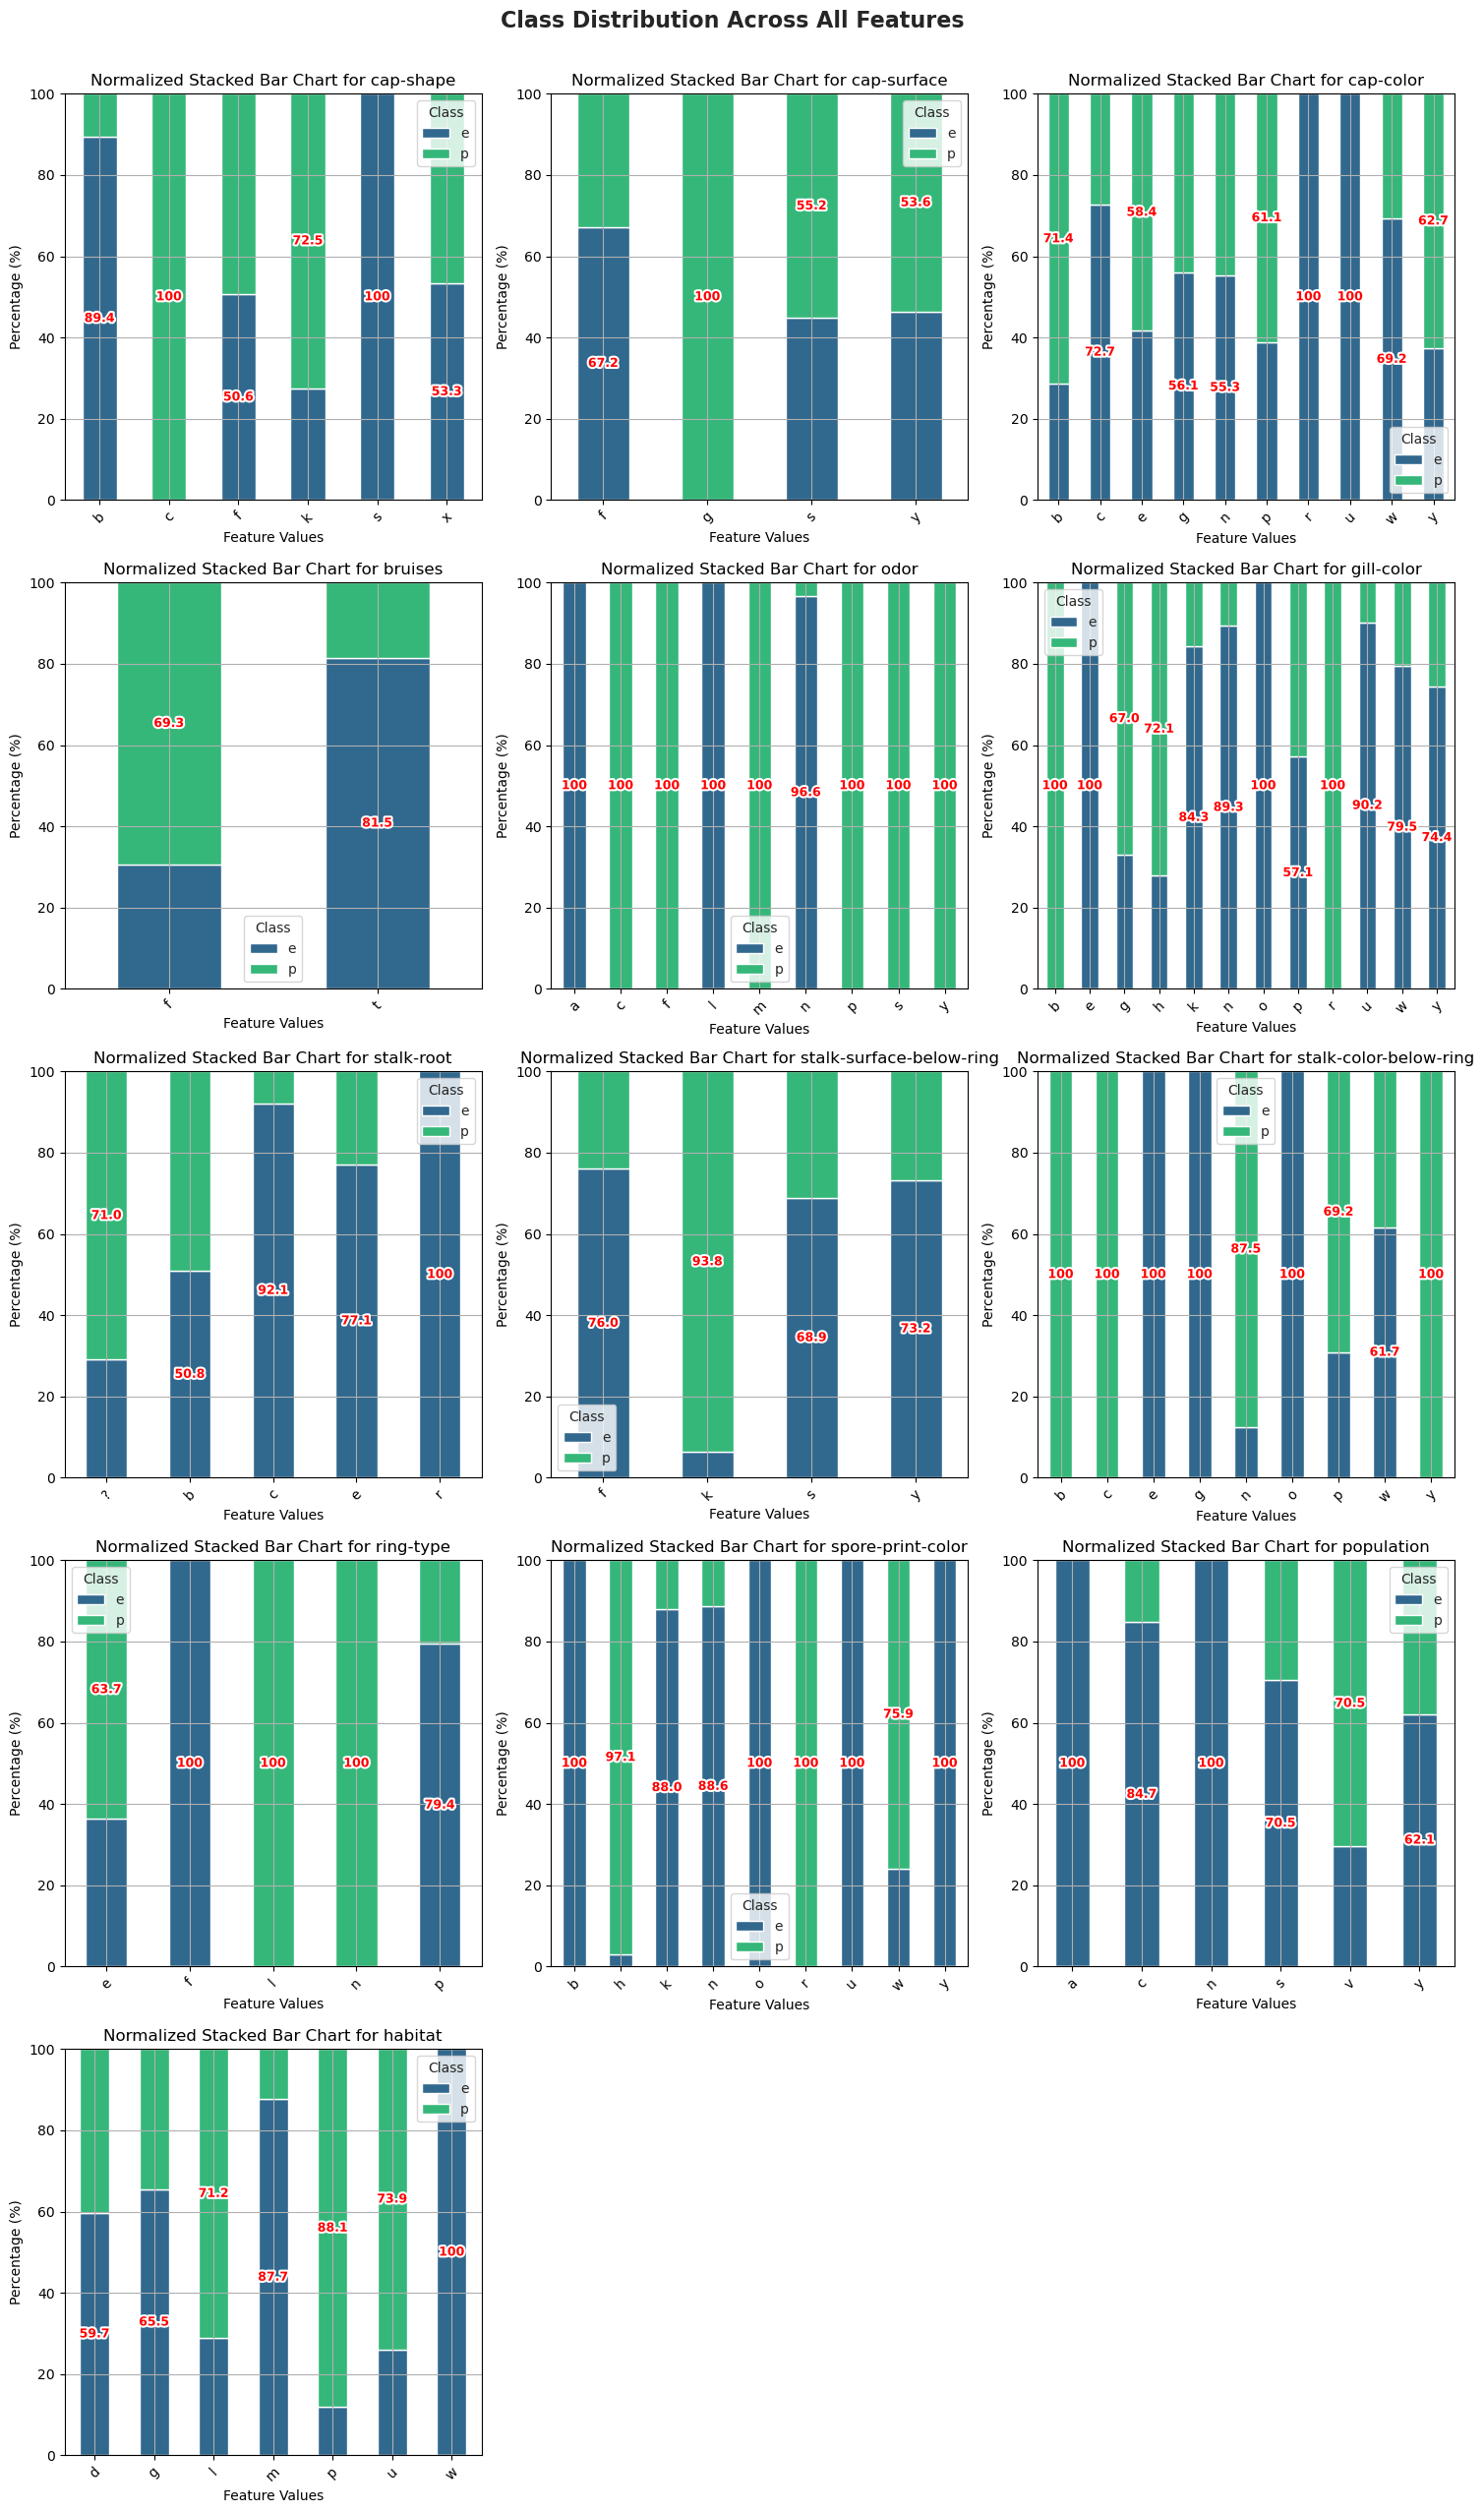

In [110]:
n_plots = len(possible_factors)
n_cols = 3
n_rows = (n_plots + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()
sns.set_style("whitegrid")
colors = sns.color_palette("viridis", 2)
for idx, given_feature in enumerate(possible_factors):
    ax = axes[idx]
    
    class_names = sorted(list(set(df['class'])))
    feature_names = sorted(list(set(df[given_feature])))
    cross_tab = pd.crosstab(df[given_feature], df['class'])
    cross_tab_norm = cross_tab.div(cross_tab.sum(axis=1), axis=0) * 100
    
    cross_tab_norm.plot(kind='bar', stacked=True, color=colors, ax=ax)
    ax.set_title(f'Normalized Stacked Bar Chart for {given_feature}')
    ax.set_xlabel('Feature Values')
    ax.set_ylabel('Percentage (%)')
    ax.legend(title='Class')
    ax.tick_params(axis='x', rotation=45)
    ax.set_ylim(0, 100)
    
    for container in ax.containers:
        labels = []
        for v in container.datavalues:
            if v == 100:
                labels.append(f'{int(v)}')
            elif v > 50:
                labels.append(f'{v:.1f}')
            else:
                labels.append('')
        label_objects = ax.bar_label(container, labels=labels, label_type='center', 
                                    fontsize=9, color='red', weight='bold')
        
        # Add white outline to each label
        for label in label_objects:
            if label.get_text():
                label.set_path_effects([
                    path_effects.Stroke(linewidth=3, foreground='white'),
                    path_effects.Normal()
                ])

for idx in range(n_plots, len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
fig.suptitle('Class Distribution Across All Features', fontsize=16, fontweight='bold', y=1.02)
plt.savefig('images/Class Distribution Across All Features.png')
plt.show()

Basic Observations:
1. Stalk-shape has almost equal distribution for both of its values
2. Bruises has a high tendency towards one class for each of its values.
3. Stalk-Surface-Above-Ring and Stalk-Surface-Below-Ring have similar plots.
4. Stalk-Color-Above-Ring and Stalk-Color-Below-Ring have similar plots.

Basic Hypotheses:
1. Stalk-shape has no say on the classes
2. Bruises has a strong effect on the classes
3. Stalk-Surface-Above-Ring & Stalk-Surface-Below-Ring are highly correlated features (only one of the two are needed for prediction)
4. Stalk-Color-Above-Ring & Stalk-Color-Below-Ring are highly correlated features (only one of the two are needed for prediction)

This is based on the distribution of the feature and the class

In [ ]:
for given_feature in possible_factors:
    cross_tab = pd.crosstab(df[given_feature], df['class'])
    cross_tab_norm = cross_tab.div(cross_tab.sum(axis=1), axis=0) * 100
    cross_tab_norm.to_csv(f'data/tables/analysis/class_dist_per_feature_value_{given_feature}.csv')

In [4]:
possible_factors.remove('stalk-shape')
possible_factors.remove('stalk-color-above-ring')
possible_factors.remove('stalk-surface-above-ring')
len(possible_factors)

13

#### Statistics about the data

Let us gain more statistical insight by using Information Gain, Gini Impurity, Chi square test and mutual Information indices on the data

In [ ]:
def calculate_information_gain(df, feature, target):
    """Calculate Information Gain"""
    target_counts = df[target].value_counts()
    target_entropy = entropy(target_counts, base=2)
    feature_values = df[feature].unique()
    weighted_entropy = 0
    total_samples = len(df)
    
    for value in feature_values:
        subset = df[df[feature] == value]
        subset_prob = len(subset) / total_samples
        subset_counts = subset[target].value_counts()
        subset_entropy = entropy(subset_counts, base=2) if len(subset_counts) > 1 else 0
        weighted_entropy += subset_prob * subset_entropy
    
    information_gain = target_entropy - weighted_entropy
    return information_gain

def calculate_mutual_information(df, feature, target):
    """Calculate Mutual Information using sklearn"""
    le_feature = LabelEncoder()
    le_target = LabelEncoder()
    
    feature_encoded = le_feature.fit_transform(df[feature])
    target_encoded = le_target.fit_transform(df[target])
    
    mi = mutual_info_classif(feature_encoded.reshape(-1, 1), target_encoded, 
                            discrete_features=True, random_state=42)[0]
    return mi

def calculate_chi_square(df, feature, target):
    """Calculate Chi-square test for independence"""
    cross_tab = pd.crosstab(df[feature], df[target])
    chi2, p_value, dof, expected = chi2_contingency(cross_tab)
    return chi2, p_value

def calculate_gini_reduction(df, feature, target):
    """Calculate Gini Impurity Reduction"""
    def gini_impurity(y):
        proportions = y.value_counts() / len(y)
        return 1 - sum(proportions**2)
    
    original_gini = gini_impurity(df[target])
    feature_values = df[feature].unique()
    weighted_gini = 0
    total_samples = len(df)
    
    for value in feature_values:
        subset = df[df[feature] == value]
        subset_weight = len(subset) / total_samples
        subset_gini = gini_impurity(subset[target])
        weighted_gini += subset_weight * subset_gini
    
    gini_reduction = original_gini - weighted_gini
    return gini_reduction

def calculate_visual_metrics(cross_tab_norm):
    """Calculate visual metrics from normalized cross-tabulation"""
    class_1_proportions = cross_tab_norm.iloc[:, 1].values
    
    variance = np.var(class_1_proportions)
    range_val = np.max(class_1_proportions) - np.min(class_1_proportions)
    extreme_score = np.sum((class_1_proportions < 20) | (class_1_proportions > 80)) / len(class_1_proportions)
    
    return variance, range_val, extreme_score

In [41]:
features_to_analyze = possible_factors
results = []

In [42]:
print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 80)
print(f"{'Feature':<10} {'Info Gain':<10} {'Mutual Info':<12} {'Chi2':<8} {'P-value':<10} {'Gini Red.':<10} {'Variance':<10} {'Range':<8} {'Extreme':<8}")
print("-" * 80)
for feature in features_to_analyze:
    # Statistical metrics
    info_gain = calculate_information_gain(df, feature, 'class')
    mutual_info = calculate_mutual_information(df, feature, 'class')
    chi2, p_value = calculate_chi_square(df, feature, 'class')
    gini_red = calculate_gini_reduction(df, feature, 'class')
    
    # Visual metrics from normalized stacked bar
    cross_tab = pd.crosstab(df[feature], df['class'])
    cross_tab_norm = cross_tab.div(cross_tab.sum(axis=1), axis=0) * 100
    variance, range_val, extreme_score = calculate_visual_metrics(cross_tab_norm)
    
    results.append({
        'feature': feature,
        'info_gain': info_gain,
        'mutual_info': mutual_info,
        'chi2': chi2,
        'p_value': p_value,
        'gini_reduction': gini_red,
        'variance': variance,
        'range': range_val,
        'extreme_score': extreme_score
    })
    
    print(f"{feature:<10} {info_gain:<10.3f} {mutual_info:<12.3f} {chi2:<8.1f} {p_value:<10.4f} {gini_red:<10.3f} {variance:<10.1f} {range_val:<8.1f} {extreme_score:<8.1f}")

FEATURE IMPORTANCE ANALYSIS
Feature    Info Gain  Mutual Info  Chi2     P-value    Gini Red.  Variance   Range    Extreme 
--------------------------------------------------------------------------------
cap-shape  0.049      0.034        489.9    0.0000     0.030      1165.7     100.0    0.5     
cap-surface 0.029      0.020        315.0    0.0000     0.019      601.1      67.2     0.2     
cap-color  0.036      0.025        387.6    0.0000     0.024      577.1      71.4     0.2     
bruises    0.192      0.133        2041.4   0.0000     0.126      646.5      50.9     0.5     
odor       0.906      0.628        7659.7   0.0000     0.471      2173.0     100.0    1.0     
gill-color 0.417      0.289        3765.7   0.0000     0.231      1258.7     100.0    0.6     
stalk-root 0.108      0.075        1059.1   0.0000     0.065      491.2      57.8     0.5     
stalk-surface-below-ring 0.272      0.188        2684.5   0.0000     0.165      834.5      69.8     0.2     
stalk-color-below-rin

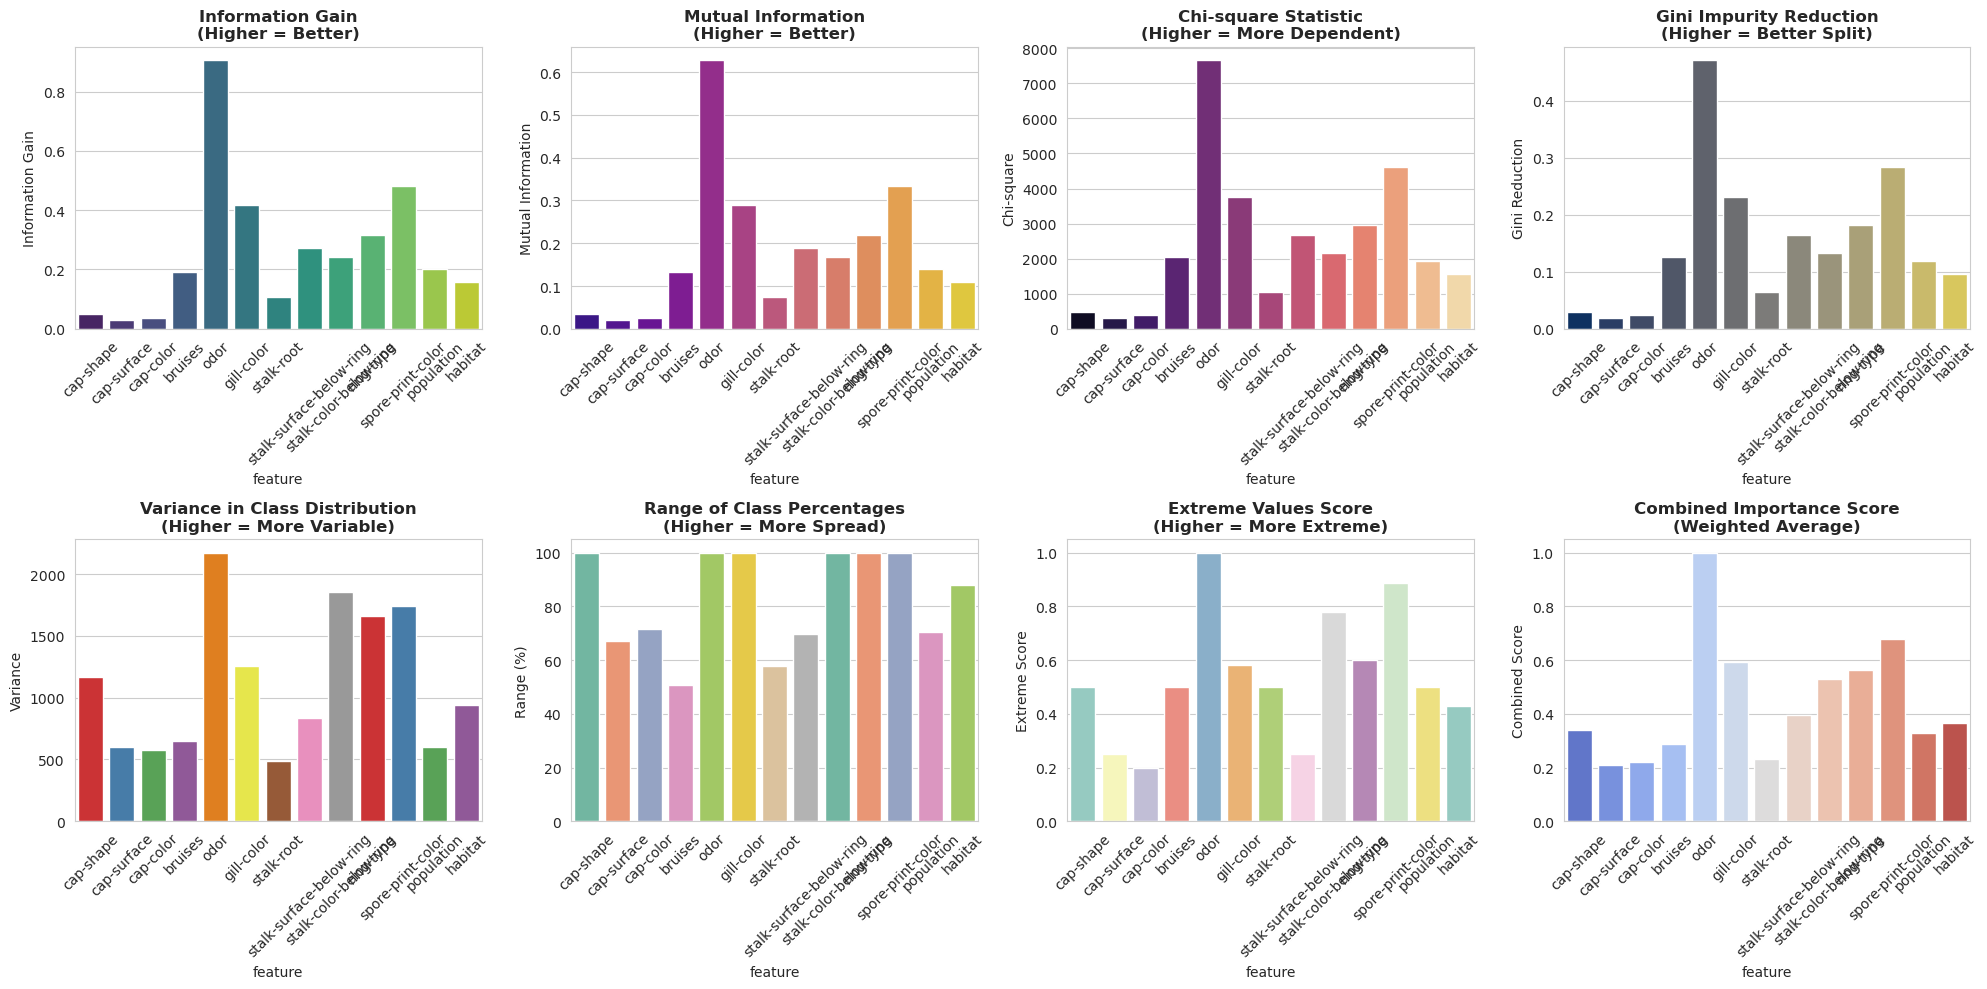

In [ ]:
results_df = pd.DataFrame(results)

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

# Information Gain
ax1 = axes[0, 0]
sns.barplot(data=results_df, x='feature', y='info_gain', palette='viridis', ax=ax1)
ax1.set_title('Information Gain\n(Higher = Better)', fontweight='bold')
ax1.set_ylabel('Information Gain')
ax1.tick_params(axis='x', rotation=45)

# Mutual Information
ax2 = axes[0, 1]
sns.barplot(data=results_df, x='feature', y='mutual_info', palette='plasma', ax=ax2)
ax2.set_title('Mutual Information\n(Higher = Better)', fontweight='bold')
ax2.set_ylabel('Mutual Information')
ax2.tick_params(axis='x', rotation=45)

# Chi-square statistic
ax3 = axes[0, 2]
sns.barplot(data=results_df, x='feature', y='chi2', palette='magma', ax=ax3)
ax3.set_title('Chi-square Statistic\n(Higher = More Dependent)', fontweight='bold')
ax3.set_ylabel('Chi-square')
ax3.tick_params(axis='x', rotation=45)

# Gini Reduction
ax4 = axes[0, 3]
sns.barplot(data=results_df, x='feature', y='gini_reduction', palette='cividis', ax=ax4)
ax4.set_title('Gini Impurity Reduction\n(Higher = Better Split)', fontweight='bold')
ax4.set_ylabel('Gini Reduction')
ax4.tick_params(axis='x', rotation=45)

# Variance
ax5 = axes[1, 0]
sns.barplot(data=results_df, x='feature', y='variance', palette='Set1', ax=ax5)
ax5.set_title('Variance in Class Distribution\n(Higher = More Variable)', fontweight='bold')
ax5.set_ylabel('Variance')
ax5.tick_params(axis='x', rotation=45)

# Range
ax6 = axes[1, 1]
sns.barplot(data=results_df, x='feature', y='range', palette='Set2', ax=ax6)
ax6.set_title('Range of Class Percentages\n(Higher = More Spread)', fontweight='bold')
ax6.set_ylabel('Range (%)')
ax6.tick_params(axis='x', rotation=45)

# Extreme Score
ax7 = axes[1, 2]
sns.barplot(data=results_df, x='feature', y='extreme_score', palette='Set3', ax=ax7)
ax7.set_title('Extreme Values Score\n(Higher = More Extreme)', fontweight='bold')
ax7.set_ylabel('Extreme Score')
ax7.tick_params(axis='x', rotation=45)

# Combined importance score
ax8 = axes[1, 3]
results_df['combined_score'] = (
    (results_df['info_gain'] / results_df['info_gain'].max()) * 0.3 +
    (results_df['mutual_info'] / results_df['mutual_info'].max()) * 0.3 +
    (results_df['variance'] / results_df['variance'].max()) * 0.2 +
    (results_df['range'] / results_df['range'].max()) * 0.2
)

sns.barplot(data=results_df, x='feature', y='combined_score', palette='coolwarm', ax=ax8)
ax8.set_title('Combined Importance Score\n(Weighted Average)', fontweight='bold')
ax8.set_ylabel('Combined Score')
ax8.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('images/statistics_features.png')
plt.show()

In [ ]:
def analyze_feature_importance(df, feature_column, target_column):
    """Complete feature importance analysis function"""

    cross_tab = pd.crosstab(df[feature_column], df[target_column])
    cross_tab_norm = cross_tab.div(cross_tab.sum(axis=1), axis=0) * 100
    info_gain = calculate_information_gain(df, feature_column, target_column)
    mutual_info = calculate_mutual_information(df, feature_column, target_column)
    chi2, p_value = calculate_chi_square(df, feature_column, target_column)
    gini_red = calculate_gini_reduction(df, feature_column, target_column)
    variance, range_val, extreme_score = calculate_visual_metrics(cross_tab_norm)
    
    print(f"Statistical Metrics:")
    print(f"   Information Gain: {info_gain:.3f}")
    print(f"   Mutual Information: {mutual_info:.3f}")
    print(f"   Chi-square: {chi2:.2f} (p-value: {p_value:.4f})")
    print(f"   Gini Reduction: {gini_red:.3f}")
    
    print(f"\nVisual Metrics:")
    print(f"   Variance: {variance:.1f}")
    print(f"   Range: {range_val:.1f}%")
    print(f"   Extreme Score: {extreme_score:.2f}")
    
    return {
        'info_gain': info_gain,
        'mutual_info': mutual_info,
        'chi2': chi2,
        'p_value': p_value,
        'gini_reduction': gini_red,
        'variance': variance,
        'range': range_val,
        'extreme_score': extreme_score
    }

# Analyze each feature
feature_results = {}
for feature in possible_factors:
    feature_results[feature] = analyze_feature_importance(df, feature, 'class')

# Rank features by combined importance
ranking_data = []
for feature, metrics in feature_results.items():
    combined_score = (
        metrics['info_gain'] * 0.25 +
        metrics['mutual_info'] * 0.25 +
        (metrics['variance'] / 500) * 0.25 +  # Normalize variance
        (metrics['range'] / 100) * 0.25       # Normalize range
    )
    ranking_data.append({'feature': feature, 'score': combined_score})

ranking_df = pd.DataFrame(ranking_data).sort_values('score', ascending=False)

for i, row in ranking_df.iterrows():
    score = row['score']
    print(f"   {row['feature']}: {score:.3f}")

Basic Hypotheses:
1. Cap-color, Cap-surface and Cap-shape have no say on the classes

In [5]:
possible_factors.remove('cap-color')
possible_factors.remove('cap-shape')
possible_factors.remove('cap-surface')
len(possible_factors)

10

### Final Verdict

We have created 4 variants of the original dataset, each having a different feature set. Each successive dataset is more restrictive than its previous, in hopes of reducing redundant dimensions. We shall apply PCA and LogReg on each of them seperately and finally compare results amongst them,

Thus, we shall be using only the following 10 out of 22 features for further PCA analysis
1. bruises
2. odor
3. gill-color
4. stalk-root
5. stalk-surface-below-ring
6. stalk-color-below-ring
7. ring-type
8. spore-print-color
9. population
10. habitat

In [6]:
df = df[possible_factors + ['class']]

In [49]:
df.to_csv('mushrooms_cleaned.csv', index=False)

# Main Pipeline

Our pipeline is as follows:
1. We one-hot encode the data
2. We standardize it
3. We apply PCA on the Standard data
4. We run Logistic Regression on original standard data
5. We run PCA Transformed model on the data
6. We compare results

We additionally also try to use Kernel PCA for further study

## PART A 1: One Hot Encoding Data

We have to convert the categorical values into numeric values using One-Hot Encoding. In this method, we create an indicator vector for each category in a feature and assign 1 in its indices for all the rows it appears in. This increases the total number of columns considerably

In [22]:
def one_hot_encode(data):
    # No sparse matrix, drop one category for each feature as redundant encoding
    encoder = OneHotEncoder(sparse_output=False, drop='first')
    df = encoder.fit_transform(data)
    df = pd.DataFrame(df,columns=encoder.get_feature_names_out(data.columns))
    return df

## PART A 3: Standardize the Data

We have to standardize the data because PCA is sensitive to PCA is sensitive to the relative scaling of the original variables, which indirectly depend on the class proportions / class imbalance. By standardizing, we ensure each category in the feature has equal weight, so not overinfluencing the algorithm. This is further due to it being a linear transformation.

In [23]:
def standardize(df):
    scaler = StandardScaler()
    standard_df = scaler.fit_transform(df)
    standard_df = pd.DataFrame(standard_df, columns =df.columns)
    return standard_df

## PART B : PCA

Principal component analysis (PCA) is a statistical procedure that uses an orthogonal transformation to convert a set of observations of possibly correlated variables into a set of values of linearly uncorrelated variables called principal components. It is fundamentally a dimensionality reduction algorithm, but it can also be useful as a tool for visualization, noise filtering, feature extraction and engineering, and much more.

In [24]:
def pca_analysis(data, size, target=None, target_names=None):
    pca = PCA()
    pca_data = pca.fit_transform(data)
    explained_variance_ratio = pca.explained_variance_ratio_
    cumulative_variance_ratio = np.cumsum(explained_variance_ratio)
    n_components = len(explained_variance_ratio)
    components = np.arange(1, n_components + 1)
    total_components = len(explained_variance_ratio)
    var_95 = np.argmax(cumulative_variance_ratio >= 0.95) + 1 if cumulative_variance_ratio[-1] >= 0.95 else total_components
    
    plt.style.use('seaborn-v0_8')
    
    # First Graph: Scree Plot with Individual and Cumulative Variance
    fig1, ax1 = plt.subplots(figsize=(12, 8))
    
    bars = ax1.bar(components, explained_variance_ratio, alpha=0.6,
                   color='steelblue', label='Individual Explained Variance', width=0.8)
    
    ax2_single = ax1.twinx()
    line = ax2_single.plot(components, cumulative_variance_ratio, 'ro-',
                          linewidth=3, markersize=8, label='Cumulative Explained Variance',
                          color='red', markerfacecolor='orange')
    
    ax1.set_xlabel('Principal Component', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Individual Explained Variance Ratio', fontsize=12, fontweight='bold', color='steelblue')
    ax2_single.set_ylabel('Cumulative Explained Variance Ratio', fontsize=12, fontweight='bold', color='red')
    ax1.set_title('PCA Scree Plot: Individual and Cumulative Explained Variance',
                  fontsize=14, fontweight='bold', pad=20)
    
    ax1.tick_params(axis='y', labelcolor='steelblue')
    ax2_single.tick_params(axis='y', labelcolor='red')
    ax1.legend(loc='upper right')
    ax2_single.legend(loc='center right')
    ax1.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'images/pca_scree_plot_{size}.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Second Graph: PC1 vs PC2 Scatter Plot
    if target is not None:
        fig2, ax2 = plt.subplots(figsize=(10, 8))
        
        colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown', 'pink', 'gray']
        unique_targets = np.unique(target)
        
        for i, target_class in enumerate(unique_targets):
            mask = [j for j in range(len(target)) if target[j] == target_class]
            ax2.scatter(pca_data[mask, 0], pca_data[mask, 1],
                       c=colors[i % len(colors)], 
                       label=target_names[i] if target_names else f'Class {target_class}',
                       alpha=0.7, s=50)
        
        ax2.set_xlabel(f'PC1 ({explained_variance_ratio[0]:.1%} variance)', fontweight='bold')
        ax2.set_ylabel(f'PC2 ({explained_variance_ratio[1]:.1%} variance)', fontweight='bold')
        ax2.set_title('PCA: First Two Components', fontweight='bold')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig(f'images/pca_scatter_plot_{size}.png', dpi=300, bbox_inches='tight')
        plt.show()
    
    print(f"First component explains {explained_variance_ratio[0]:.1%} of variance")
    print(f"{var_95} components needed for 95% variance")
    
    return pca_data, var_95

In [25]:
def extract_top_k_components_simple(X_pca, k):
    return X_pca[:, :k]

## PART C 1: Logistic Regression

A Classification Algorithm

In [31]:
def logreg(model, X_test, y_test, size):
    y_pred = model.predict(X_test)

    results = dict()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    results['accuracy'] = accuracy
    results['precision'] = precision
    results['recall'] = recall
    results['f1'] = f1

    # Basic metrics
    print("LOGISTIC REGRESSION MODEL EVALUATION")
    print("=" * 50)
    print(f"Test Set Size: {len(y_test)} samples")
    print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"Precision (weighted): {precision:.4f}")
    print(f"Recall (weighted): {recall:.4f}")
    print(f"F1-Score (weighted): {f1:.4f}")

    # Classification Report
    print("CLASSIFICATION REPORT:")
    target_names = ['Edible', 'Poisonous']
    report = classification_report(y_test, y_pred, target_names=target_names, 
                                output_dict=True, zero_division=0)
    print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))
    results['classification_report'] = report

    # Confusion Matrix
    plt.style.use('seaborn-v0_8')
    fig, ax1 = plt.subplots(1, 1, figsize=(15, 12))
    cm_normalized = confusion_matrix(y_test, y_pred, normalize='true')
    sns.heatmap(cm_normalized, annot=True, fmt='.3f', cmap='Oranges',
                xticklabels=target_names, yticklabels=target_names, ax=ax1)
    ax1.set_title('Normalized Confusion Matrix', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Predicted Label', fontweight='bold')
    ax1.set_ylabel('True Label', fontweight='bold')
    plt.savefig(f'images/logreg_confusion_matrix_{size}.png')

    print("\nPER-CLASS PERFORMANCE BREAKDOWN:")
    print("-" * 50)

    metrics_df = pd.DataFrame(report).transpose()
    metrics_df = metrics_df.iloc[:-3]
    for class_name in metrics_df.index:
        precision_val = metrics_df.loc[class_name, 'precision']
        recall_val = metrics_df.loc[class_name, 'recall']
        f1_val = metrics_df.loc[class_name, 'f1-score']
        support_val = int(metrics_df.loc[class_name, 'support'])
        
        print(f"\n{class_name.upper()}:")
        print(f"  Precision: {precision_val:.4f} ({precision_val*100:.2f}%)")
        print(f"  Recall:    {recall_val:.4f} ({recall_val*100:.2f}%)")
        print(f"  F1-Score:  {f1_val:.4f}")
        print(f"  Support:   {support_val} samples")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    class_names = list(metrics_df.index)
    metrics_to_plot = ['precision', 'recall', 'f1-score']

    x = np.arange(len(class_names))
    width = 0.25

    for i, metric in enumerate(metrics_to_plot):
        values = [metrics_df.loc[class_name, metric] for class_name in class_names]
        ax1.bar(x + i * width, values, width, label=metric.title(), alpha=0.8)

    ax1.set_xlabel('Classes', fontweight='bold')
    ax1.set_ylabel('Score', fontweight='bold')
    ax1.set_title('Performance Metrics by Class', fontsize=14, fontweight='bold')
    ax1.set_xticks(x + width)
    ax1.set_xticklabels(class_names)
    ax1.legend()
    ax1.set_ylim(0, 1.1)
    ax1.grid(True, alpha=0.3, axis='y')
    for i, metric in enumerate(metrics_to_plot):
        values = [metrics_df.loc[class_name, metric] for class_name in class_names]
        for j, v in enumerate(values):
            ax1.text(j + i * width, v + 0.02, f'{v:.3f}', 
                    ha='center', va='bottom', fontweight='bold', fontsize=9)

    overall_metrics = ['accuracy', 'macro avg', 'weighted avg']
    overall_data = []

    for metric in overall_metrics:
        if metric == 'accuracy':
            overall_data.append(['Accuracy', accuracy, accuracy, accuracy])
        else:
            precision_val = report[metric]['precision']
            recall_val = report[metric]['recall']
            f1_val = report[metric]['f1-score']
            overall_data.append([metric.title(), precision_val, recall_val, f1_val])

    overall_df = pd.DataFrame(overall_data, columns=['Metric', 'Precision', 'Recall', 'F1-Score'])

    # Plot overall metrics
    x2 = np.arange(len(overall_df))
    width2 = 0.25

    for i, col in enumerate(['Precision', 'Recall', 'F1-Score']):
        ax2.bar(x2 + i * width2, overall_df[col], width2, label=col, alpha=0.8)

    ax2.set_xlabel('Aggregation Method', fontweight='bold')
    ax2.set_ylabel('Score', fontweight='bold')
    ax2.set_title('Overall Performance Summary', fontsize=14, fontweight='bold')
    ax2.set_xticks(x2 + width2)
    ax2.set_xticklabels(overall_df['Metric'])
    ax2.legend()
    ax2.set_ylim(0, 1.1)
    ax2.grid(True, alpha=0.3, axis='y')
    for i, col in enumerate(['Precision', 'Recall', 'F1-Score']):
        for j, v in enumerate(overall_df[col]):
            ax2.text(j + i * width2, v + 0.02, f'{v:.3f}', 
                    ha='center', va='bottom', fontweight='bold', fontsize=9)
    plt.tight_layout()
    plt.savefig(f'images/logreg_overall_{size}.png')
    plt.show()

    print(f"\nMODEL PERFORMANCE SUMMARY:")
    print("=" * 50)
    print(f"Overall Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"Weighted F1-Score: {f1:.4f}")
    print(f"\n Classification Report and Confusion Matrix saved in variables:")
    print(f"   - 'report': classification_report dictionary")
    print(f"   - 'cm': confusion matrix array")
    print(f"   - 'accuracy': {accuracy:.4f}")

    return results

## PART C 2: PCA Transformed Model

In [27]:
def pca_logreg(pca_data, y, k, size):
    best_data, best_y = pca_data[:, :k], y[:, :k]
    X_train, X_test, y_train, y_test = train_test_split(    # split the dataset
        best_data, best_y, test_size=0.25, random_state=42
    )
    pca_model = LogisticRegression()
    pca_model.fit(X_train, y_train)
    return logreg(pca_model, X_test, y_test, size)

## Adding them together

In [28]:
def pipeline(input_file, size):
    data = pd.read_csv(input_file + '.csv')
    y = LabelBinarizer().fit_transform(data['class'])
    X = data.drop(columns=['class'])

    # One Hot Encode the data
    df = one_hot_encode(X)
    df.to_csv(input_file + '_onehot.csv', index=False)
    print("Original Dimension: ", len(data.columns))
    print("New Dimensions: ", len(df.columns))
    print("Percentage Increase in Dimension size: ", 
          ((len(df.columns) - len(data.columns))/ len(data.columns) * 100)
        )

    # Standardize the data
    standard_df = standardize(df)
    standard_df.to_csv(input_file + '_std.csv', index=False)

    # Run PCA
    pca_data, k = pca_analysis(
        data=standard_df,
        size=size,
        target=y,
        target_names=['Edible', 'Poisonous']
    )

    # Train LogReg
    X_train, X_test, y_train, y_test = train_test_split(    # split the dataset
        standard_df, y, test_size=0.25, random_state=42
    )
    model = LogisticRegression()
    model.fit(X_train, y_train)
    norm_results = logreg(model, X_test, y_test, size)

    # Run PCA + LogReg
    pca_results = pca_logreg(pca_data, y, k, size)

    return norm_results, pca_results

In [29]:
total_results = dict()

## Dataset 1

In [ ]:
# original_stdout = sys.stdout
# with open('mushrooms_results1.txt', 'w') as f:
#     sys.stdout = f
#     norm_results, pca_results = pipeline('data/mushrooms')
# sys.stdout = original_stdout
norm_results, pca_results = pipeline('data/mushrooms', 22)
total_results['1'] = {"norm": norm_results, "pca": pca_results}

After PCA:
1. Original Dimension:  23
2. New Dimensions:  95
3. Percentage Increase in Dimension size:  313.04347826086956

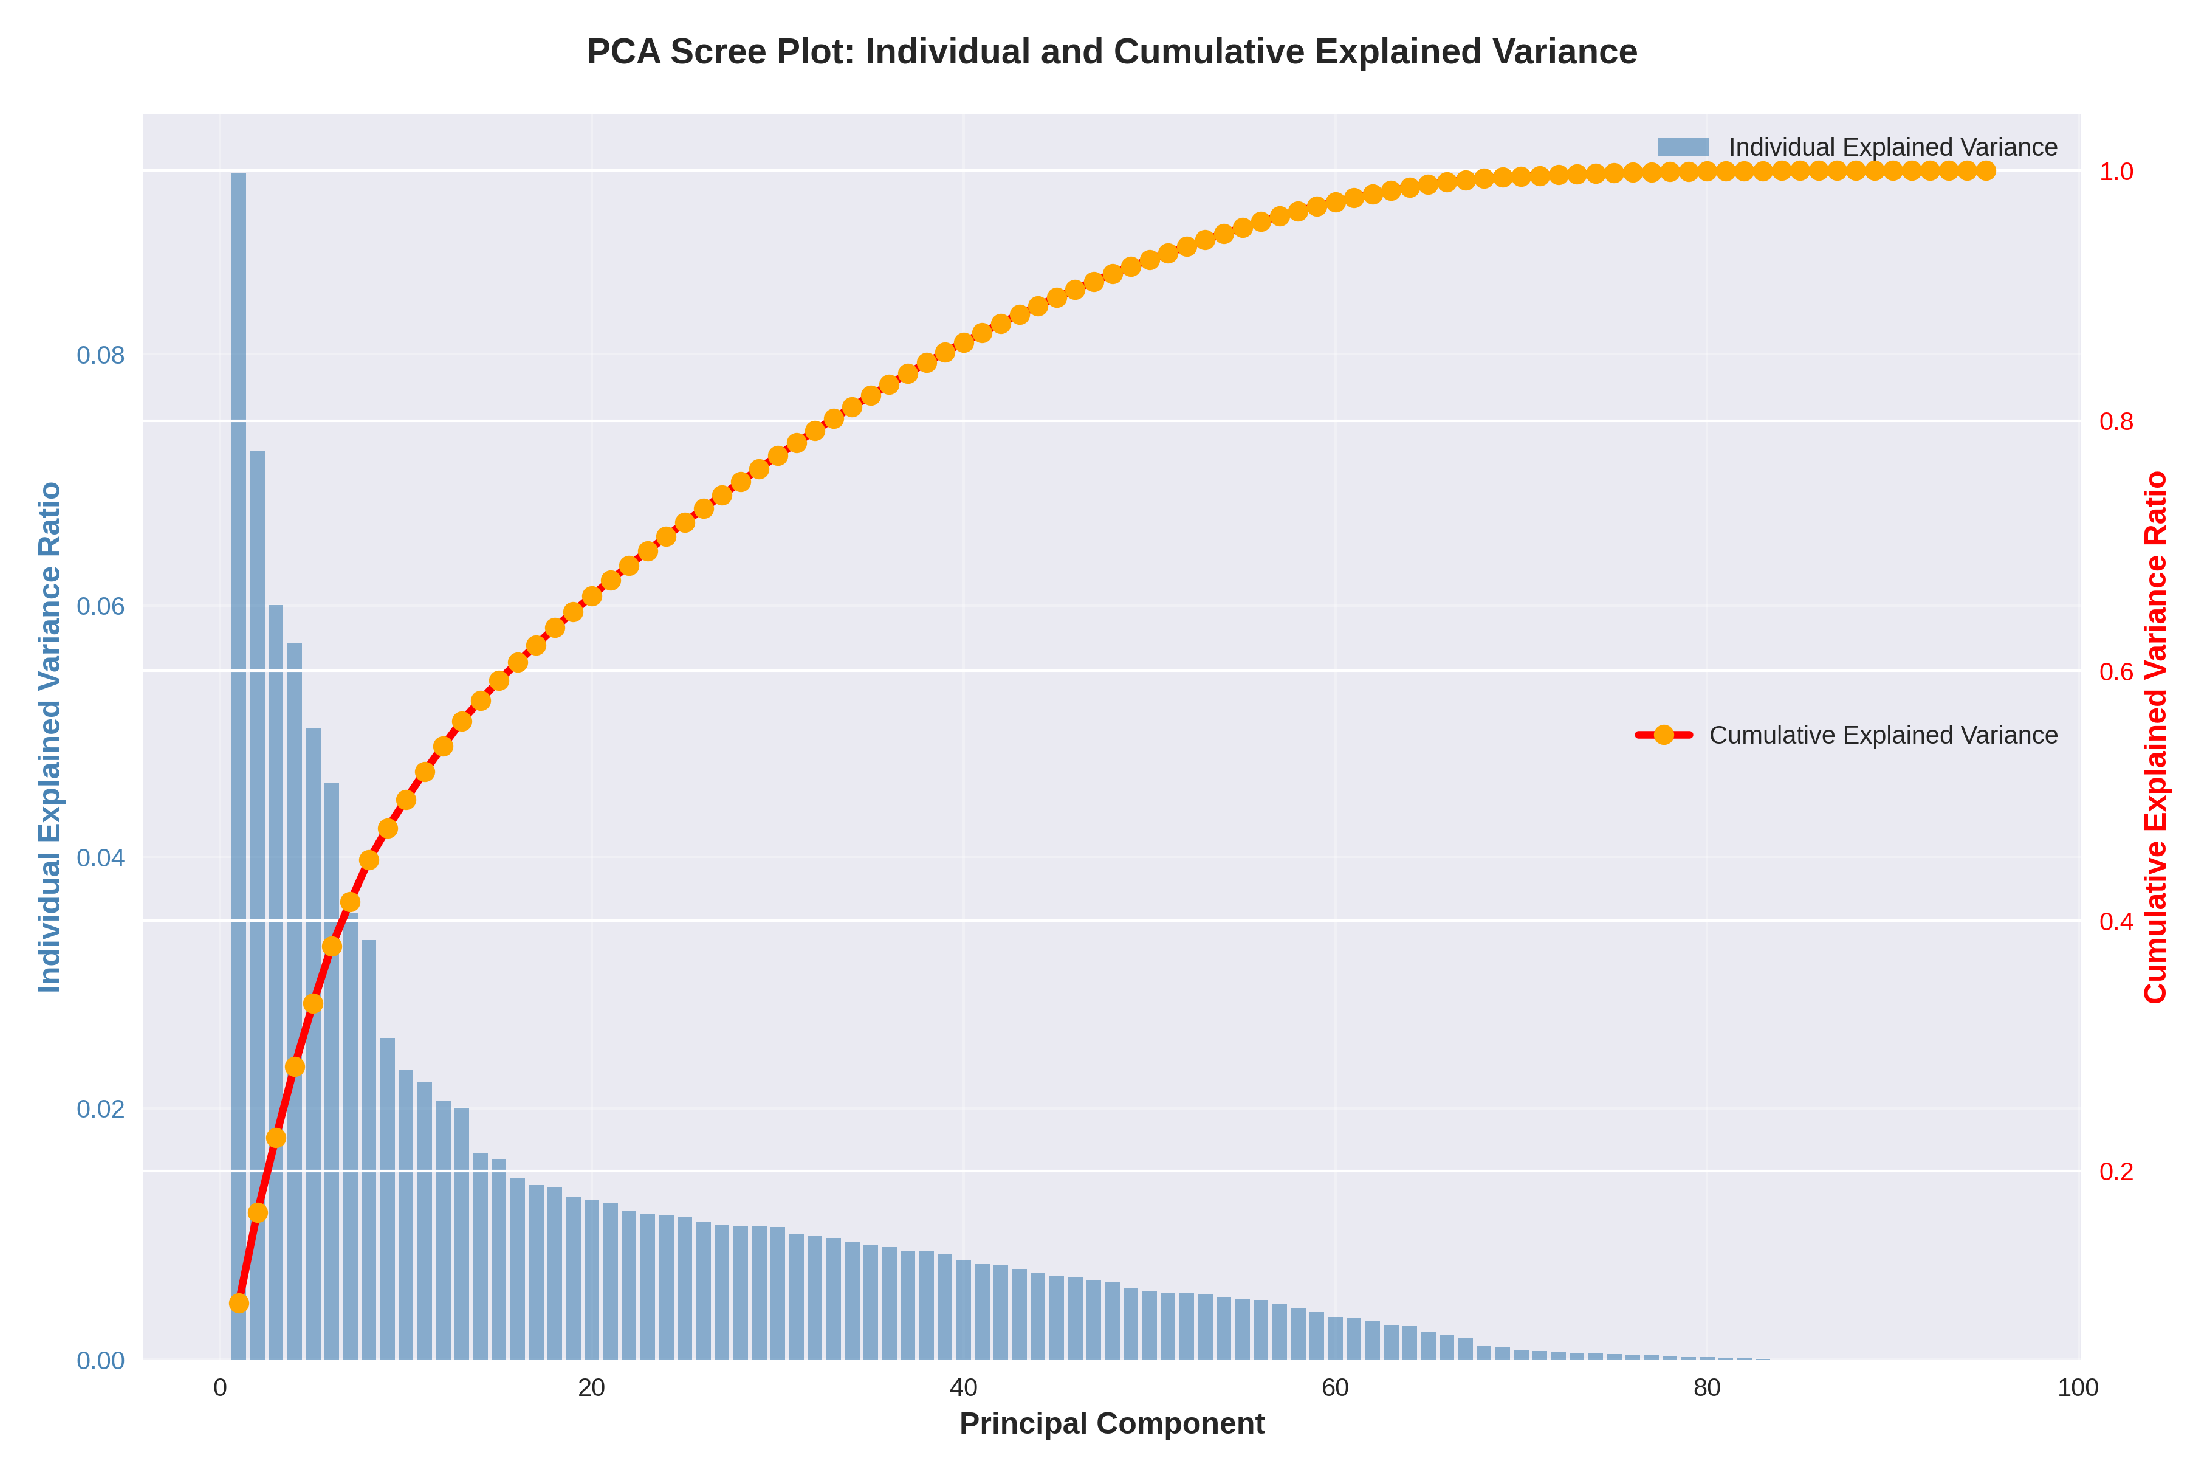

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/pca_scree_plot_22.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>In the above figure, The first component calculates a very high percentage of variance, as well as the second component. To explain >90% of the variance, we need at least 50 components.</i>

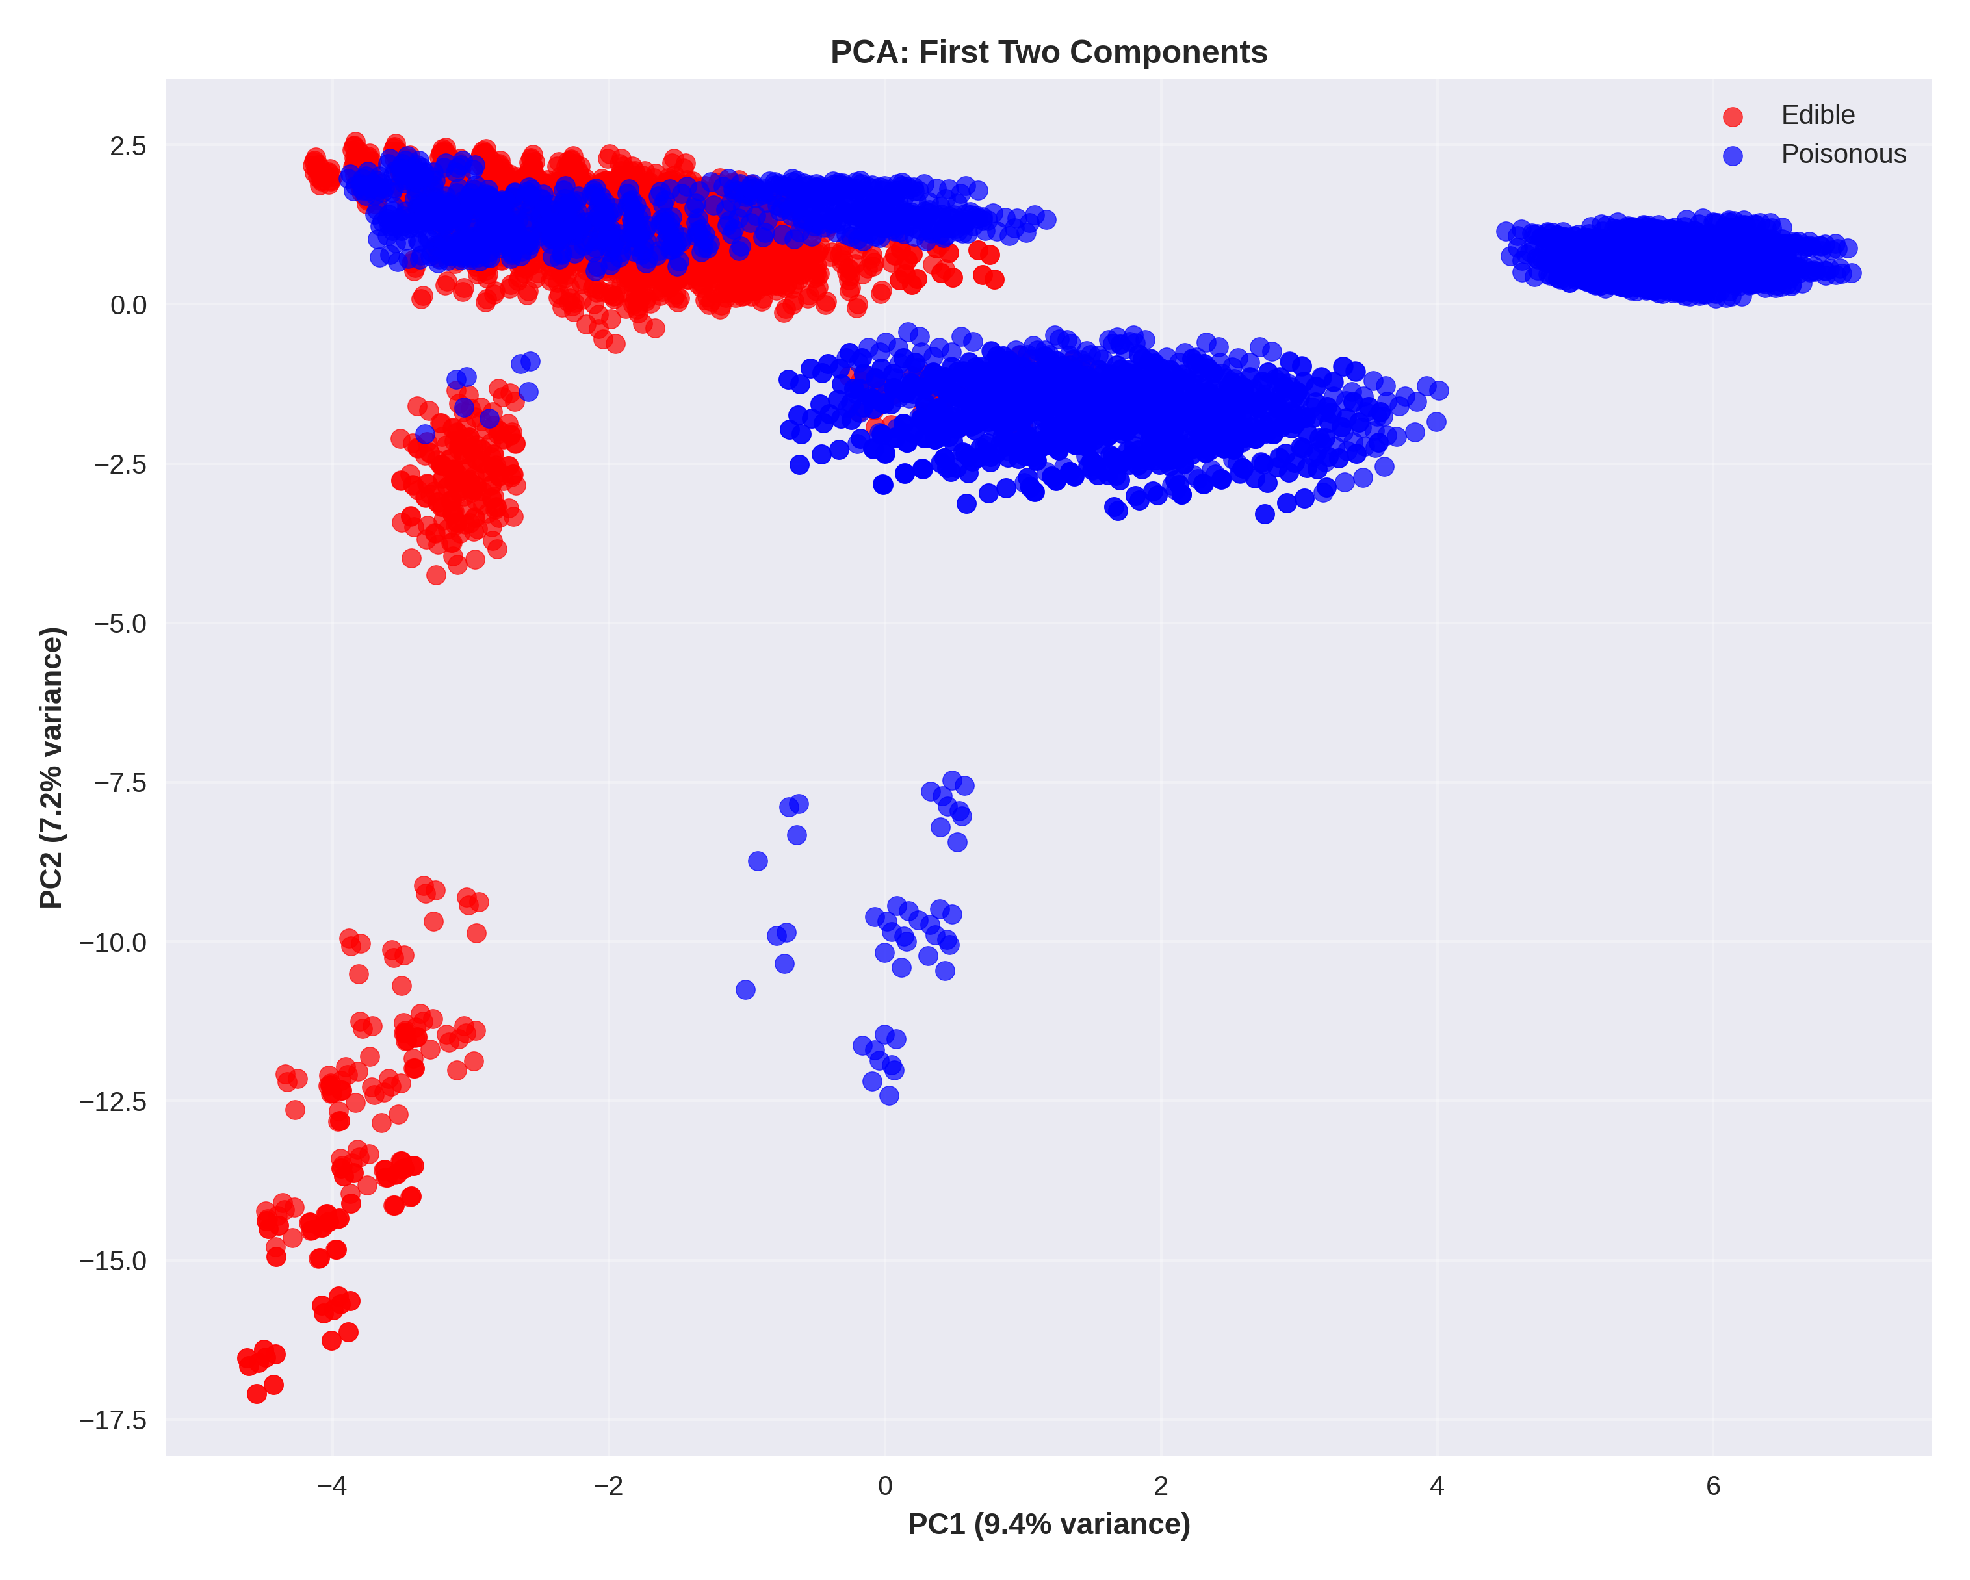

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/pca_scatter_plot_22.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>The classes can be partially seperated using $PC1$ and $PC2$, but for perfect seperation, we need higher-order components. $PC1>2$ is exclusively poisonous.</i>

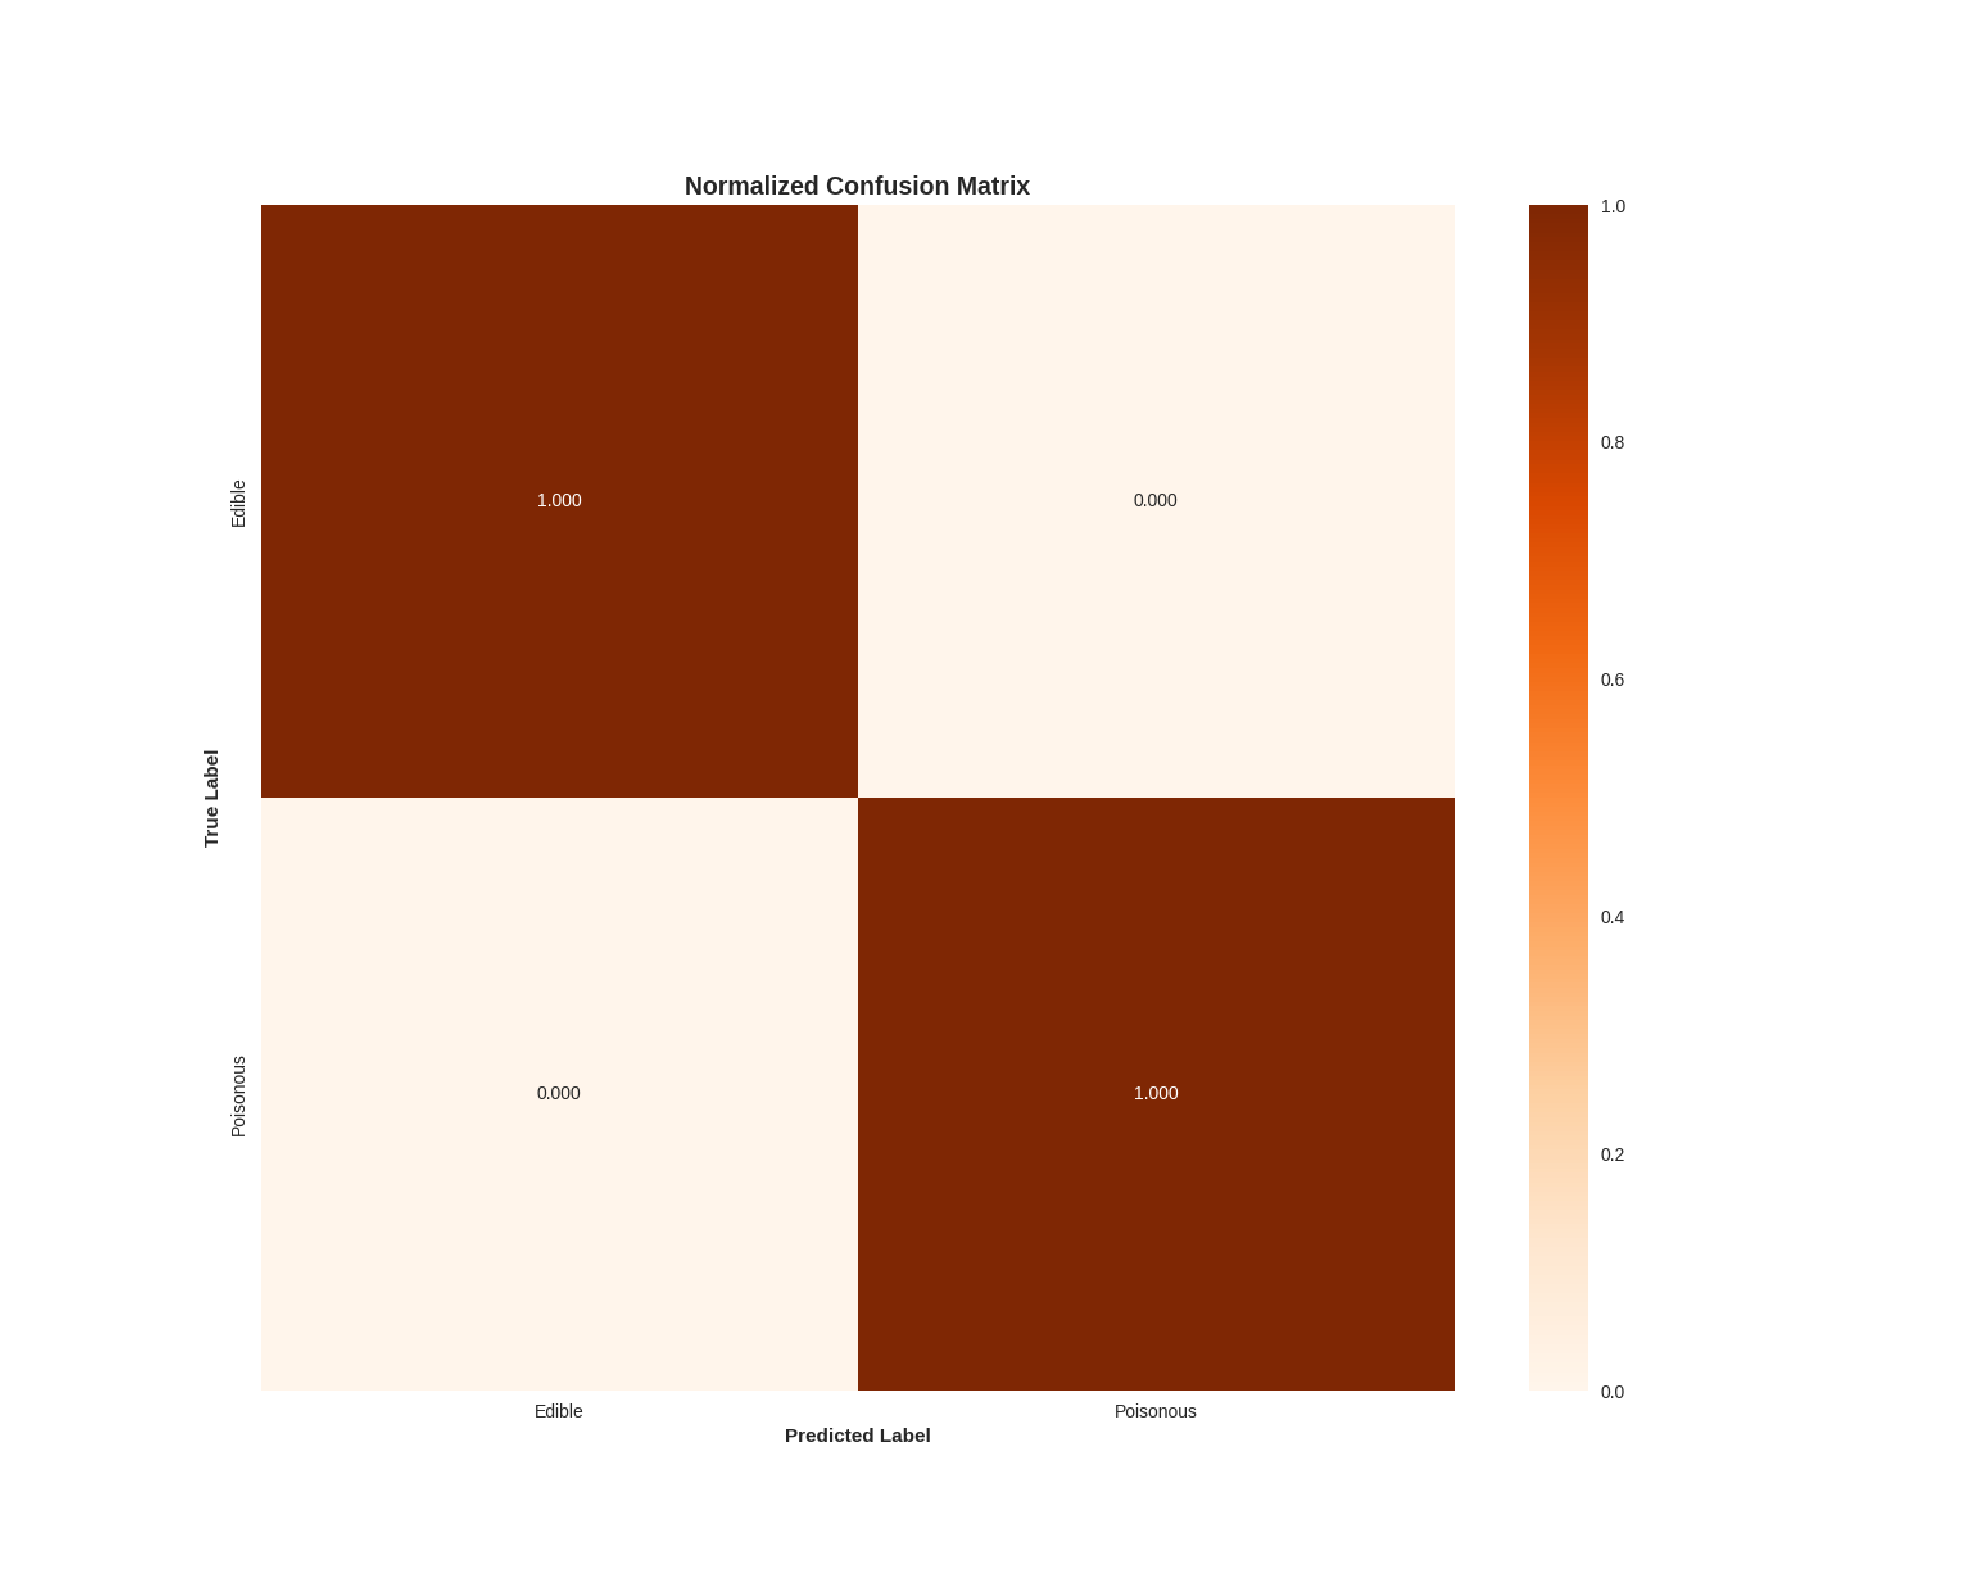

In [33]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/logreg_confusion_matrix_22.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()


<i>The classification of the classes is perfect with no false points.</i>

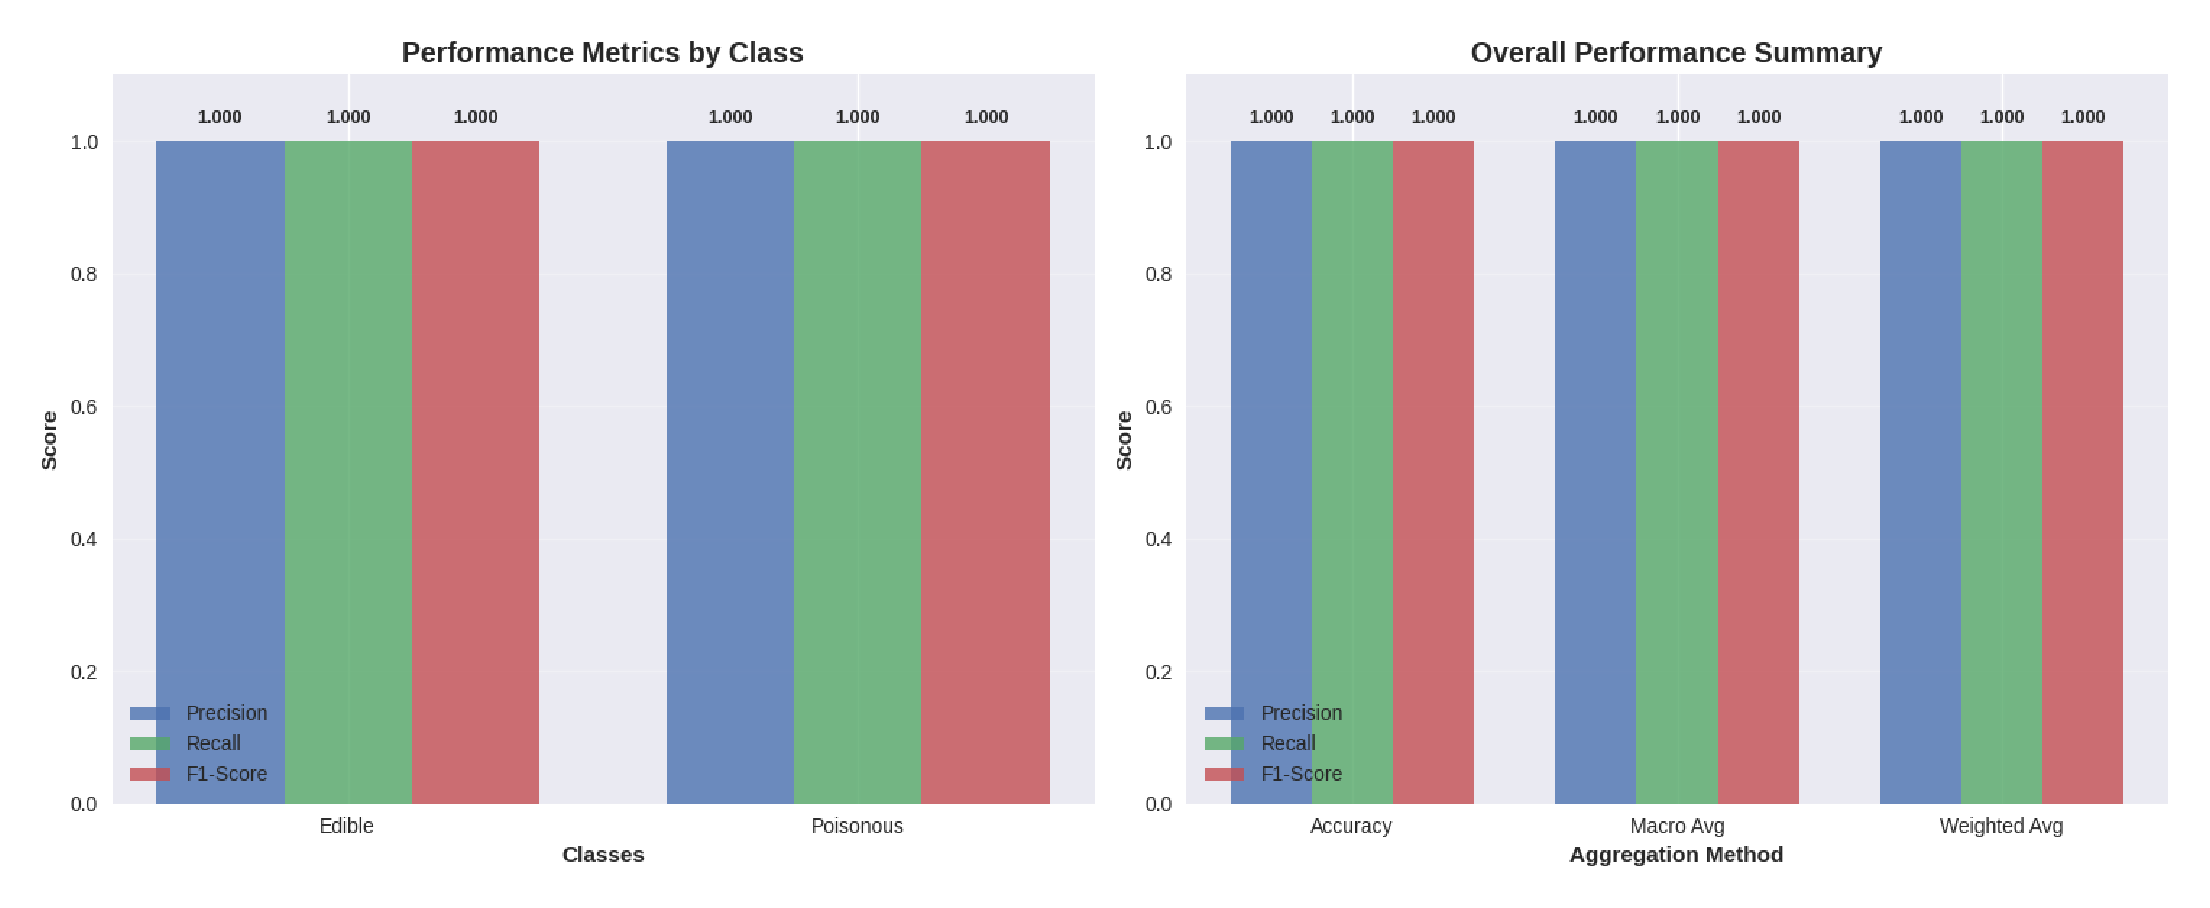

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/logreg_overall_22.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>Our model is achieving 100% accuracy</i>

## Dataset 2

In [ ]:
original_stdout = sys.stdout

# Redirect stdout
with open('mushrooms_results1.txt', 'w') as f:
    sys.stdout = f
    norm_results, pca_results = pipeline('data/mushrooms_feature_sel1', 16)
    
# Restore original stdout
sys.stdout = original_stdout
total_results['2'] = {"norm": norm_results, "pca": pca_results}

After PCA:
1. Original Dimension:  17
2. New Dimensions:  86
3. Percentage Increase in Dimension size:  405.88235294117646

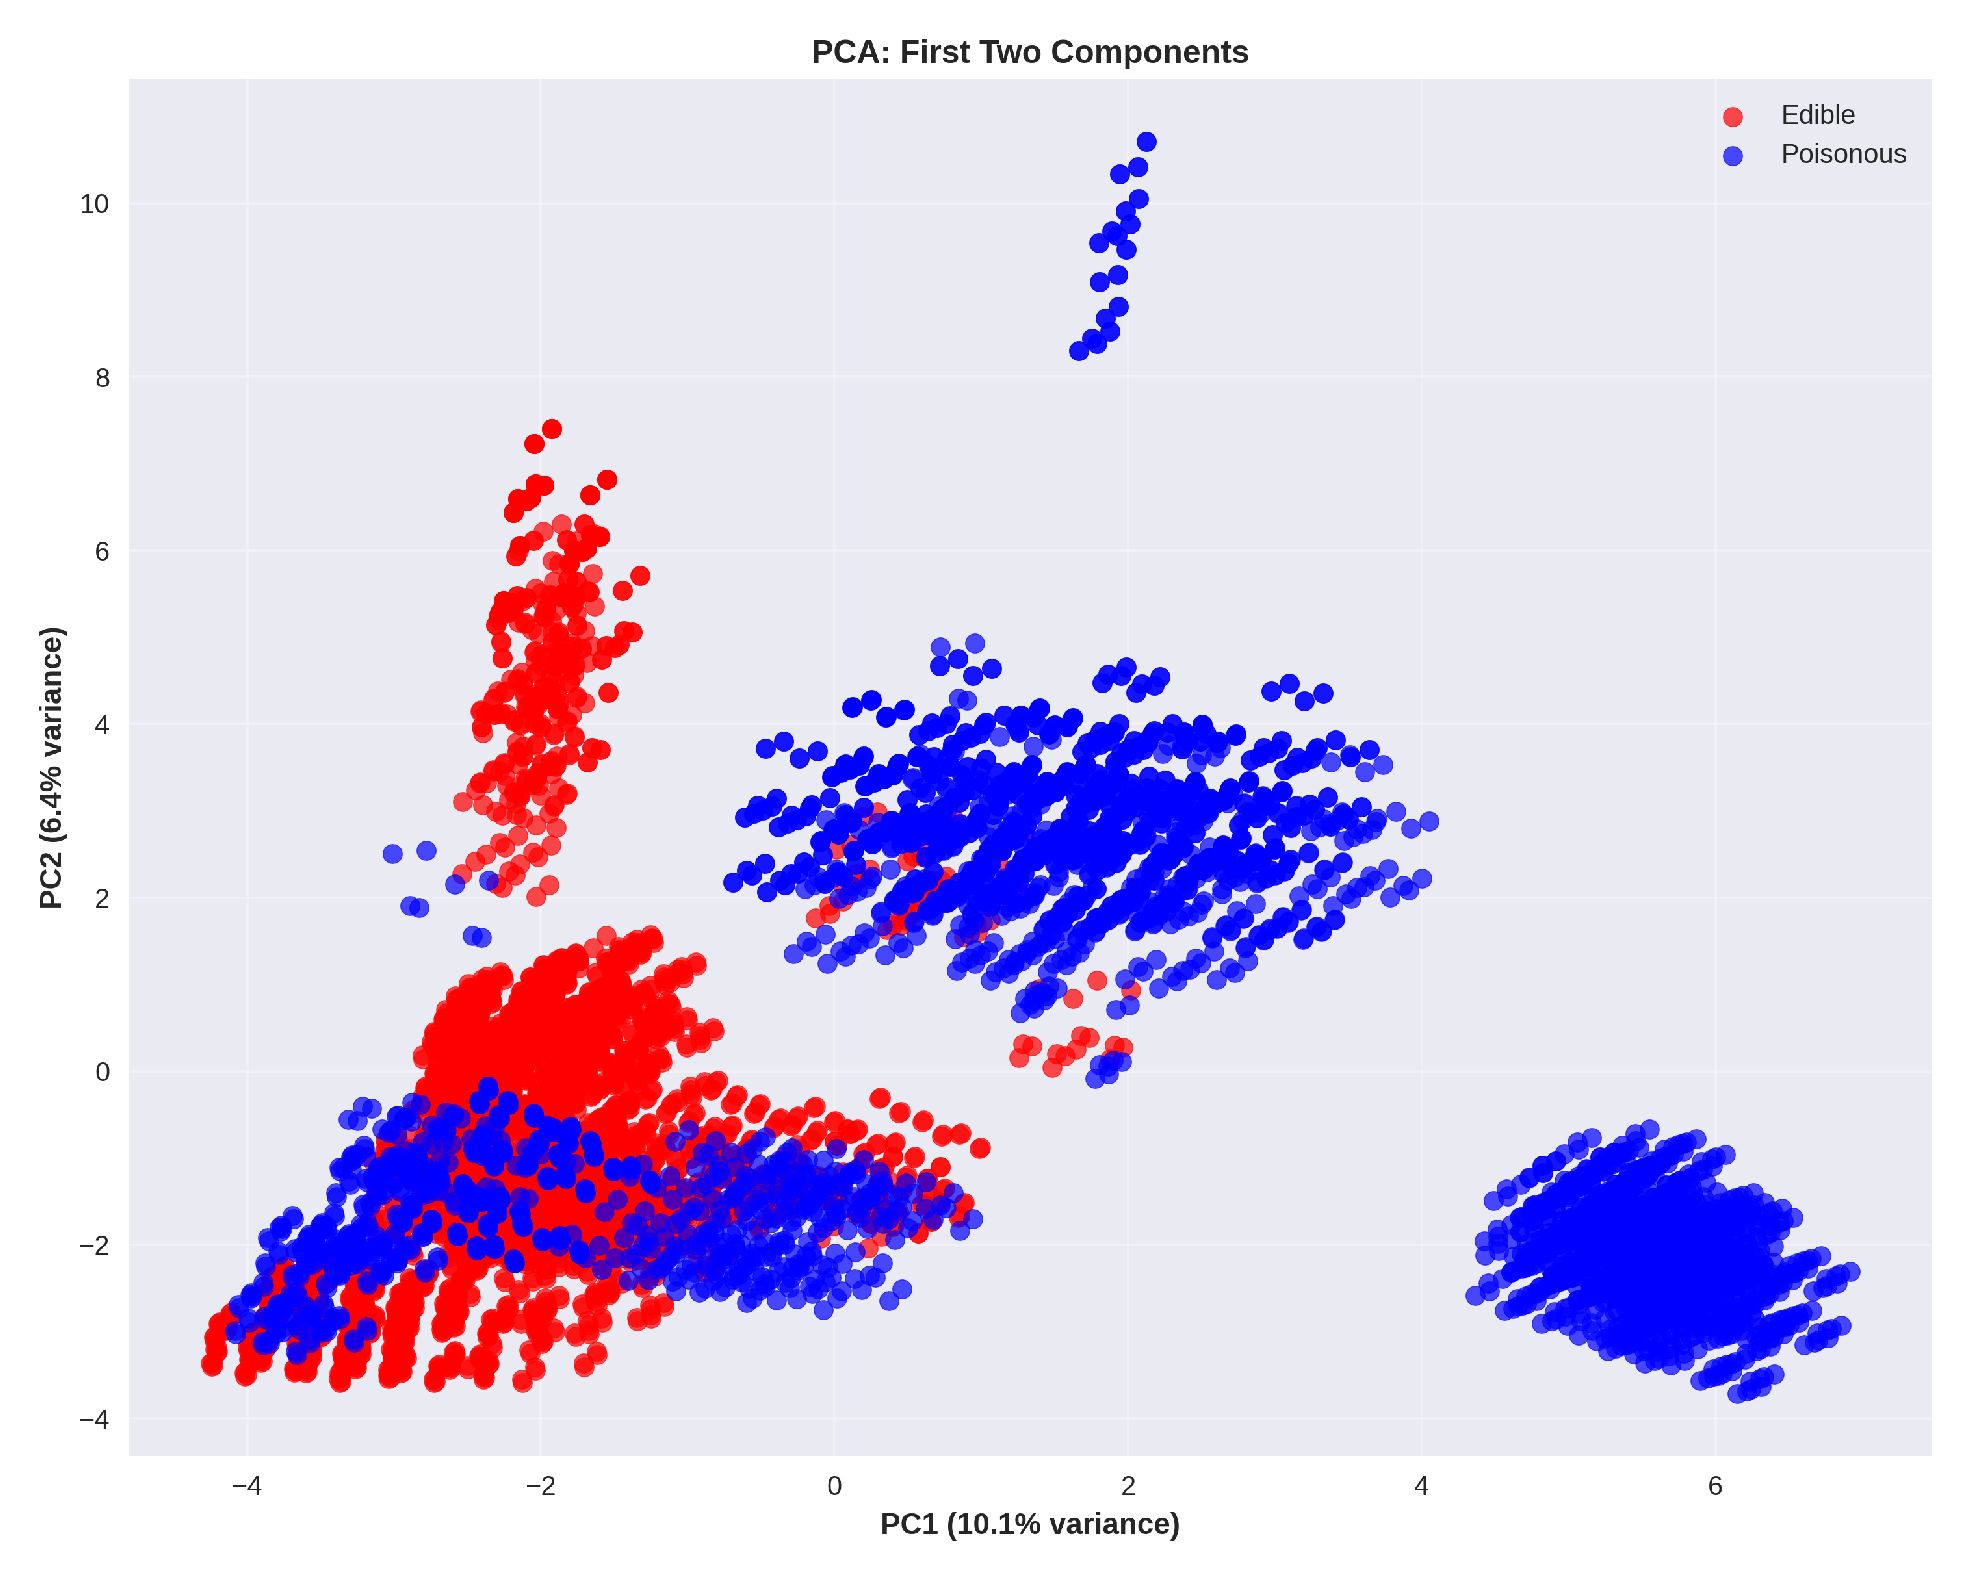

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/pca_scatter_plot_16.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>There is a considerable overlap with both the classes in this case. $PC1 > 2$ is exclusively Poisonous.</i>

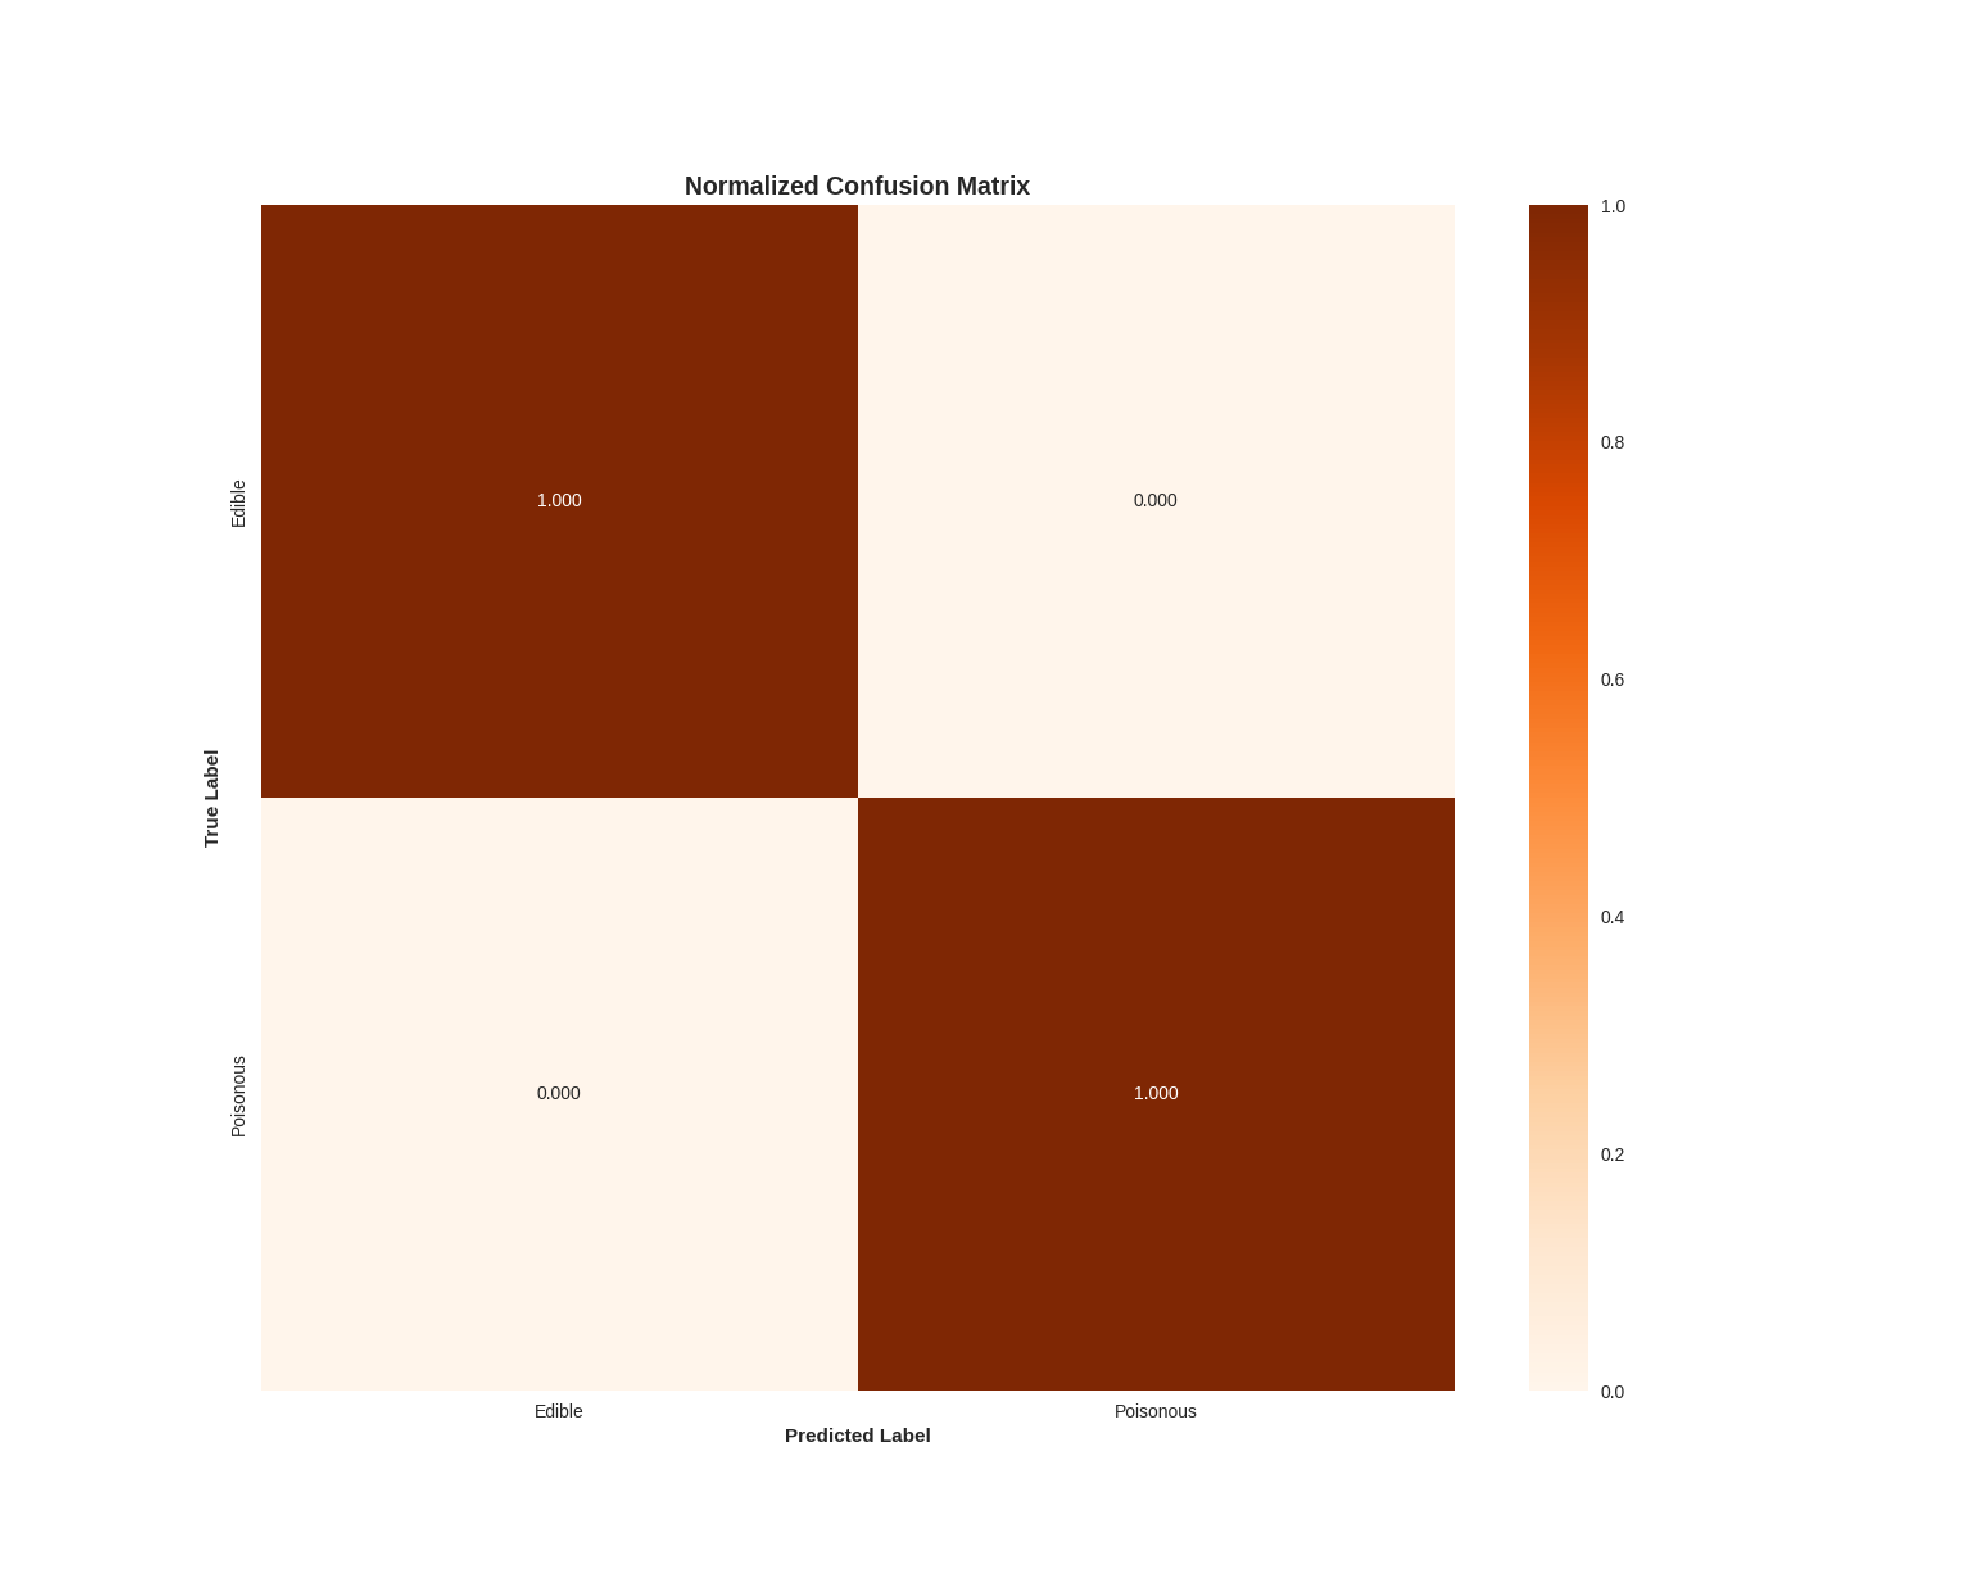

In [35]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/logreg_confusion_matrix_16.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>Perfect classification</i>

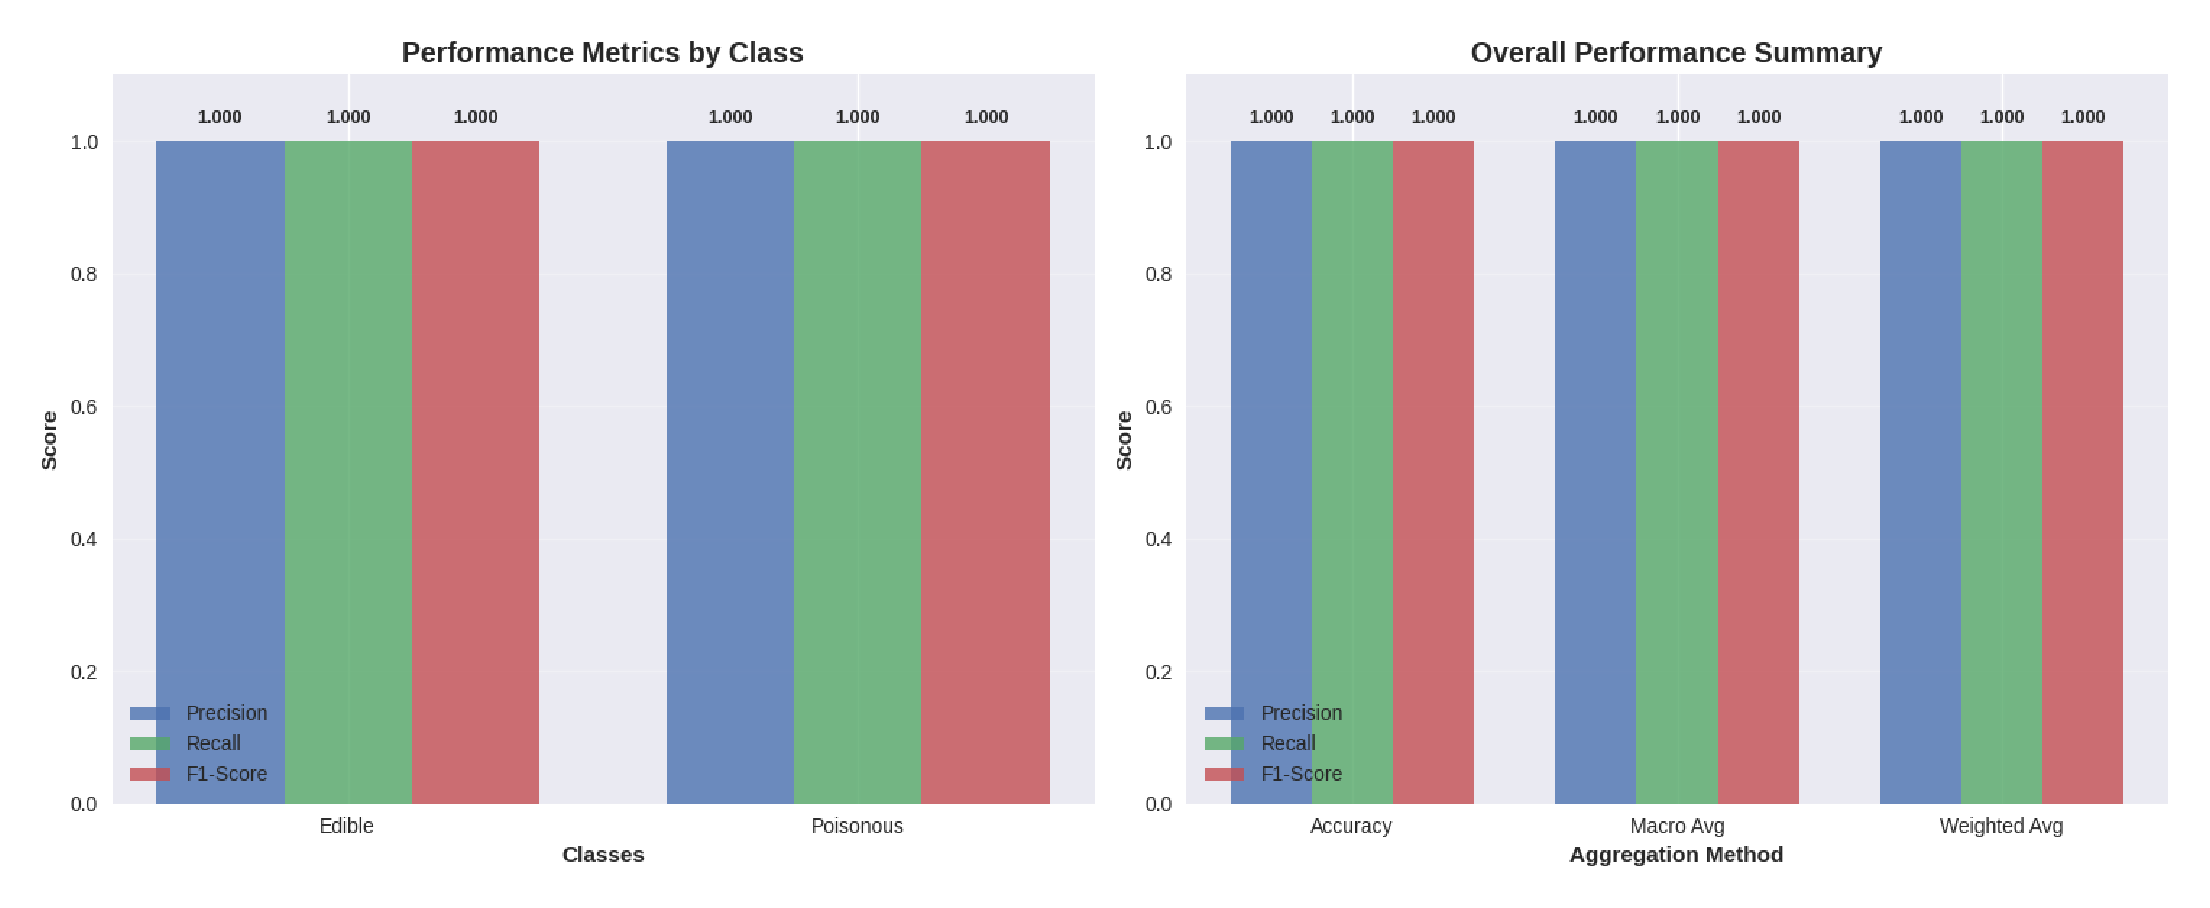

In [11]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/logreg_overall_16.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

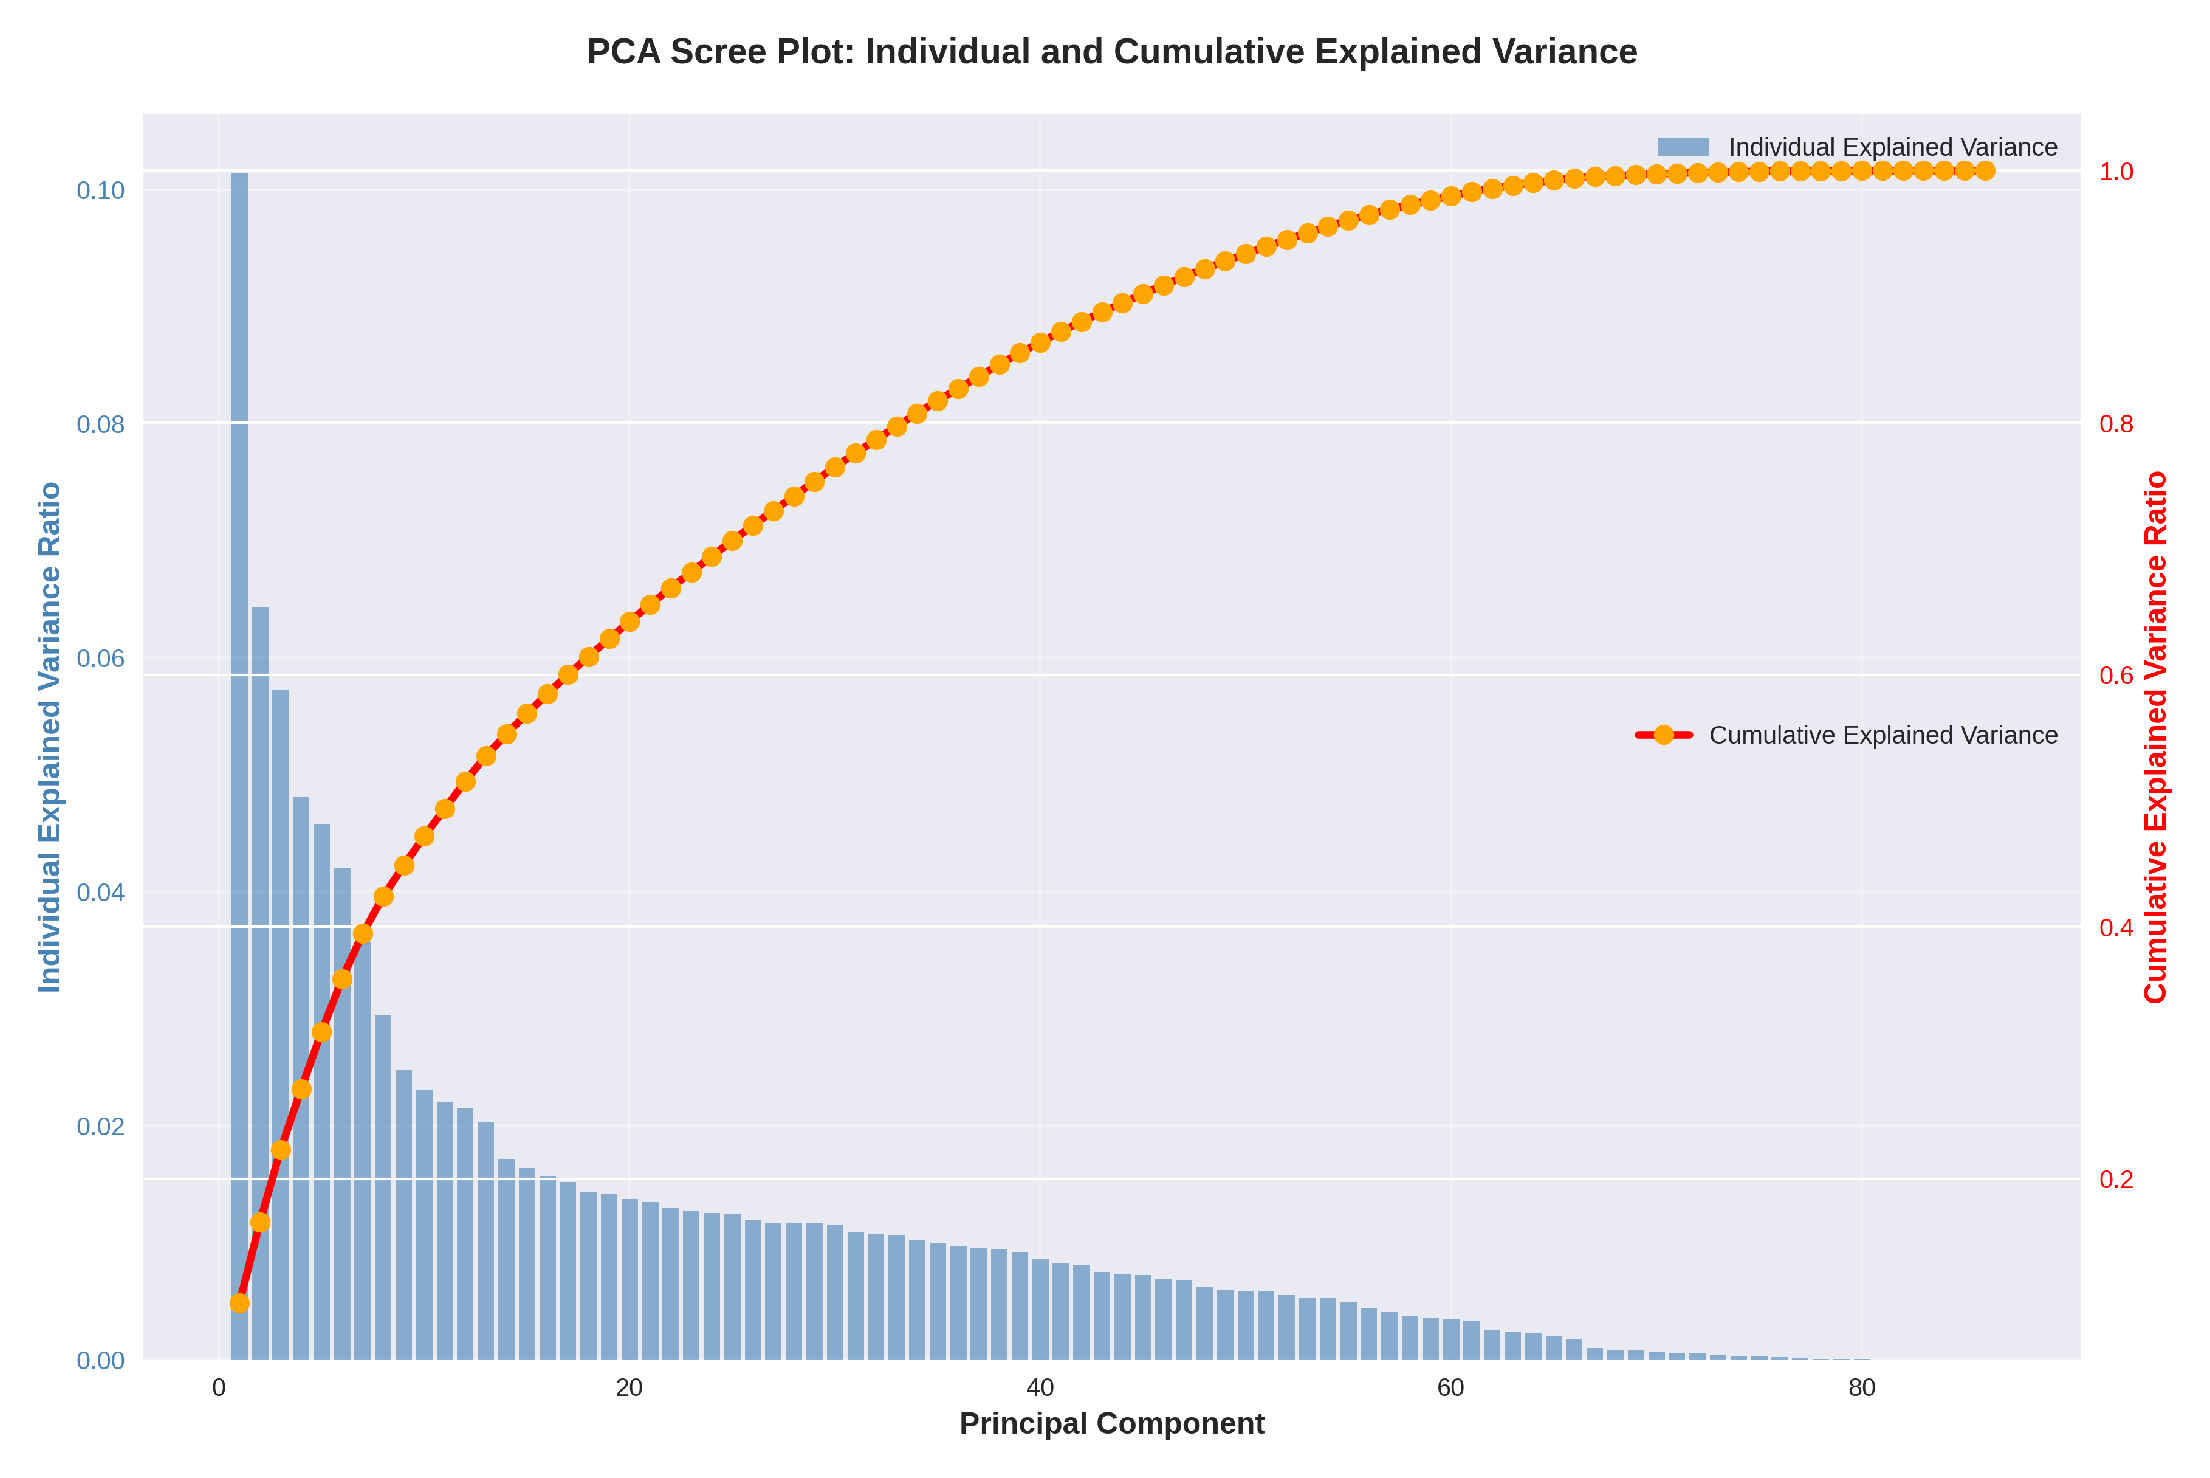

In [12]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/pca_scree_plot_16.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i> In the above figure, The first component calculates a very high percentage of variance, as well as the second component. To explain >90% of the variance, we need at least 50 components.</i>

## Dataset 3

In [ ]:
original_stdout = sys.stdout

# Redirect stdout
with open('mushrooms_results2.txt', 'w') as f:
    sys.stdout = f
    norm_results, pca_results = pipeline('data/mushrooms_feature_sel2', 13)
    
# Restore original stdout
sys.stdout = original_stdout
total_results['3'] = {"norm": norm_results, "pca": pca_results}

After PCA:
1. Original Dimension:  14
2. New Dimensions:  74
3. Percentage Increase in Dimension size:  428.57142857142856

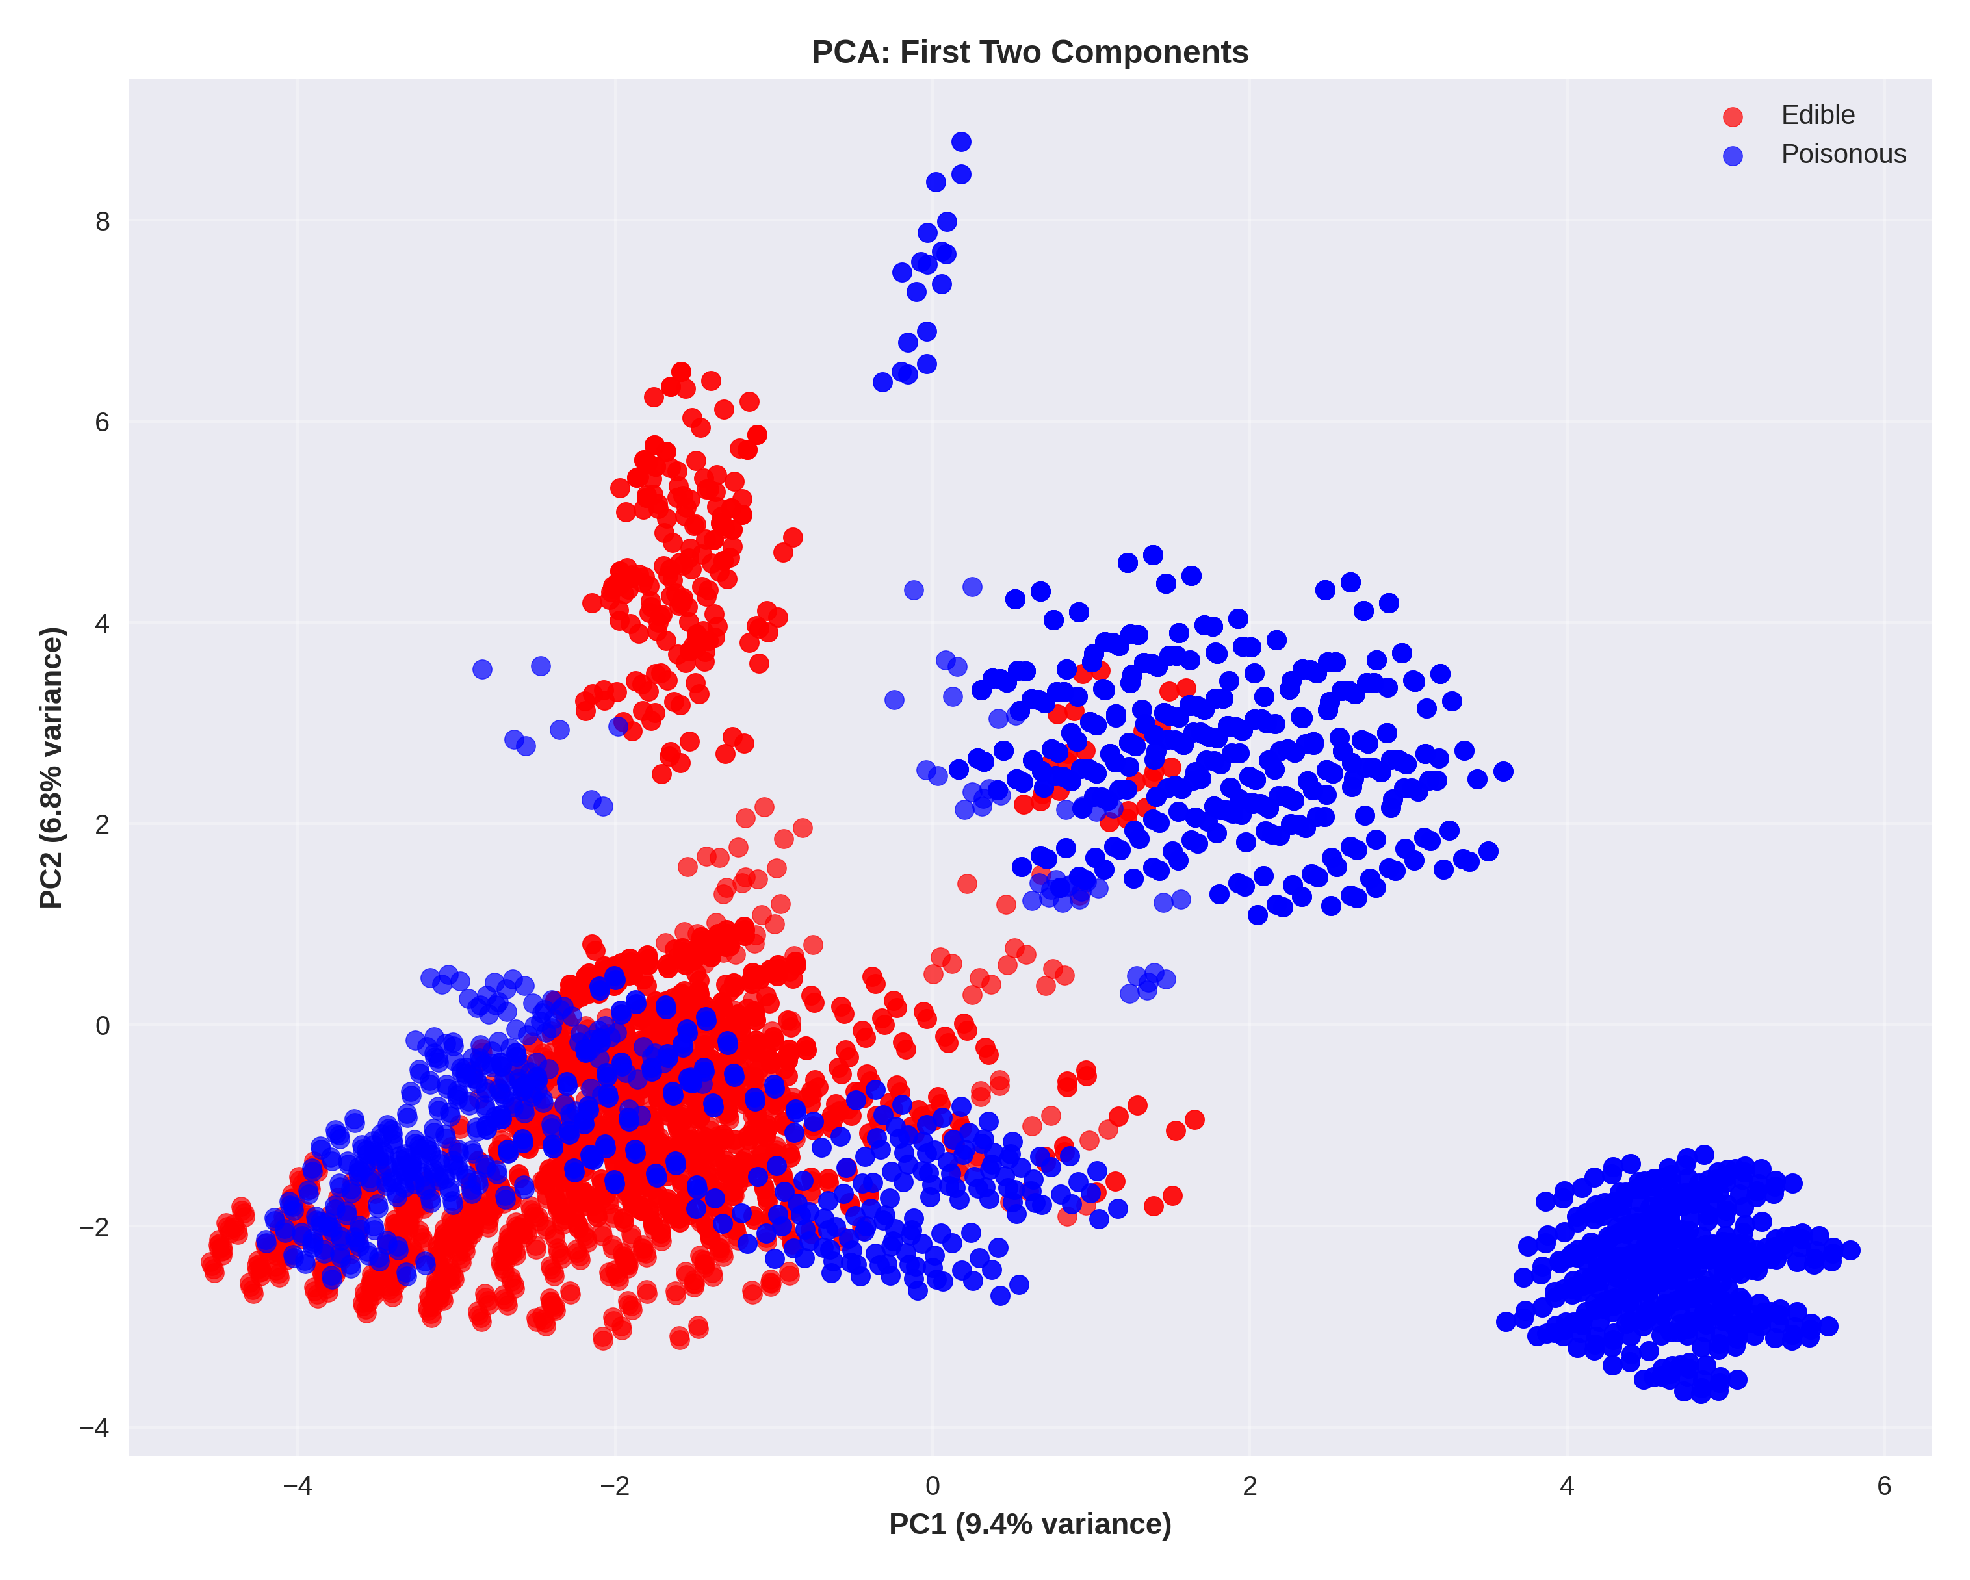

In [13]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/pca_scatter_plot_13.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>Considerable overlap between the two classes, Poisonous is exclusively seperable after $PC1 > 2$</i>

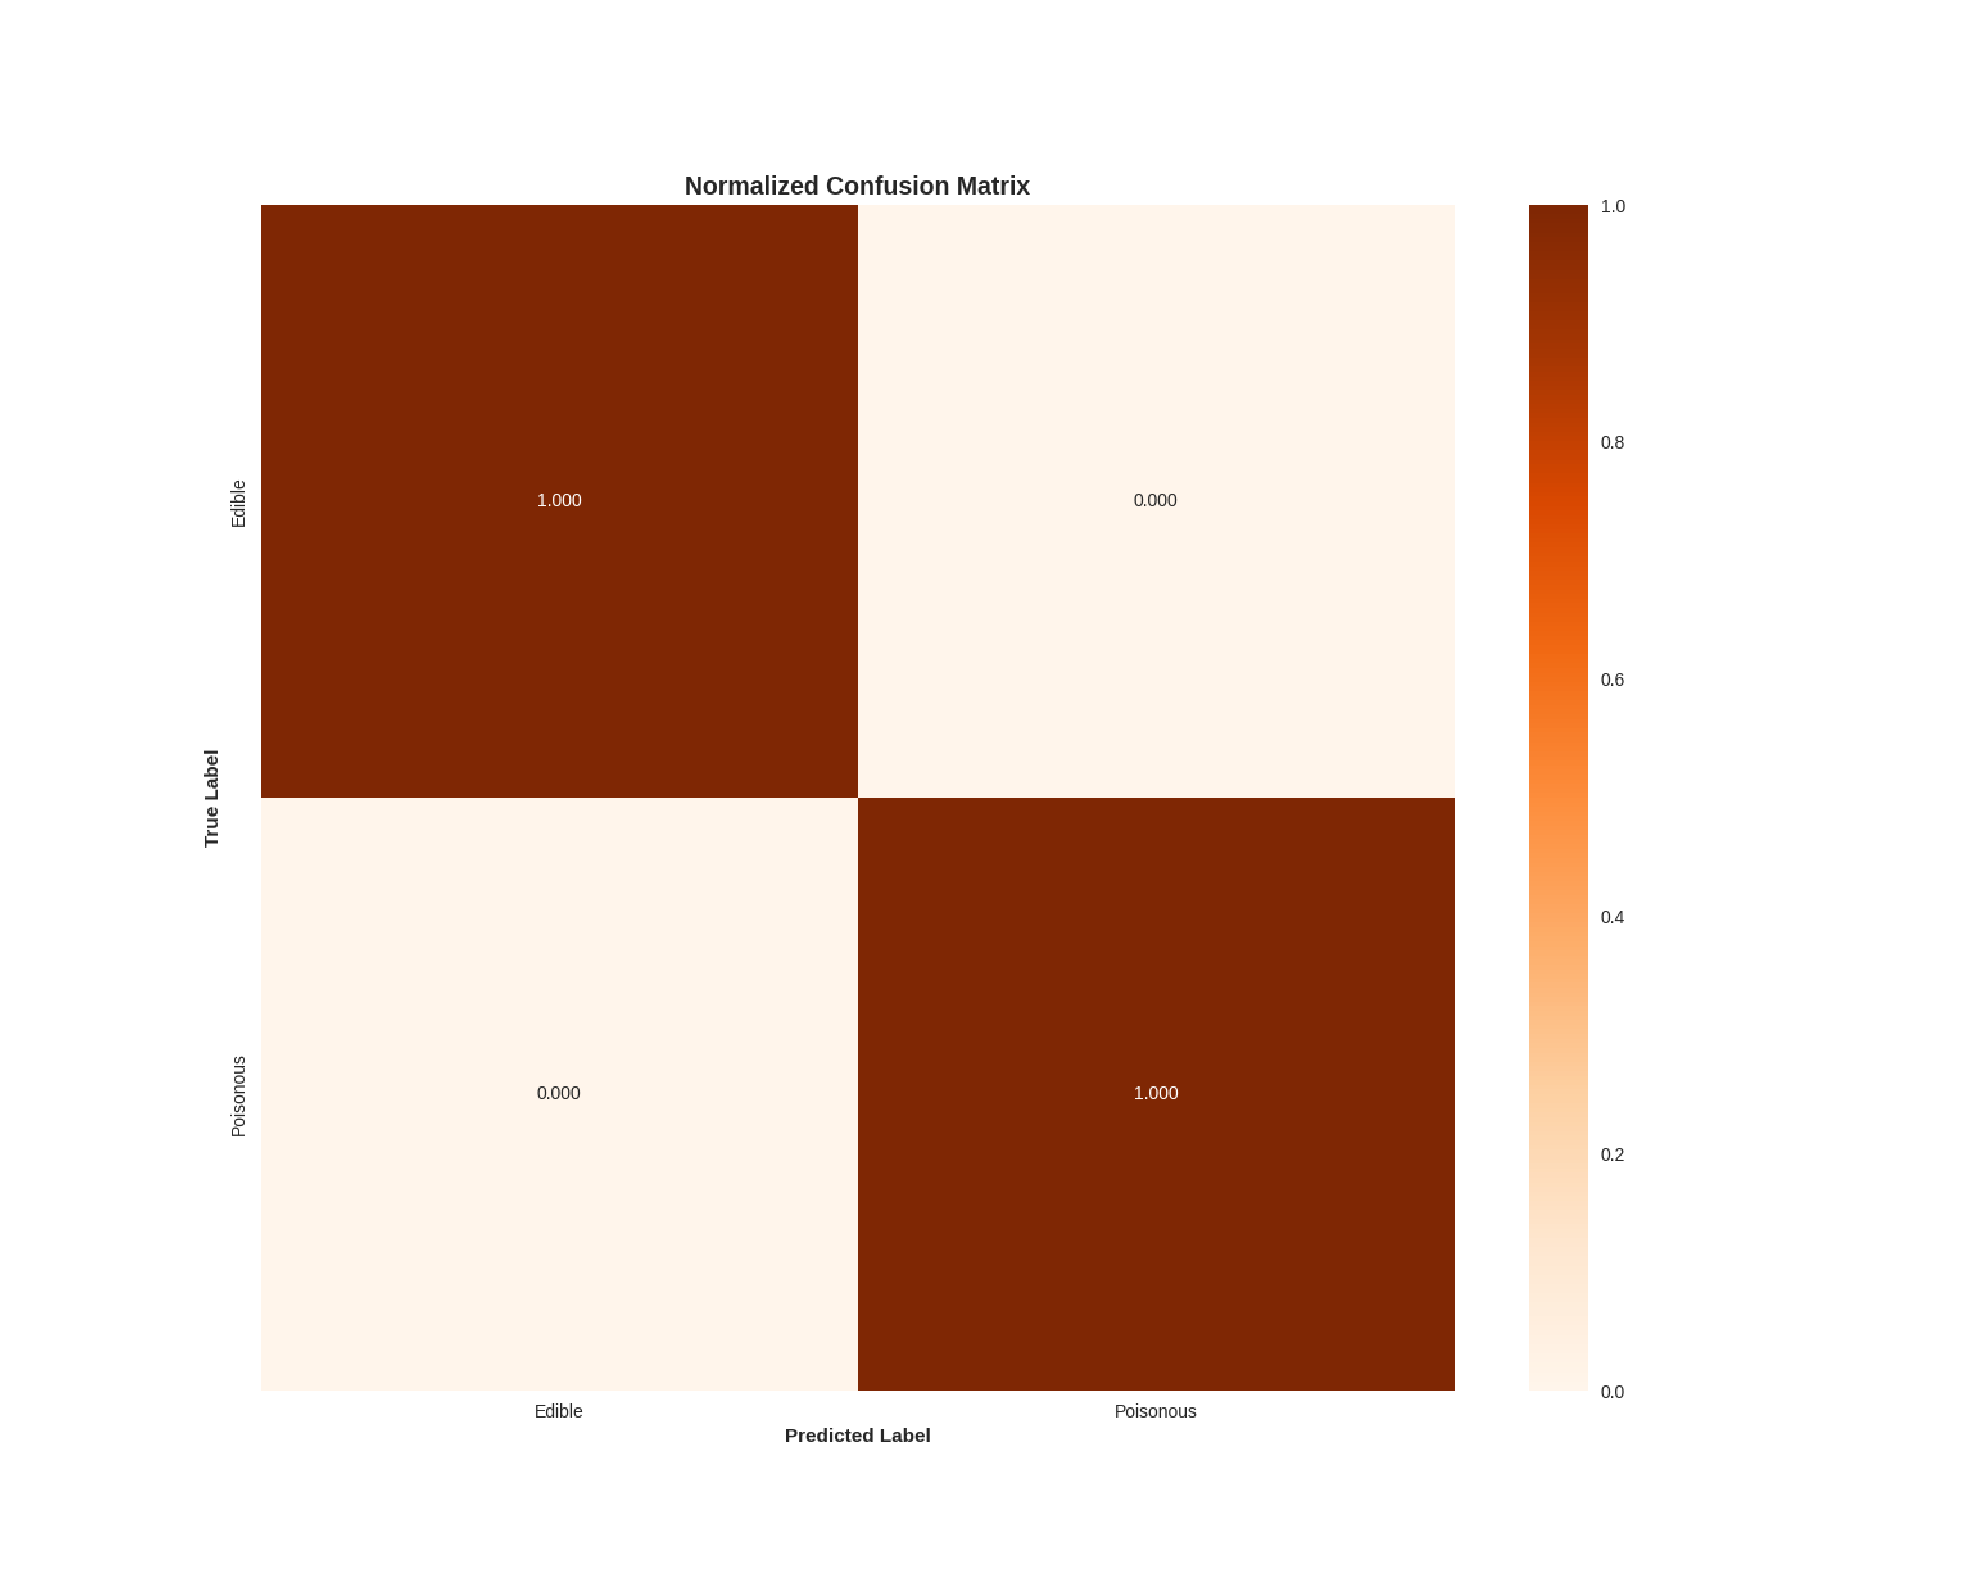

In [37]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/logreg_confusion_matrix_13.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

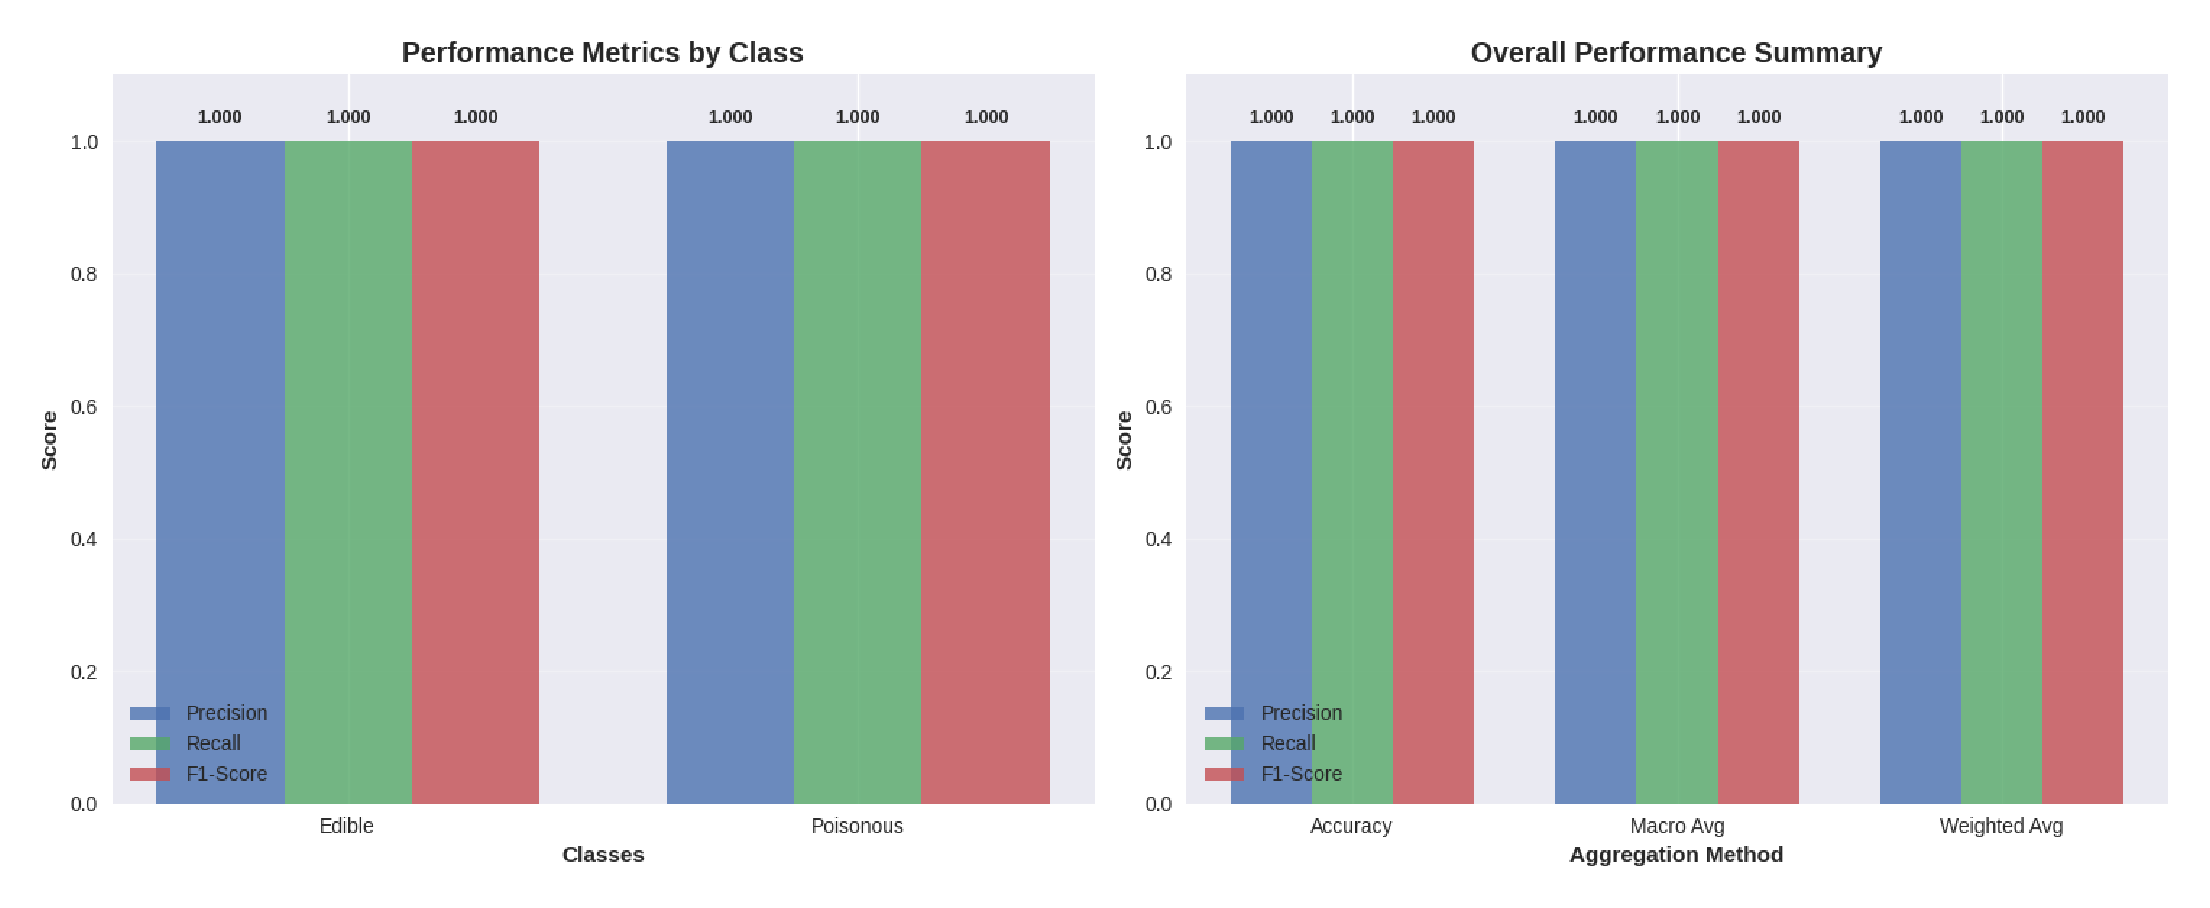

In [19]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/logreg_overall_13.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>Perfect classification</i>

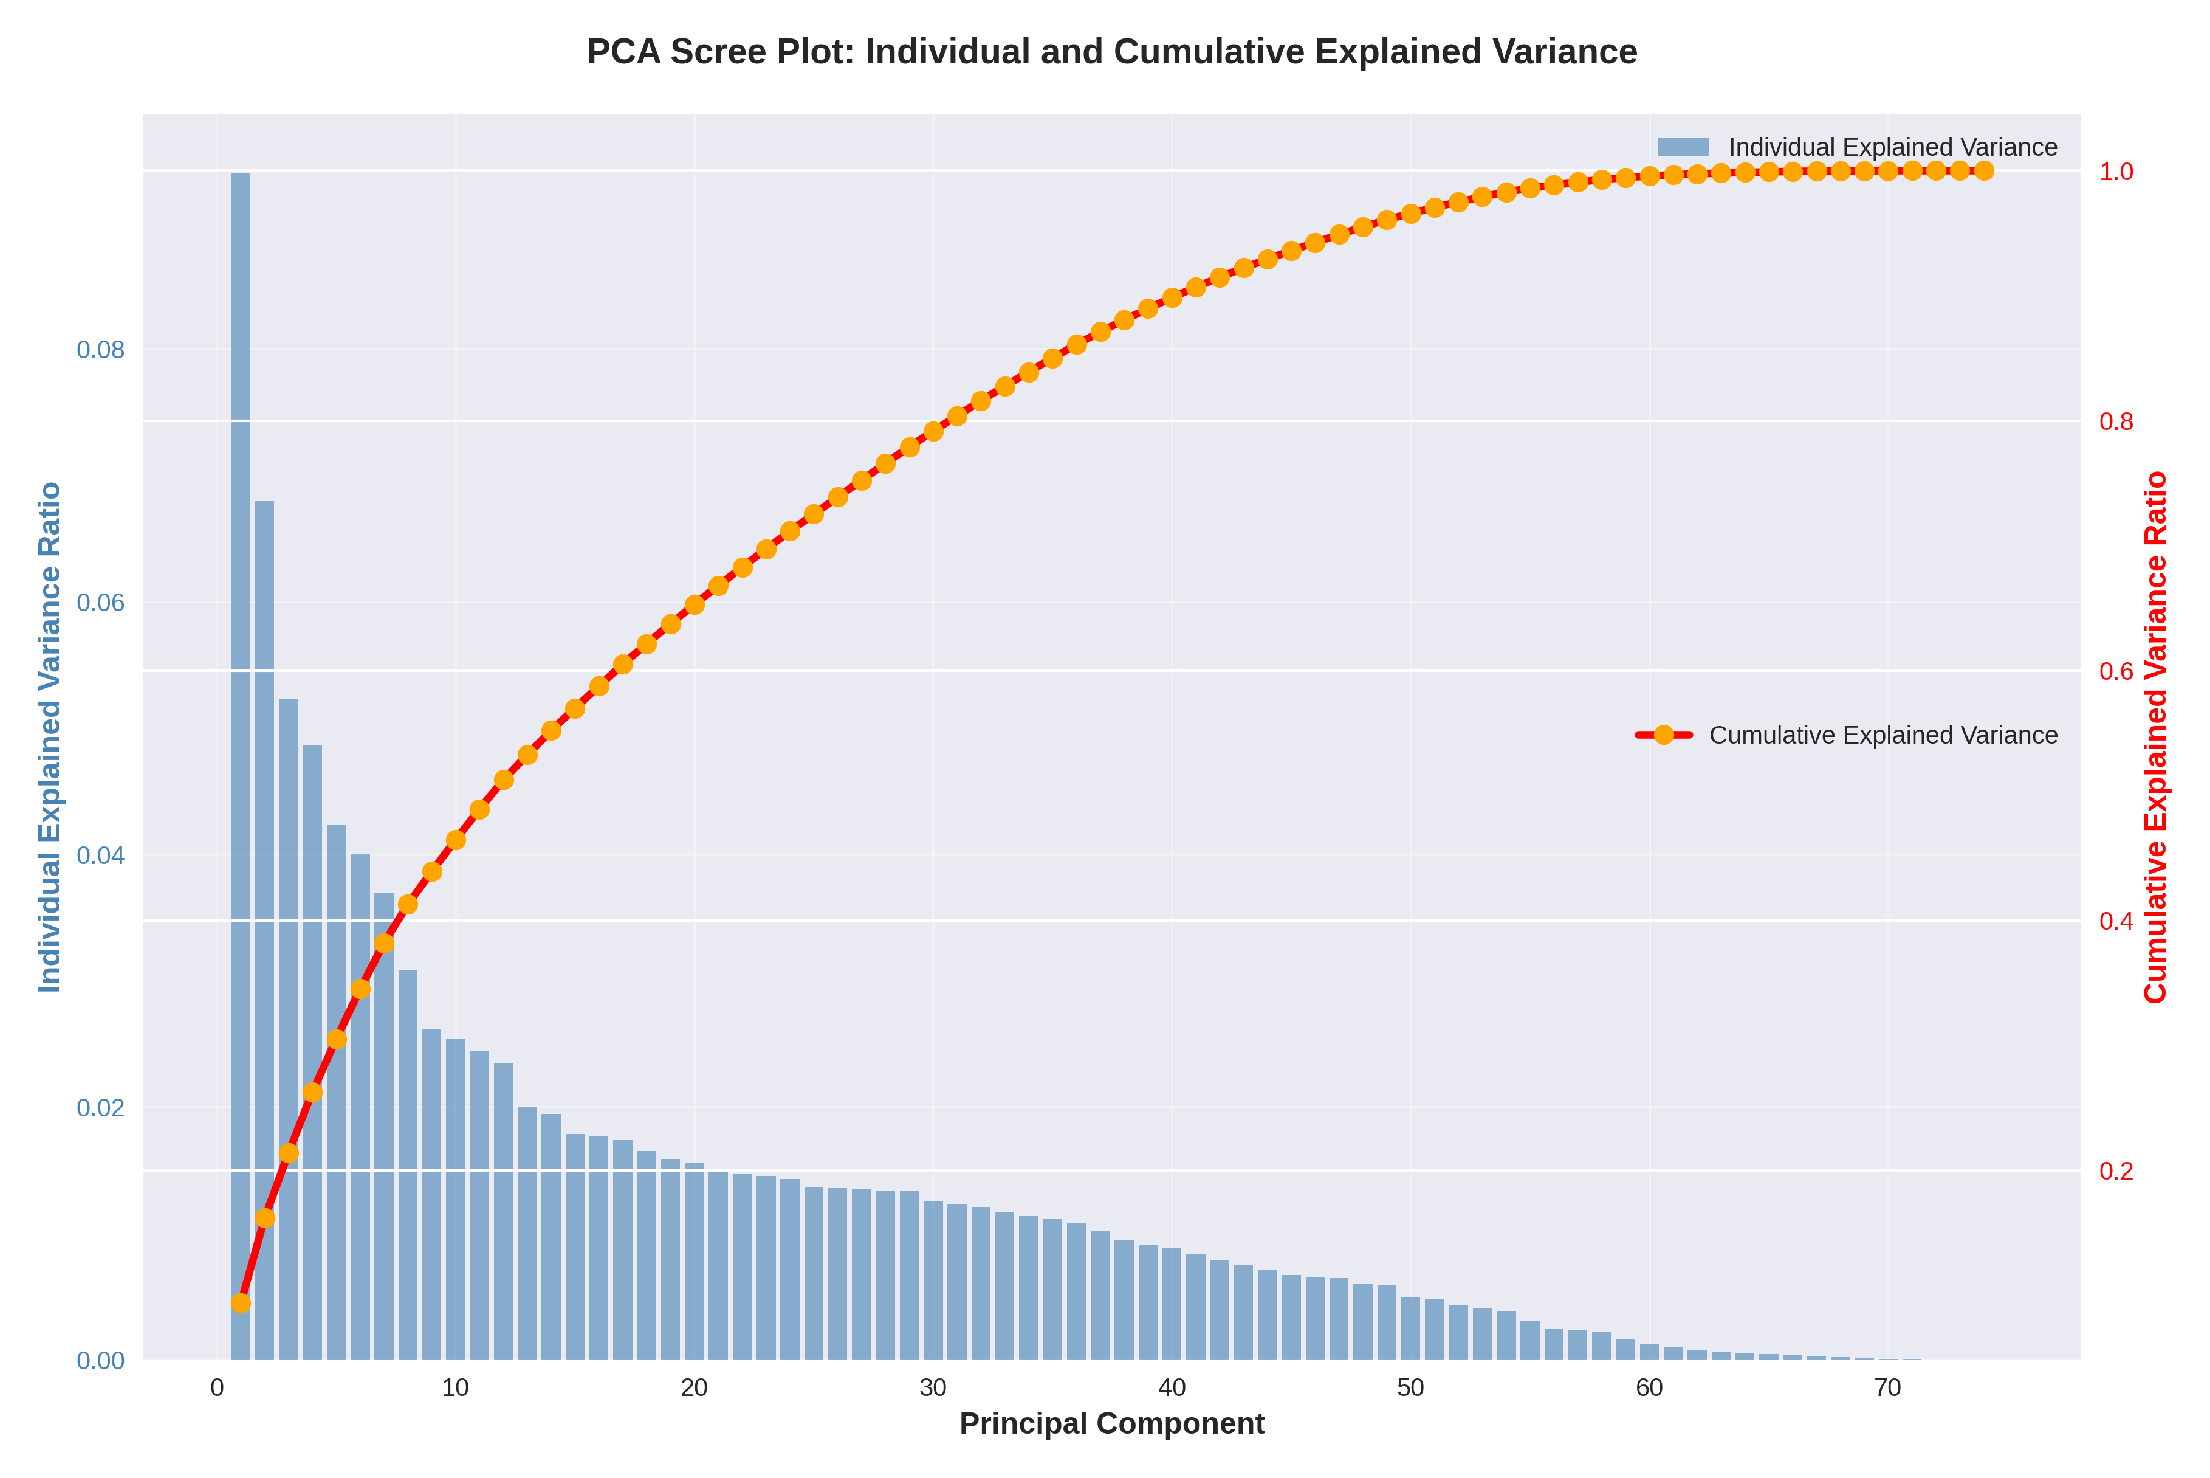

In [15]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/pca_scree_plot_13.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>In the above figure, The first component calculates a very high percentage of variance, as well as the second component. To explain >90% of the variance, we need at least 40 components.</i>

## Dataset 4

In [ ]:
original_stdout = sys.stdout

# Redirect stdout
with open('mushrooms_results_cleaned.txt', 'w') as f:
    sys.stdout = f
    norm_results, pca_results = pipeline('data/mushrooms_cleaned', 10)
    
# Restore original stdout
sys.stdout = original_stdout
total_results['4'] = {"norm": norm_results, "pca": pca_results}

After PCA:
1. Original Dimension:  11
2. New Dimensions:  57
3. Percentage Increase in Dimension size:  418.1818181818182

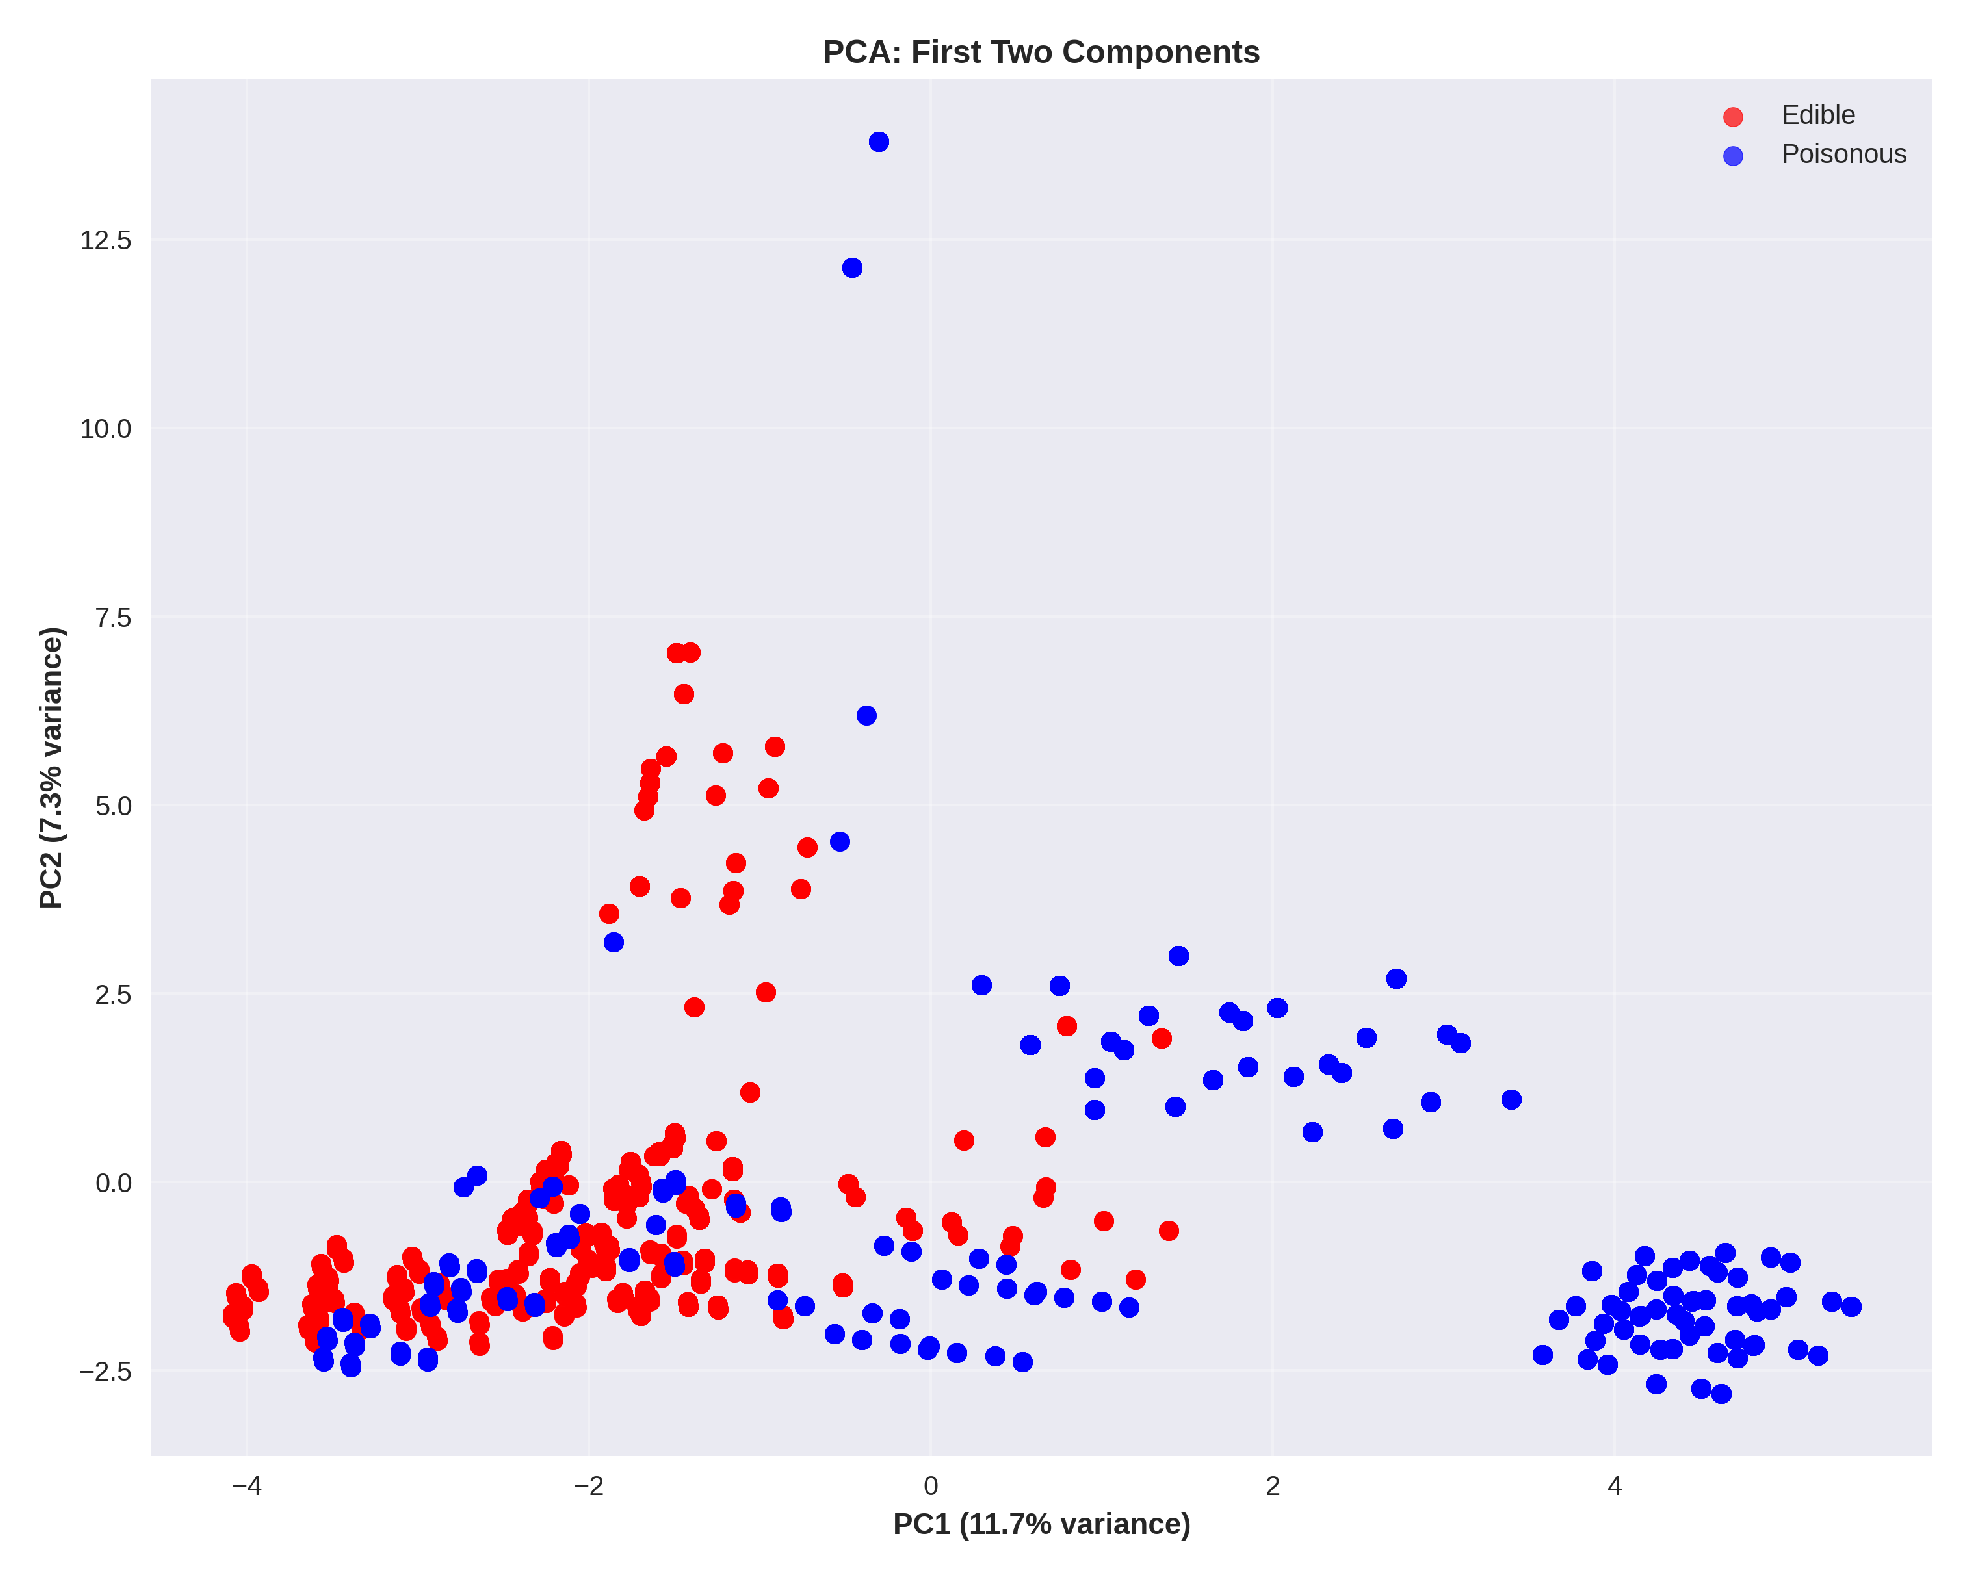

In [16]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/pca_scatter_plot_10.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>Lower density than before, Poisonous class has more variance than Edible. Considerable overlap between the two</i>

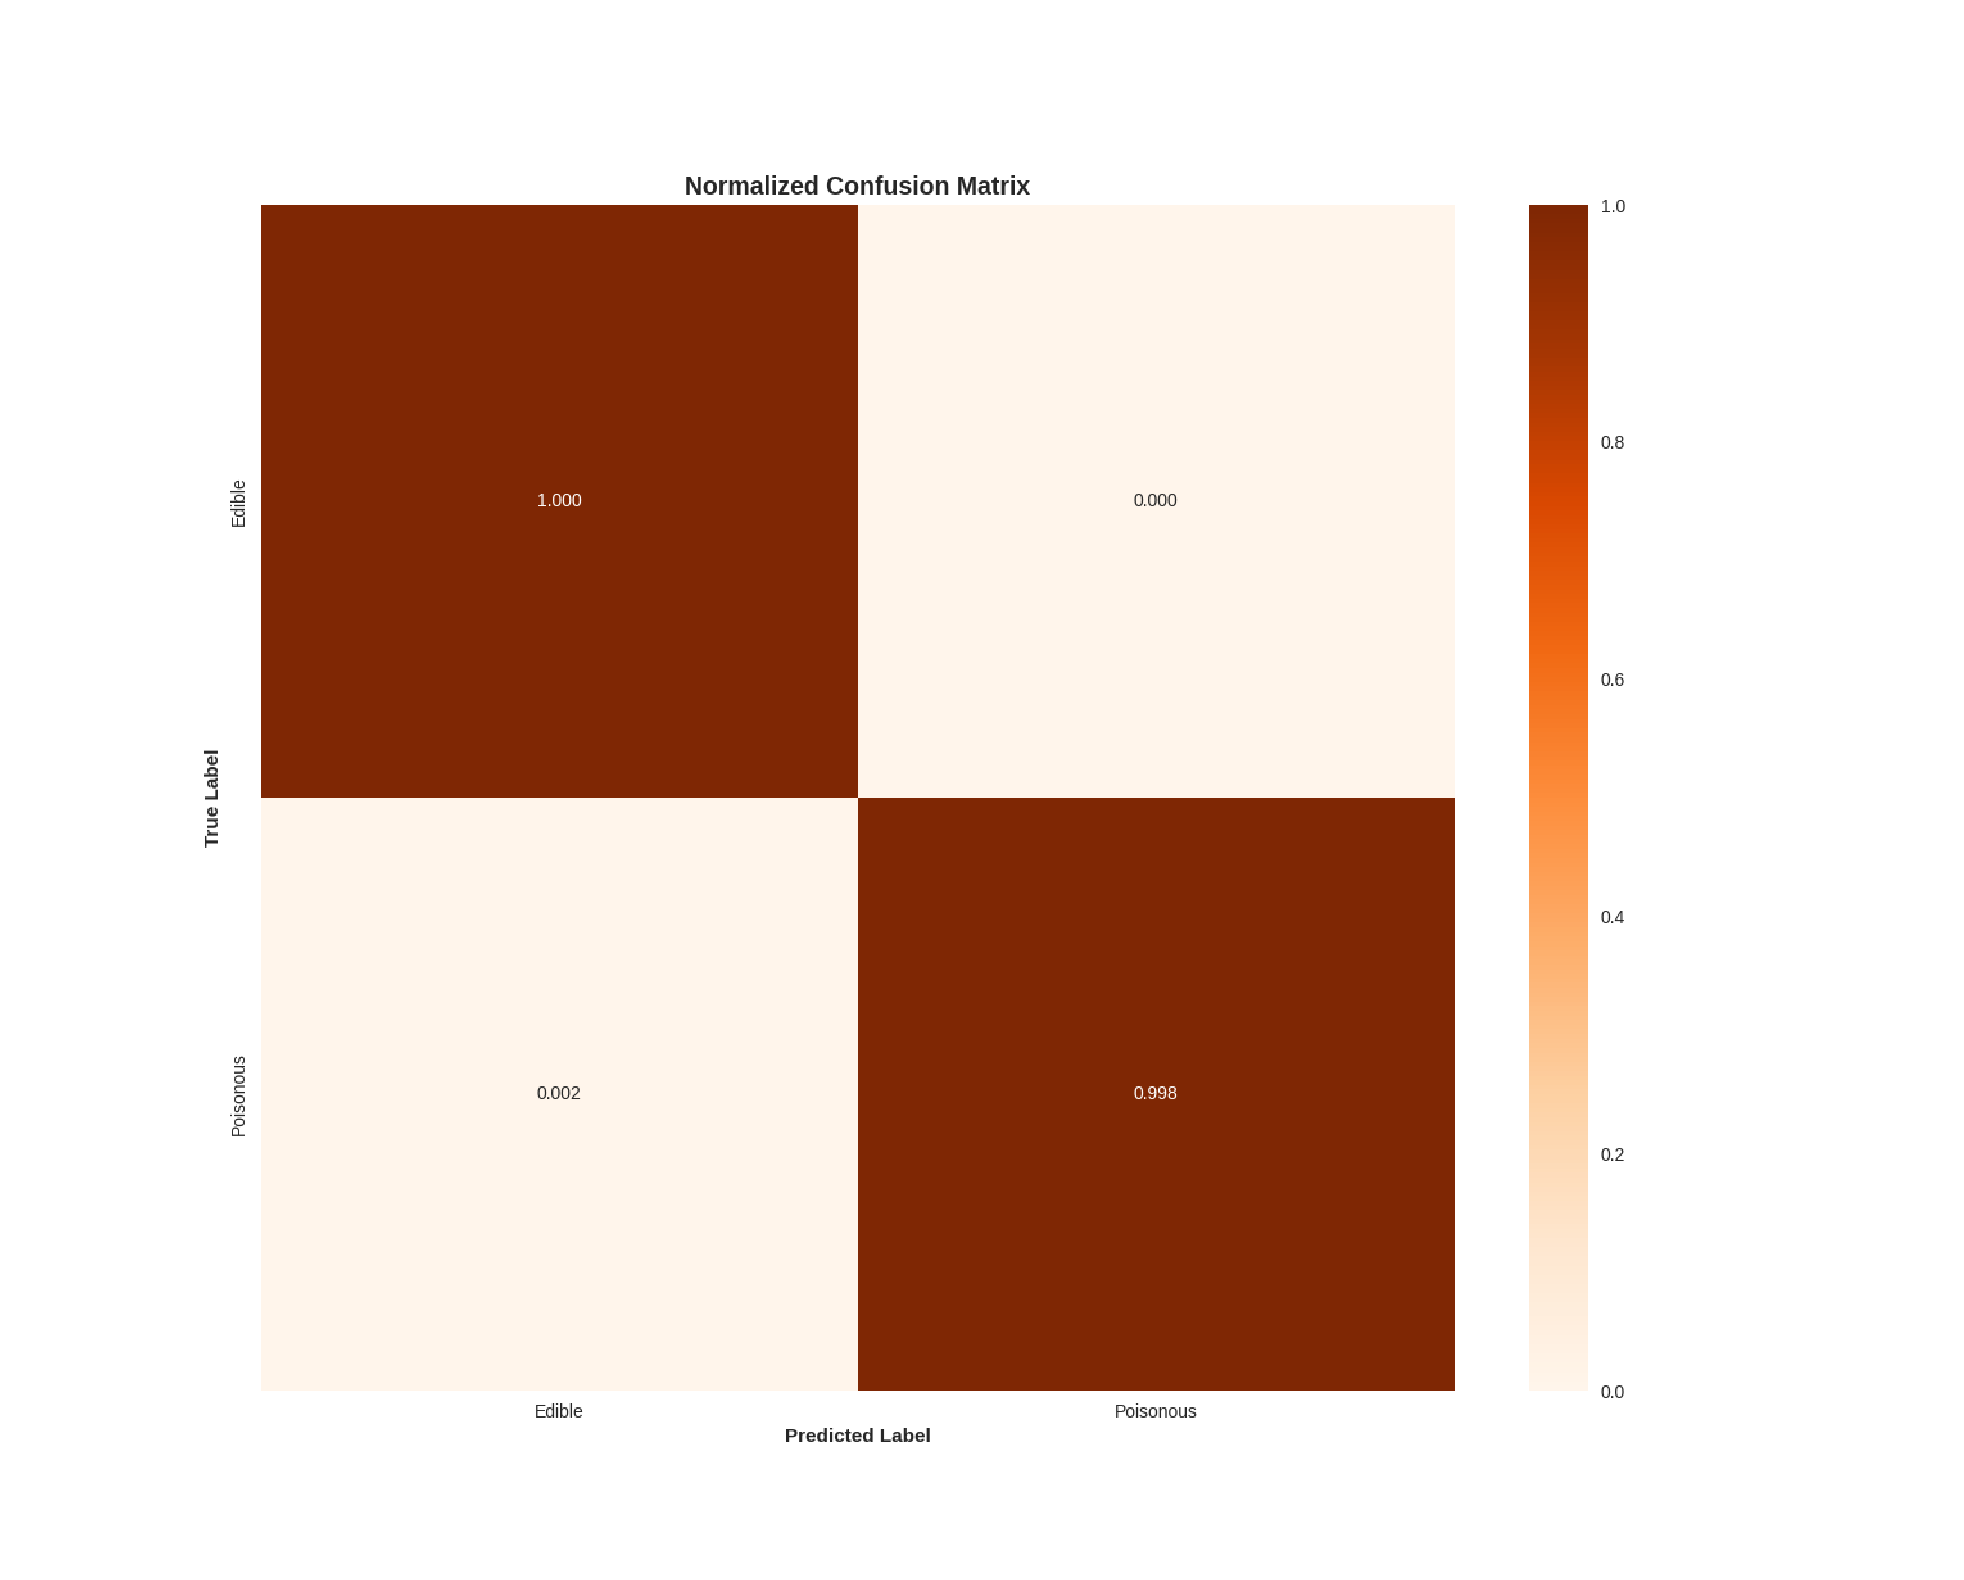

In [39]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/logreg_confusion_matrix_10.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

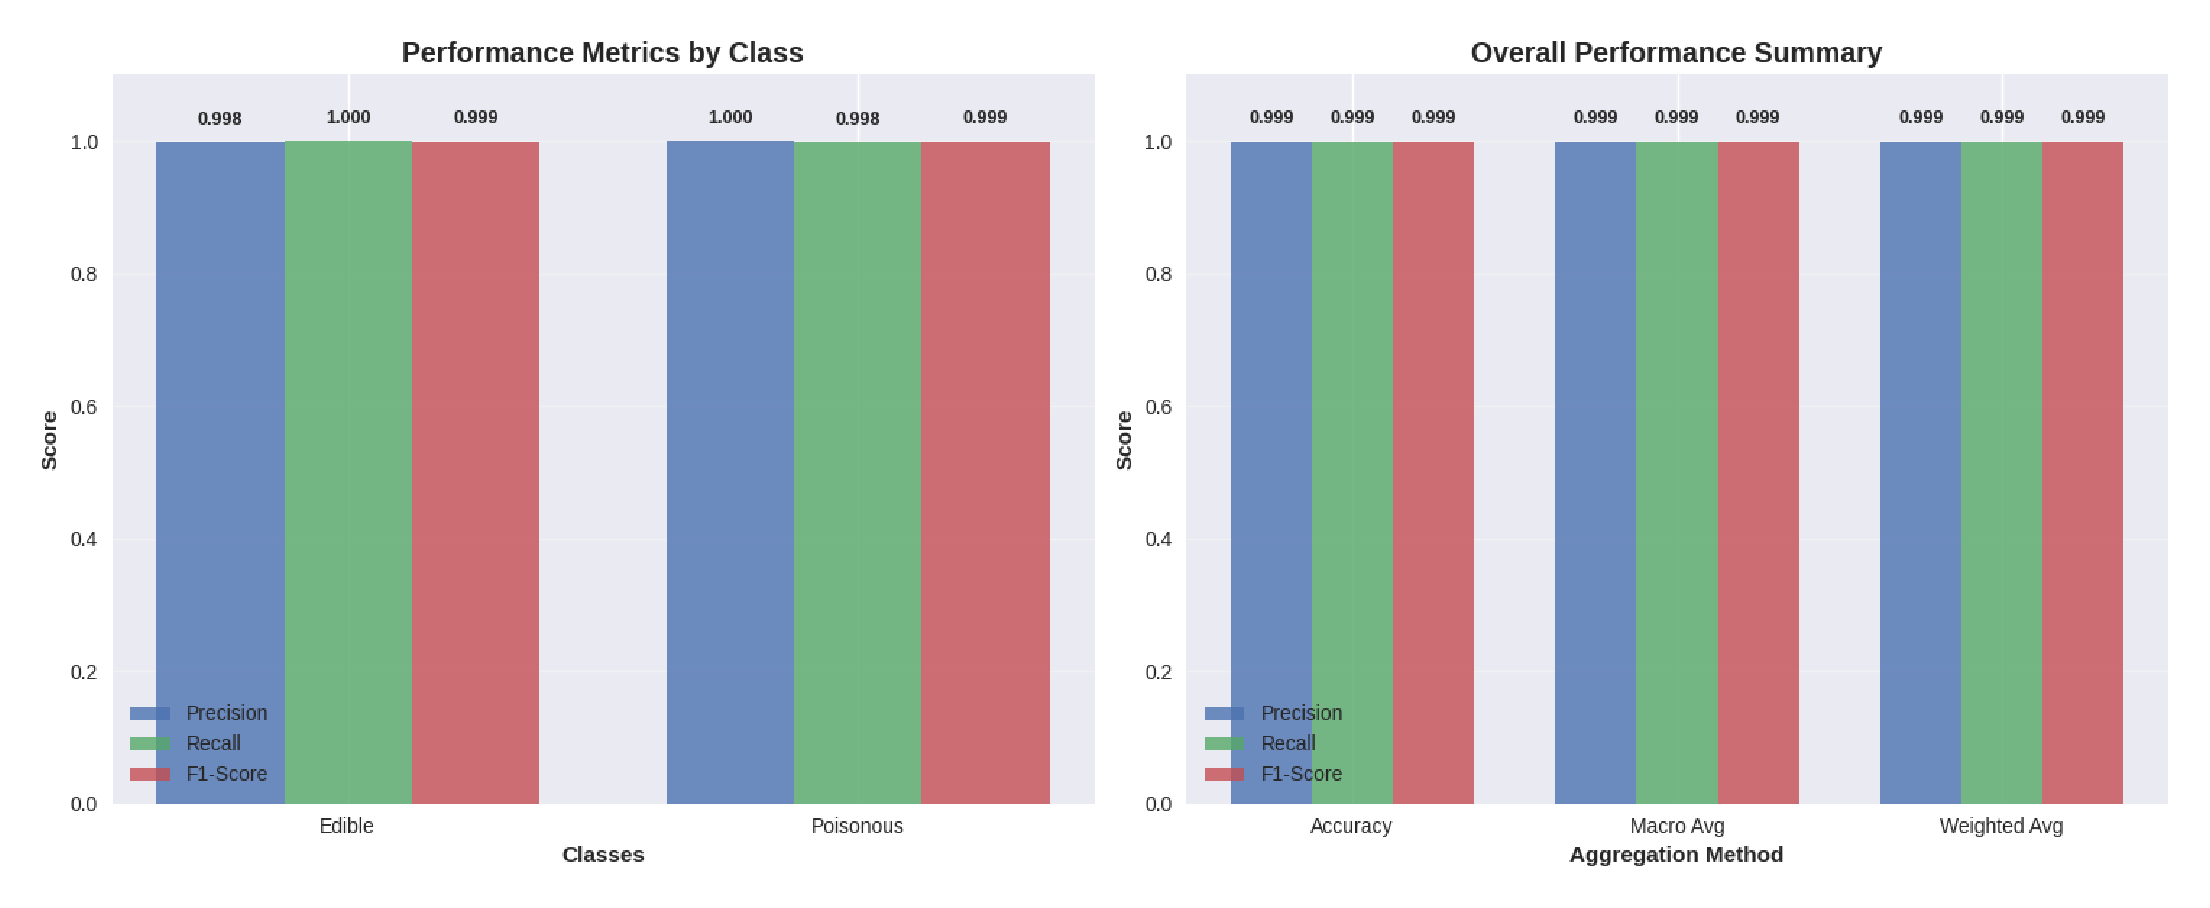

In [20]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/logreg_overall_10.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>Near perfect classification</i>

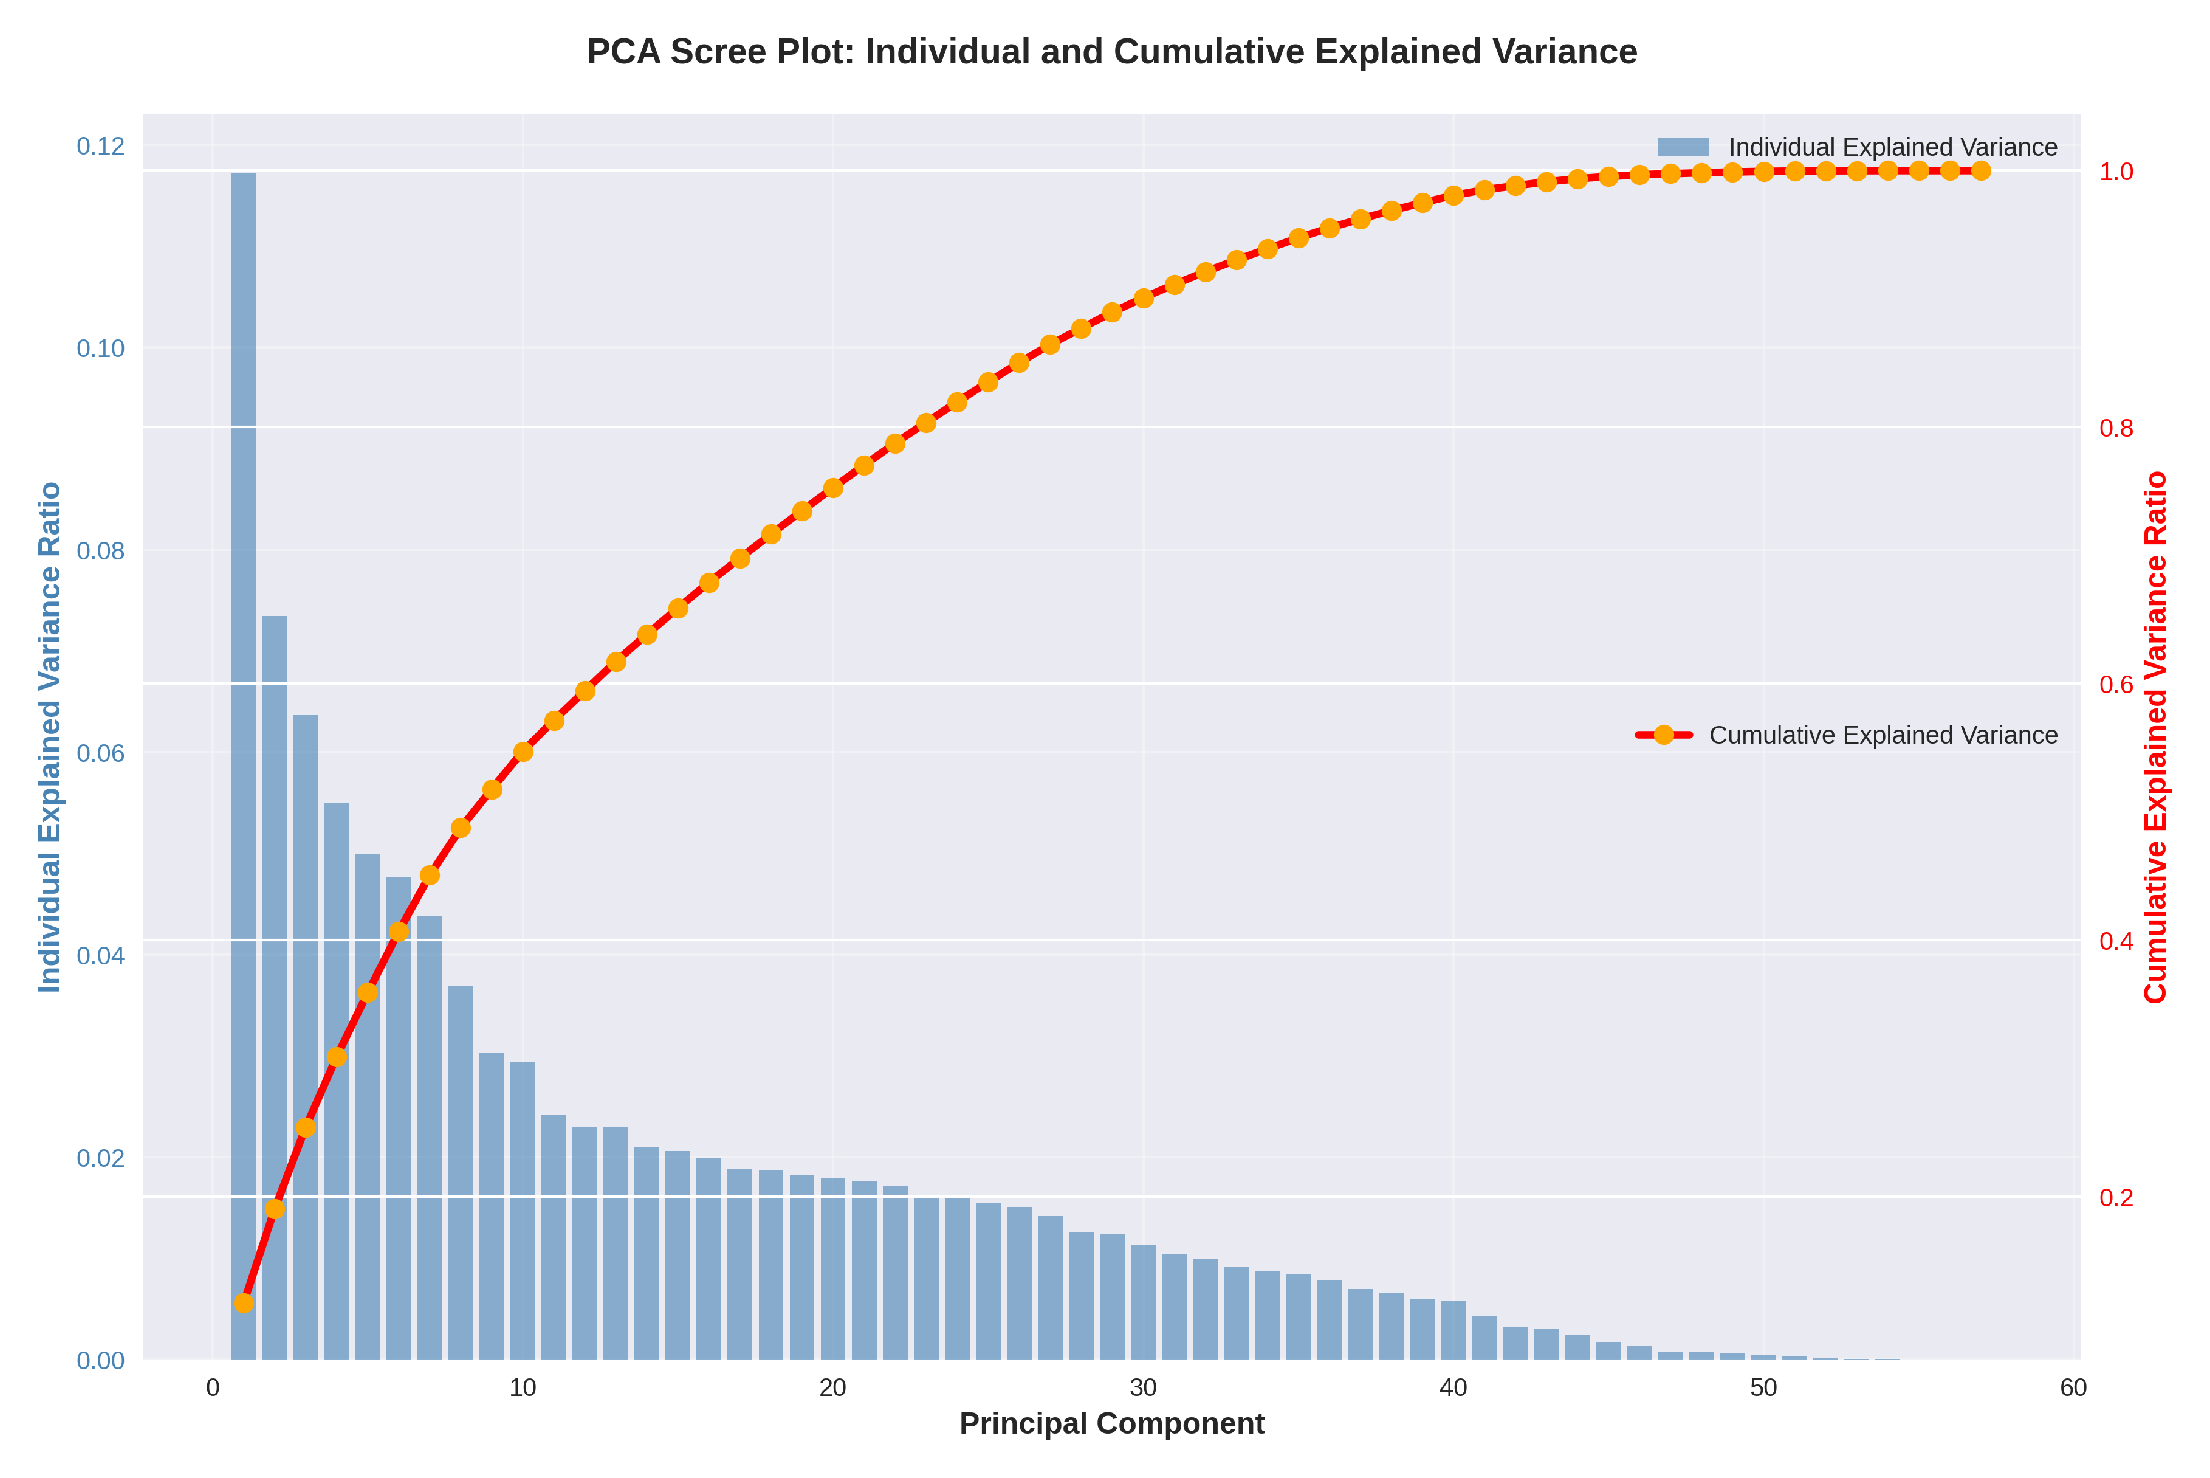

In [18]:
import matplotlib.pyplot as plt
from PIL import Image

# Open image with PIL
img = Image.open('images/pca_scree_plot_10.png')
# Display with matplotlib
plt.figure(figsize=(14, 10), dpi=200)
plt.imshow(img, interpolation='nearest')
plt.axis('off')  # Optional: hide axes
plt.show()

<i>In the above figure, The first component calculates a very high percentage of variance, as well as the second component. To explain >90% of the variance, we need at least 20 components.</i>

In [15]:
with open('total_results.json', 'w') as f:
    json.dump(total_results, f)

# Final Results

We shall now compare the results obtained by our experiment

In [40]:
with open('results/total_results.json', 'r') as f:
    data = json.load(f)

In [41]:
norms = [data[i]['norm'] for i in data]
pca = [data[i]['pca'] for i in data]

### Within Dataset comparison between LogReg and PCA

In [26]:
accuracies = [(i['accuracy'], j['accuracy']) for i, j in zip(norms, pca)]
precisions = [(i['precision'], j['precision']) for i, j in zip(norms, pca)]
recalls = [(i['recall'], j['recall']) for i, j in zip(norms, pca)]
f1s = [(i['f1'], j['f1']) for i, j in zip(norms, pca)]
pos_class = [
    (i['classification_report']['Edible'], j['classification_report']['Edible'])
    for i, j in zip(norms, pca)
]
neg_class = [
    (i['classification_report']['Poisonous'], j['classification_report']['Poisonous'])
    for i, j in zip(norms, pca)
]

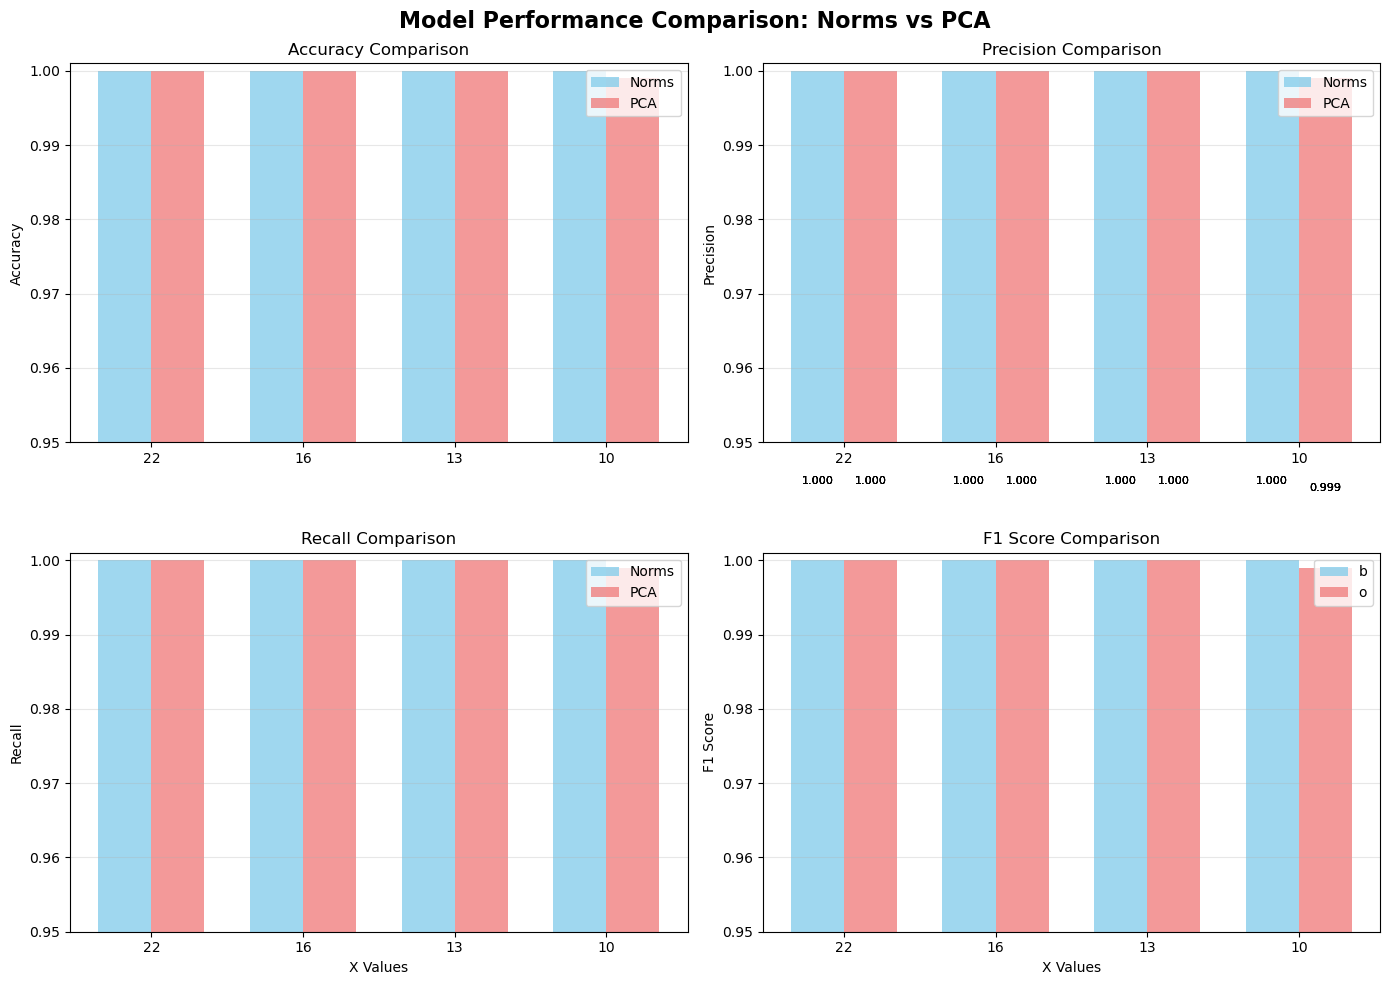

In [ ]:
accuracies = [(i['accuracy'], j['accuracy']) for i, j in zip(norms, pca)]
precisions = [(i['precision'], j['precision']) for i, j in zip(norms, pca)]
recalls = [(i['recall'], j['recall']) for i, j in zip(norms, pca)]
f1s = [(i['f1'], j['f1']) for i, j in zip(norms, pca)]

norms_acc, pca_acc = zip(*accuracies)
norms_prec, pca_prec = zip(*precisions)
norms_rec, pca_rec = zip(*recalls)
norms_f1, pca_f1 = zip(*f1s)

x = [22, 16, 13, 10]
x_pos = np.arange(len(x))
width = 0.35

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Model Performance Comparison: Norms vs PCA', fontsize=16, fontweight='bold')

# Accuracy subplot
bar1 = axes[0, 0].bar(x_pos - width/2, norms_acc, width, label='Norms', color='skyblue', alpha=0.8)
bar2 = axes[0, 0].bar(x_pos + width/2, pca_acc, width, label='PCA', color='lightcoral', alpha=0.8)
axes[0, 0].set_ylim(0.95, 1.001)
axes[0, 0].set_yticks(np.arange(0.95, 1.001, 0.01))
axes[0, 0].set_title('Accuracy Comparison')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(x)
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Precision subplot
bar3 = axes[0, 1].bar(x_pos - width/2, norms_prec, width, label='Norms', color='skyblue', alpha=0.8)
bar4 = axes[0, 1].bar(x_pos + width/2, pca_prec, width, label='PCA', color='lightcoral', alpha=0.8)
axes[0, 1].set_title('Precision Comparison')
axes[0, 1].set_ylim(0.95, 1.001)
axes[0, 0].set_yticks(np.arange(0.95, 1.001, 0.01))
axes[0, 1].set_ylabel('Precision')
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(x)
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Recall subplot
bar5 = axes[1, 0].bar(x_pos - width/2, norms_rec, width, label='Norms', color='skyblue', alpha=0.8)
bar6 = axes[1, 0].bar(x_pos + width/2, pca_rec, width, label='PCA', color='lightcoral', alpha=0.8)
axes[1, 0].set_title('Recall Comparison')
axes[1, 0].set_ylim(0.95, 1.001) 
axes[0, 0].set_yticks(np.arange(0.95, 1.001, 0.01))
axes[1, 0].set_xlabel('X Values')
axes[1, 0].set_ylabel('Recall')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(x)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3, axis='y')

# F1 Score subplot
bar7 = axes[1, 1].bar(x_pos - width/2, norms_f1, width, label='Norms', color='skyblue', alpha=0.8)
bar8 = axes[1, 1].bar(x_pos + width/2, pca_f1, width, label='PCA', color='lightcoral', alpha=0.8)
axes[1, 1].set_title('F1 Score Comparison')
axes[1, 1].set_xlabel('X Values')
axes[1, 1].set_ylim(0.95, 1.001) 
axes[0, 0].set_yticks(np.arange(0.95, 1.001, 0.01))
axes[1, 1].set_ylabel('F1 Score')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(x)
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3, axis='y')

bars = [zip(bar1, norms_acc), zip(bar2, pca_acc),
        zip(bar3, norms_prec), zip(bar4, pca_prec),
        zip(bar5, norms_rec), zip(bar6, pca_rec),
        zip(bar7, norms_f1), zip(bar8, pca_f1)]
for i in bars:
    for bar, value in i:
        axes[1, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{value:.3f}', 
            ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig('images/norm_vs_pca.png')
plt.show()

We see that there is no change in the accuracy of the model by reducing its features. In fact, PCA has further damaged the accuracy to 99.96%. This is because the features present in the original dataset were discriminative enough to completely split the two classes (e.g there were multiple categories as seen in the exploratory data analysis which were completely biased towards one class). In this case, there is no special gain attained by the Logistic Regression model by using the PCA transformation.

However, by doing PCA, we greatly decrease the dimensionality of the data without a considerable decrease in accuracy. This is also true by our empirical analysis of redundant features. The original data of being 23 dimensions (which scales to 95 after encoding) can be succintly represented by 36 dimensions (after encoding and considering 95% variance of data) which amounts to a reduction of 37.8%.

### PCA across the datasets

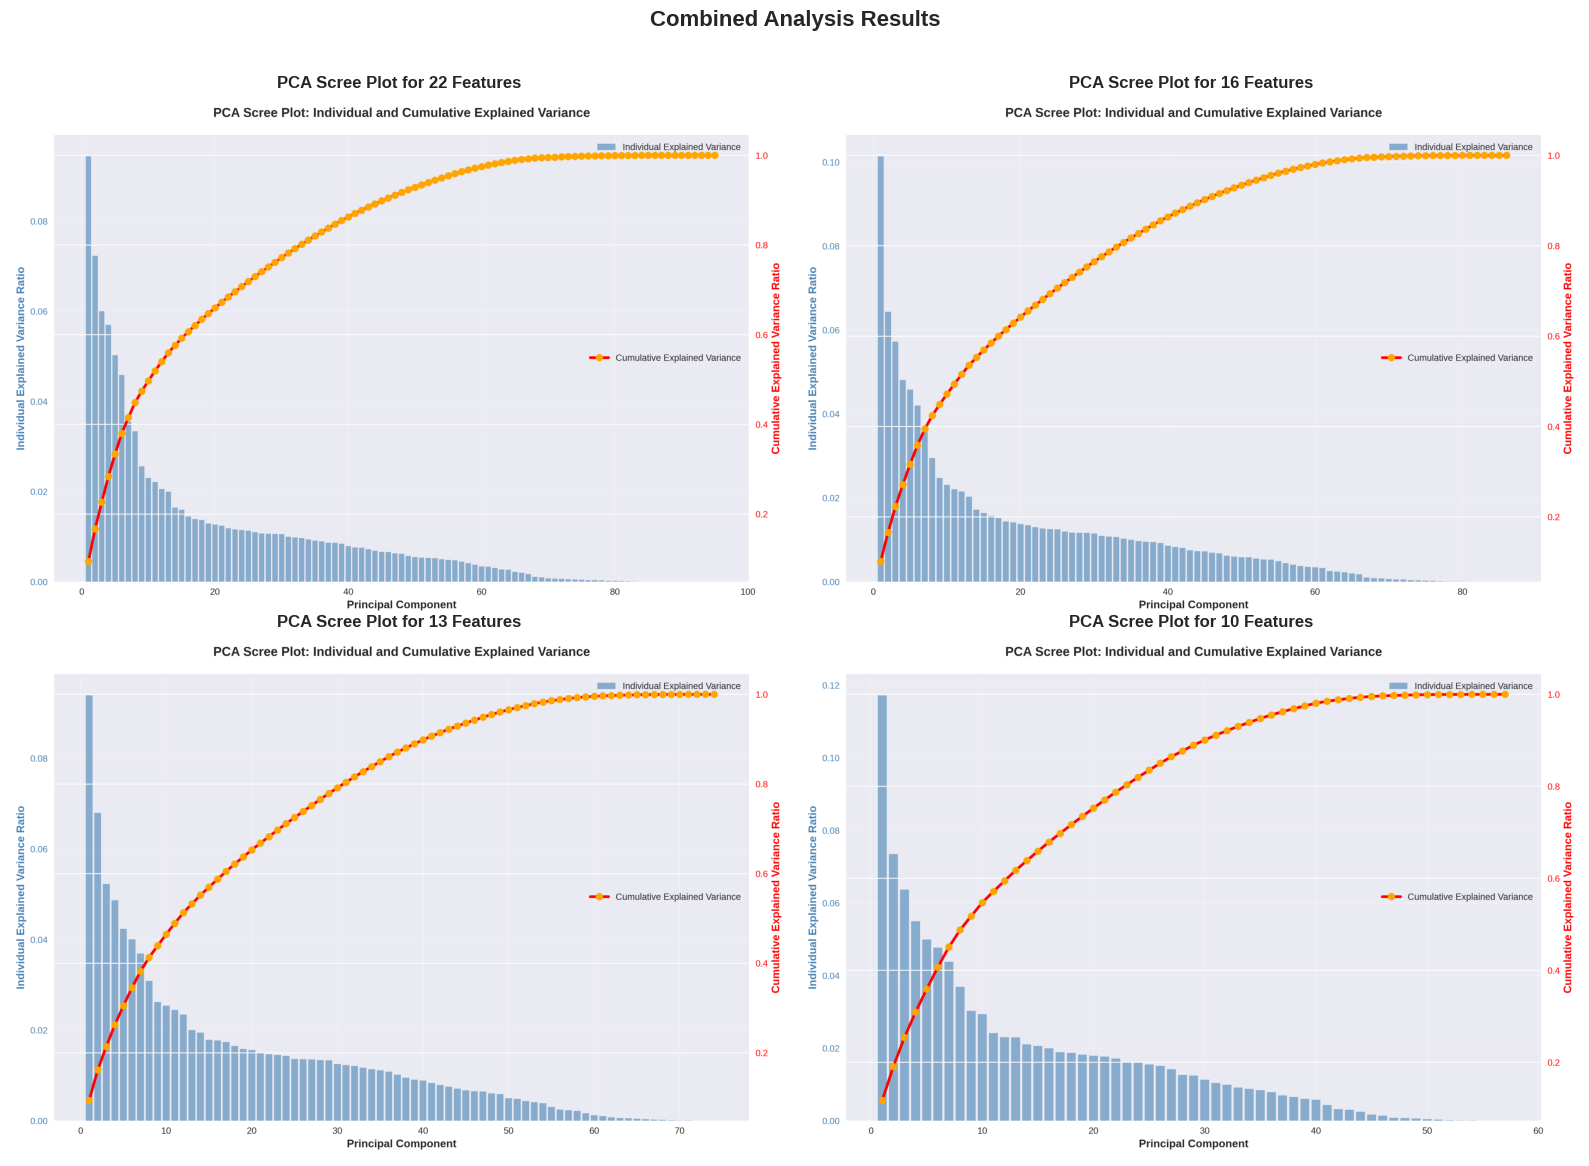

In [42]:
def plot_four_figures(image_paths, titles=None, figsize=(16, 12)):
    """
    Plot 4 existing figures from disk in a 2x2 layout.
    
    Parameters:
    -----------
    image_paths : list
        List of 4 image file paths (strings or Path objects)
    titles : list, optional
        List of 4 titles for each subplot
    figsize : tuple, optional
        Figure size (width, height)
    """
    
    if len(image_paths) != 4:
        raise ValueError("Exactly 4 image paths are required")
    
    # Create 2x2 subplots
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    fig.suptitle('Combined Analysis Results', fontsize=16, fontweight='bold', y=0.98)
    
    # Flatten axes for easier indexing
    axes = axes.flatten()
    
    # Load and display each image
    for i, (img_path, ax) in enumerate(zip(image_paths, axes)):
        try:
            # Load the image
            img = mpimg.imread(img_path)
            
            # Display the image
            ax.imshow(img)
            ax.axis('off')  # Remove axes
            
            # Add title if provided
            if titles and i < len(titles):
                ax.set_title(titles[i], fontsize=12, fontweight='bold', pad=10)
                
        except FileNotFoundError:
            # Handle missing files
            ax.text(0.5, 0.5, f'Image not found:\n{img_path}', 
                   ha='center', va='center', transform=ax.transAxes,
                   fontsize=10, bbox=dict(boxstyle='round', facecolor='lightcoral'))
            ax.set_title(f'Missing: {Path(img_path).name}', fontsize=10)
            
        except Exception as e:
            # Handle other errors
            ax.text(0.5, 0.5, f'Error loading:\n{str(e)}', 
                   ha='center', va='center', transform=ax.transAxes,
                   fontsize=10, bbox=dict(boxstyle='round', facecolor='lightyellow'))
    
    # Adjust layout to prevent overlap
    plt.tight_layout(rect=[0, 0, 1, 0.96])  # Leave space for main title

# Example usage:
# Replace these with your actual image file paths
image_paths = [
    'images/pca_scree_plot_22.png',
    'images/pca_scree_plot_16.png',
    'images/pca_scree_plot_13.png',
    'images/pca_scree_plot_10.png',
]

# Optional: Add titles for each subplot
titles = [
    'PCA Scree Plot for 22 Features',
    'PCA Scree Plot for 16 Features',
    'PCA Scree Plot for 13 Features',
    'PCA Scree Plot for 10 Features',
]

# Create the combined plot
plot_four_figures(image_paths, titles)

# Optional: Save the combined figure
plt.savefig('images/combined_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

<i>What we observe is as we reduce the number of features required to be processed by PCA, the number of features required to reach 95% of variance has also decreased by nearly half. However, the individual variance distribution remains roughly the same.</i>

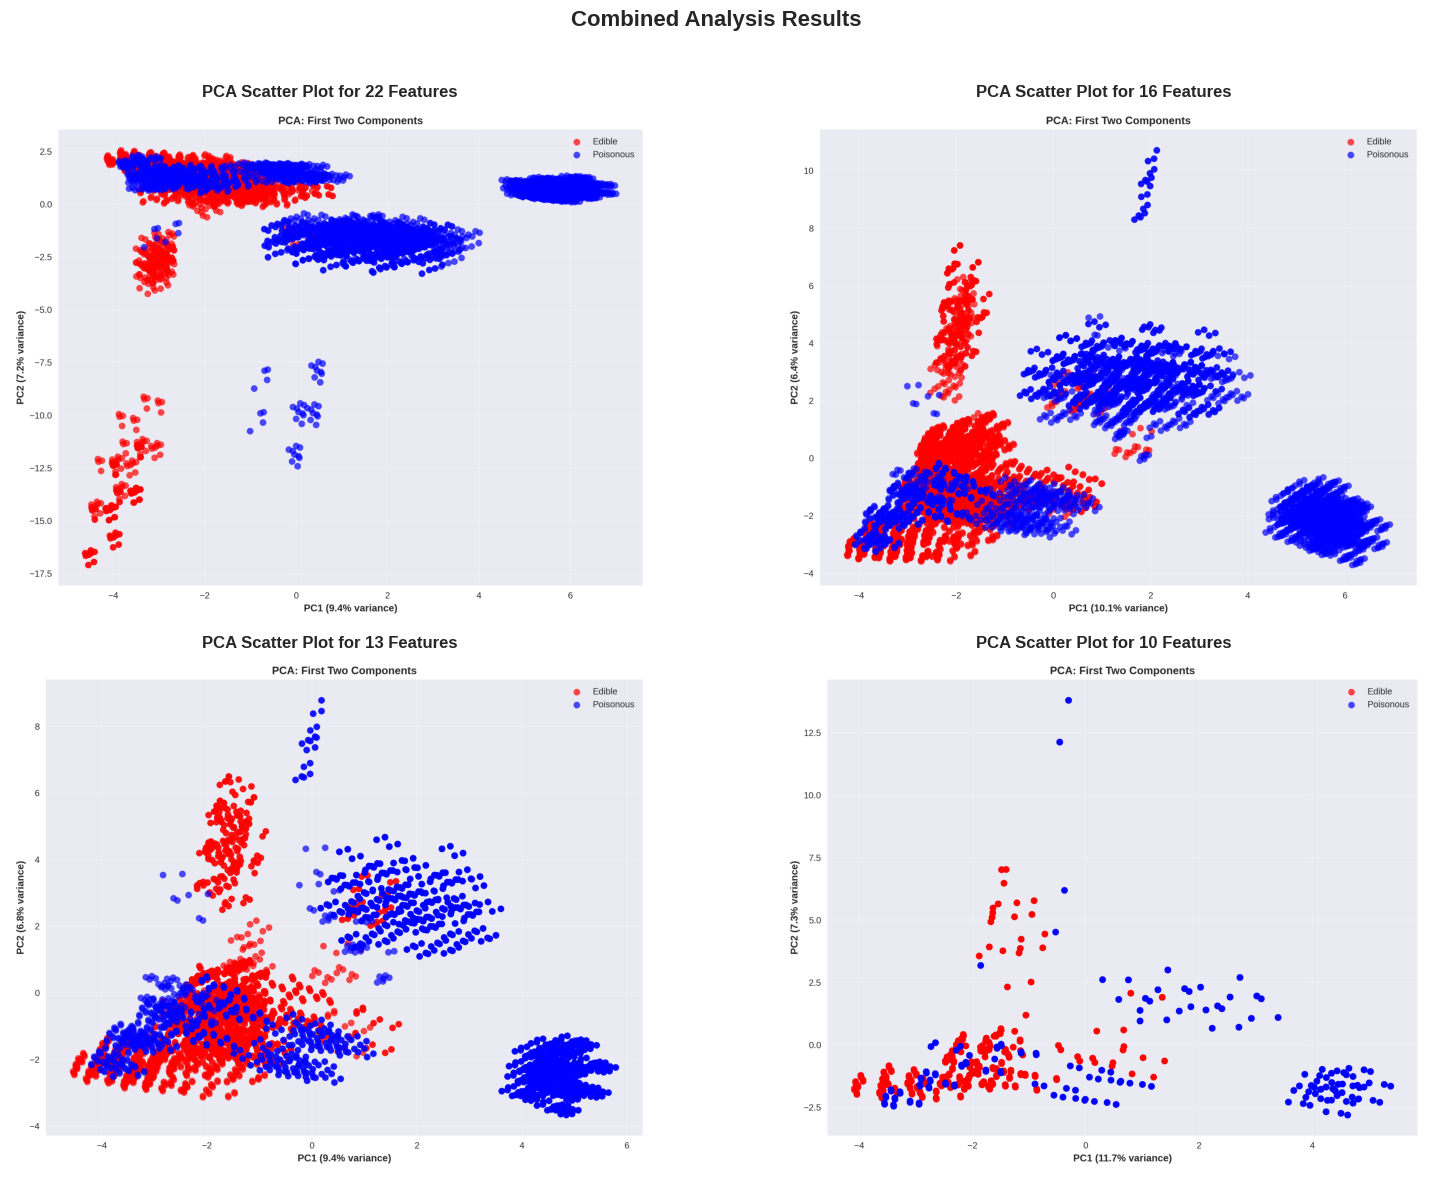

In [43]:
def plot_four_figures(image_paths, titles=None, figsize=(16, 12)):
    """
    Plot 4 existing figures from disk in a 2x2 layout.
    
    Parameters:
    -----------
    image_paths : list
        List of 4 image file paths (strings or Path objects)
    titles : list, optional
        List of 4 titles for each subplot
    figsize : tuple, optional
        Figure size (width, height)
    """
    
    if len(image_paths) != 4:
        raise ValueError("Exactly 4 image paths are required")
    
    # Create 2x2 subplots
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    fig.suptitle('Combined Analysis Results', fontsize=16, fontweight='bold', y=0.98)
    
    # Flatten axes for easier indexing
    axes = axes.flatten()
    
    # Load and display each image
    for i, (img_path, ax) in enumerate(zip(image_paths, axes)):
        try:
            # Load the image
            img = mpimg.imread(img_path)
            
            # Display the image
            ax.imshow(img)
            ax.axis('off')  # Remove axes
            
            # Add title if provided
            if titles and i < len(titles):
                ax.set_title(titles[i], fontsize=12, fontweight='bold', pad=10)
                
        except FileNotFoundError:
            # Handle missing files
            ax.text(0.5, 0.5, f'Image not found:\n{img_path}', 
                   ha='center', va='center', transform=ax.transAxes,
                   fontsize=10, bbox=dict(boxstyle='round', facecolor='lightcoral'))
            ax.set_title(f'Missing: {Path(img_path).name}', fontsize=10)
            
        except Exception as e:
            # Handle other errors
            ax.text(0.5, 0.5, f'Error loading:\n{str(e)}', 
                   ha='center', va='center', transform=ax.transAxes,
                   fontsize=10, bbox=dict(boxstyle='round', facecolor='lightyellow'))
    
    # Adjust layout to prevent overlap
    plt.tight_layout(rect=[0, 0, 1, 0.96])  # Leave space for main title

# Example usage:
# Replace these with your actual image file paths
image_paths = [
    'images/pca_scatter_plot_22.png',
    'images/pca_scatter_plot_16.png',
    'images/pca_scatter_plot_13.png',
    'images/pca_scatter_plot_10.png',
]

# Optional: Add titles for each subplot
titles = [
    'PCA Scatter Plot for 22 Features',
    'PCA Scatter Plot for 16 Features',
    'PCA Scatter Plot for 13 Features',
    'PCA Scatter Plot for 10 Features',
]

# Create the combined plot
plot_four_figures(image_paths, titles)

# Optional: Save the combined figure
plt.savefig('images/combined_analysis1.png', dpi=300, bbox_inches='tight')
plt.show()

<i>The density of the points has decreased, with plot 1, 2, 3 (clockwise) share similar regions hence distributions.</i>